In [1]:
# ==========================================
# LOCAL PROJECT SETUP
# ==========================================

import os
import numpy as np
import librosa
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

# Paths
PROJECT_PATH = r'E:\Musical Instrument Recognition'
DATASET_PATH = r'E:\Musical Instrument Recognition\IRMAS-TrainingData\IRMAS-TrainingData'
MODEL_PATH = r'E:\Musical Instrument Recognition\best_cnn_model.keras'

# Load trained CNN model
best_model = tf.keras.models.load_model(MODEL_PATH)

# Recreate label encoder
instrument_classes = [
    'cel', 'cla', 'flu', 'gac', 'gel',
    'org', 'pia', 'sax', 'tru', 'vio', 'voi'
]

label_encoder = LabelEncoder()
label_encoder.fit(instrument_classes)

# DSP preprocessing function
def extract_mel_spectrogram(file_path):

    y, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True
    )

    target_length = 22050 * 3

    if len(y) < target_length:
        y = np.pad(
            y,
            (0, target_length - len(y))
        )
    else:
        y = y[:target_length]

    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window='hann'
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db

print("LOCAL PROJECT READY")
print("TensorFlow:", tf.__version__)
print("Model parameters:", best_model.count_params())
print("Classes:", label_encoder.classes_)

LOCAL PROJECT READY
TensorFlow: 2.21.0
Model parameters: 111499
Classes: ['cel' 'cla' 'flu' 'gac' 'gel' 'org' 'pia' 'sax' 'tru' 'vio' 'voi']


In [1]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
E:\Musical Instrument Recognition\.venv\Scripts\python.exe

Python version:
3.12.5 (tags/v3.12.5:ff3bc82, Aug  6 2024, 20:45:27) [MSC v.1940 64 bit (AMD64)]


In [5]:
import os

PROCESSED_DATA_PATH = r'E:\Musical Instrument Recognition\processed_data'

os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

print("Processed data folder:")
print(PROCESSED_DATA_PATH)

Processed data folder:
E:\Musical Instrument Recognition\processed_data


In [7]:
import tensorflow as tf
import os

MODEL_PATH = r'E:\Musical Instrument Recognition\best_cnn_model.keras'

best_model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Model parameters:", best_model.count_params())

Model loaded successfully!
Model parameters: 111499


In [8]:
from sklearn.preprocessing import LabelEncoder

instrument_classes = [
    'cel',
    'cla',
    'flu',
    'gac',
    'gel',
    'org',
    'pia',
    'sax',
    'tru',
    'vio',
    'voi'
]

label_encoder = LabelEncoder()
label_encoder.fit(instrument_classes)

print("Label encoder created successfully!")
print("Classes:")
print(label_encoder.classes_)

Label encoder created successfully!
Classes:
['cel' 'cla' 'flu' 'gac' 'gel' 'org' 'pia' 'sax' 'tru' 'vio' 'voi']


In [10]:
import os
import librosa
import numpy as np

# Correct path to the instrument folder
test_file = r'E:\Musical Instrument Recognition\IRMAS-TrainingData\IRMAS-TrainingData\tru'

# Get the first WAV file
wav_files = [
    os.path.join(test_file, f)
    for f in os.listdir(test_file)
    if f.lower().endswith('.wav')
]

test_audio = wav_files[0]

print("Testing file:")
print(test_audio)

Testing file:
E:\Musical Instrument Recognition\IRMAS-TrainingData\IRMAS-TrainingData\tru\001__[tru][nod][jaz_blu]1986__1.wav


In [11]:
def extract_mel_spectrogram(file_path):
    # Load audio
    y, sr = librosa.load(file_path, sr=22050, mono=True)

    # Keep exactly 3 seconds
    target_length = 22050 * 3

    if len(y) < target_length:
        y = np.pad(y, (0, target_length - len(y)))
    else:
        y = y[:target_length]

    # Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window='hann'
    )

    # Convert to dB
    mel_db = librosa.power_to_db(mel, ref=np.max)

    return mel_db


# Extract Mel spectrogram
mel_test = extract_mel_spectrogram(test_audio)

print("Mel spectrogram shape:", mel_test.shape)

Mel spectrogram shape: (128, 130)


In [12]:
# Prepare input
X_test_single = (mel_test + 80) / 80
X_test_single = X_test_single[np.newaxis, ..., np.newaxis]

# Predict
prediction = best_model.predict(X_test_single, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_label = label_encoder.inverse_transform([predicted_index])[0]
confidence = prediction[0][predicted_index] * 100

print("Predicted instrument:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

Predicted instrument: tru
Confidence: 73.54 %


In [15]:
test_audio = r'C:\Users\hp\Downloads\IRMAS-Sample\IRMAS-Sample\Testing\02. School Boy-9.wav'

mel_test = extract_mel_spectrogram(test_audio)

X_test_single = (mel_test + 80) / 80
X_test_single = X_test_single[np.newaxis, ..., np.newaxis]

prediction = best_model.predict(X_test_single, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_label = label_encoder.inverse_transform([predicted_index])[0]
confidence = prediction[0][predicted_index] * 100

print("Audio:", test_audio)
print("Predicted instrument:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

Audio: C:\Users\hp\Downloads\IRMAS-Sample\IRMAS-Sample\Testing\02. School Boy-9.wav
Predicted instrument: tru
Confidence: 73.57 %


In [16]:
for i, prob in enumerate(prediction[0]):
    instrument = label_encoder.inverse_transform([i])[0]
    print(f"{instrument}: {prob * 100:.2f}%")

cel: 0.00%
cla: 0.15%
flu: 0.00%
gac: 0.00%
gel: 0.04%
org: 0.00%
pia: 0.00%
sax: 26.24%
tru: 73.57%
vio: 0.00%
voi: 0.00%


In [2]:
import os

DATASET_PATH = r'E:\Musical Instrument Recognition\IRMAS-TrainingData\IRMAS-TrainingData'

print(os.listdir(DATASET_PATH))

['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'README.txt', 'sax', 'tru', 'vio', 'voi']


In [3]:
total_files = 0

for root, folders, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith('.wav'):
            total_files += 1

print("Total WAV files:", total_files)

Total WAV files: 6705


In [4]:
for folder in sorted(os.listdir(DATASET_PATH)):
    folder_path = os.path.join(DATASET_PATH, folder)

    if os.path.isdir(folder_path):
        count = sum(
            1 for file in os.listdir(folder_path)
            if file.lower().endswith('.wav')
        )
        print(folder, ":", count)

cel : 388
cla : 505
flu : 451
gac : 637
gel : 760
org : 682
pia : 721
sax : 626
tru : 577
vio : 580
voi : 778


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

print("Libraries imported successfully!")

Libraries imported successfully!


**Single Audio File DSP Preprocessing**

In [ ]:
import os

sample_audio = None

for root, folders, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith('.wav'):
            sample_audio = os.path.join(root, file)
            break
    if sample_audio is not None:
        break

print("Sample audio file:")
print(sample_audio)

Sample audio file:
/content/drive/MyDrive/DSP Project Group 4 /IRMAS-TrainingData/IRMAS-TrainingData/voi/019__[voi][dru][pop_roc]2459__3.wav


In [ ]:
y, sr = librosa.load(
    sample_audio,
    sr=22050,
    mono=True
)

print("Sampling Frequency:", sr, "Hz")
print("Number of Samples:", len(y))
print("Duration:", len(y) / sr, "seconds")

Sampling Frequency: 22050 Hz
Number of Samples: 66150
Duration: 3.0 seconds


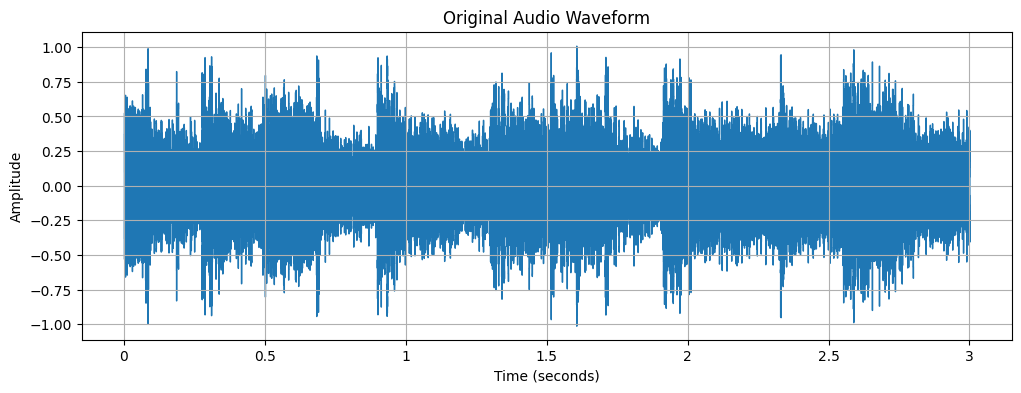

In [ ]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(
    y,
    sr=sr
)

plt.title("Original Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.show()

In [ ]:
frame_length = 2048
hop_length = 512

frames = librosa.util.frame(
    y,
    frame_length=frame_length,
    hop_length=hop_length
)

print("Original number of samples:", len(y))
print("Frame length:", frame_length)
print("Hop length:", hop_length)
print("Number of frames:", frames.shape[1])
print("Frames array shape:", frames.shape)

Original number of samples: 66150
Frame length: 2048
Hop length: 512
Number of frames: 126
Frames array shape: (2048, 126)


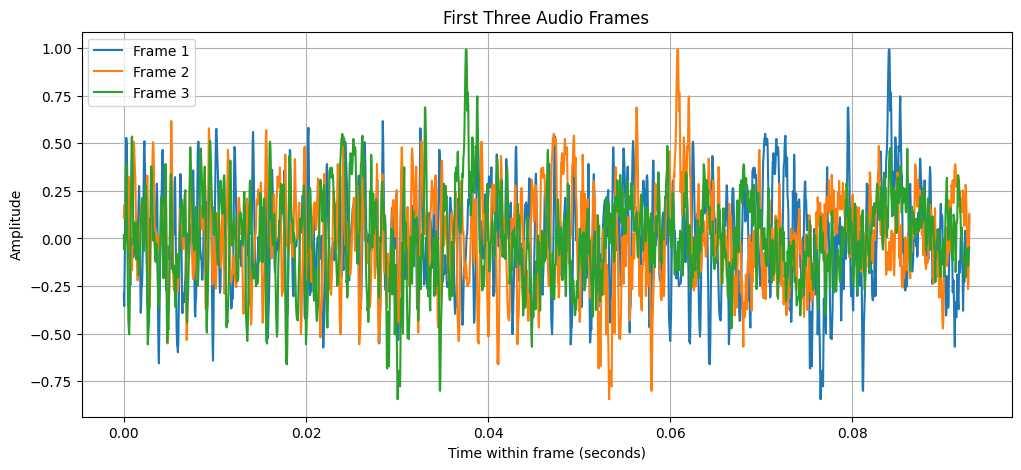

In [ ]:
plt.figure(figsize=(12, 5))

# Show the first 3 frames
for i in range(3):
    plt.plot(
        np.arange(frame_length) / sr,
        frames[:, i],
        label=f"Frame {i+1}"
    )

plt.xlabel("Time within frame (seconds)")
plt.ylabel("Amplitude")
plt.title("First Three Audio Frames")
plt.legend()
plt.grid()

plt.show()

In [ ]:
window = np.hanning(frame_length)

windowed_frames = frames * window[:, np.newaxis]

print("Window length:", len(window))
print("Windowed frames shape:", windowed_frames.shape)

Window length: 2048
Windowed frames shape: (2048, 126)


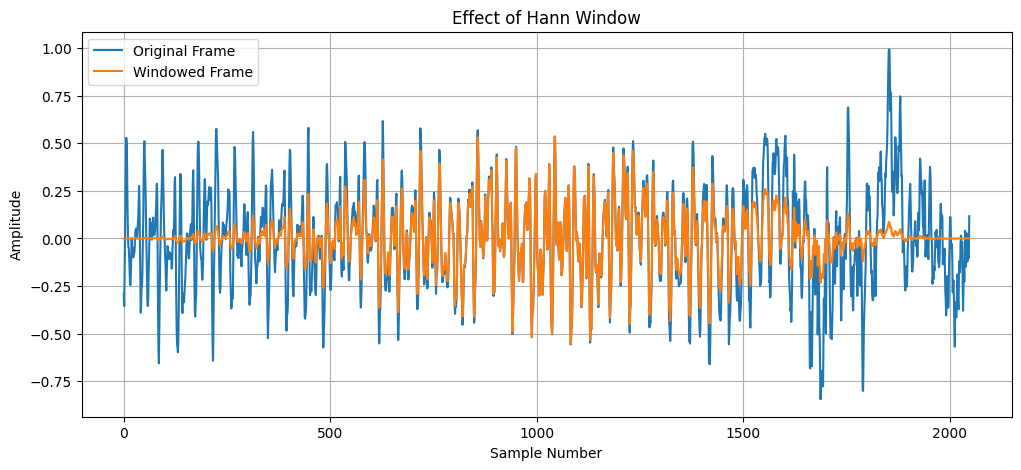

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    frames[:, 0],
    label="Original Frame"
)

plt.plot(
    windowed_frames[:, 0],
    label="Windowed Frame"
)

plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.title("Effect of Hann Window")
plt.legend()
plt.grid()

plt.show()

In [ ]:
D = librosa.stft(
    y,
    n_fft=2048,
    hop_length=512,
    window='hann'
)

print("STFT shape:", D.shape)

STFT shape: (1025, 130)


In [ ]:
magnitude = np.abs(D)

print("Magnitude shape:", magnitude.shape)

Magnitude shape: (1025, 130)


In [ ]:
D_db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)

print("dB spectrogram shape:", D_db.shape)

dB spectrogram shape: (1025, 130)


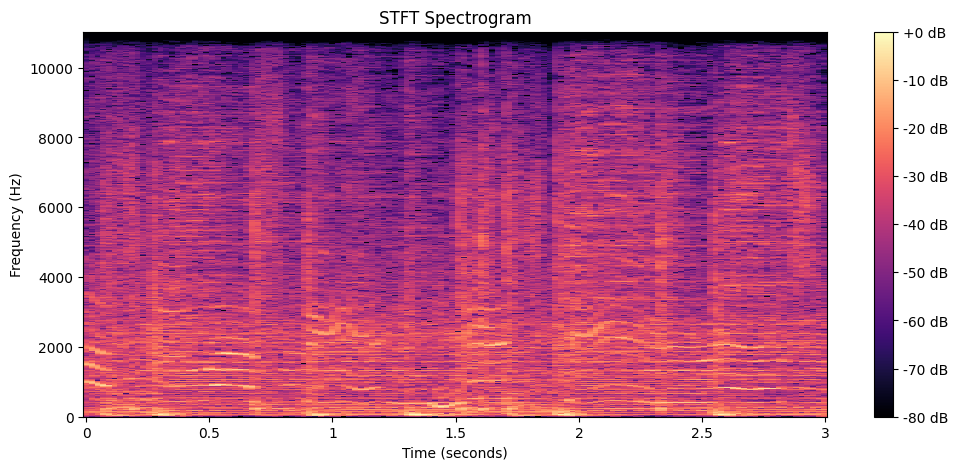

In [ ]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    D_db,
    sr=sr,
    hop_length=hop_length,
    x_axis='time',
    y_axis='hz'
)

plt.colorbar(format='%+2.0f dB')
plt.title("STFT Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.show()

In [ ]:
mel = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_fft=2048,
    hop_length=512,
    n_mels=128
)

print("Mel Spectrogram shape:", mel.shape)

Mel Spectrogram shape: (128, 130)


In [ ]:
mel_db = librosa.power_to_db(
    mel,
    ref=np.max
)

print("Mel Spectrogram in dB shape:", mel_db.shape)

Mel Spectrogram in dB shape: (128, 130)


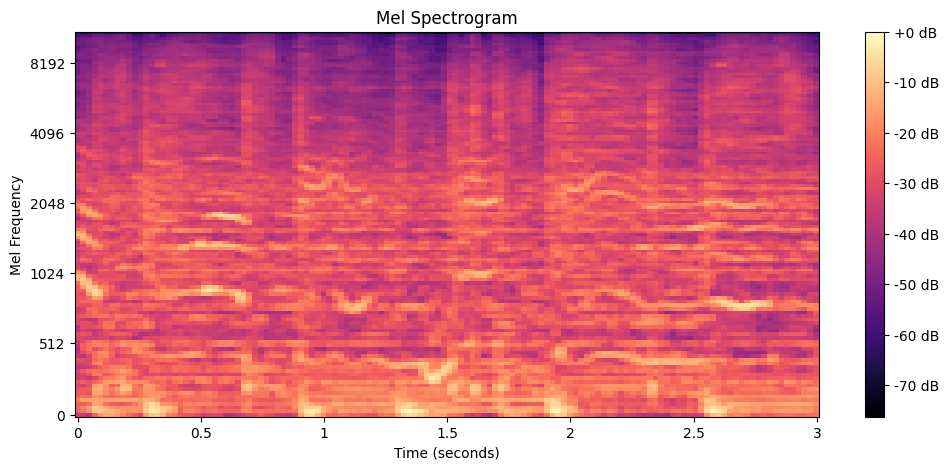

In [ ]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=hop_length,
    x_axis='time',
    y_axis='mel'
)

plt.colorbar(format='%+2.0f dB')

plt.title("Mel Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency")

plt.show()

In [ ]:
mfcc = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=40,
    n_fft=2048,
    hop_length=512,
    n_mels=128
)

print("MFCC shape:", mfcc.shape)

MFCC shape: (40, 130)


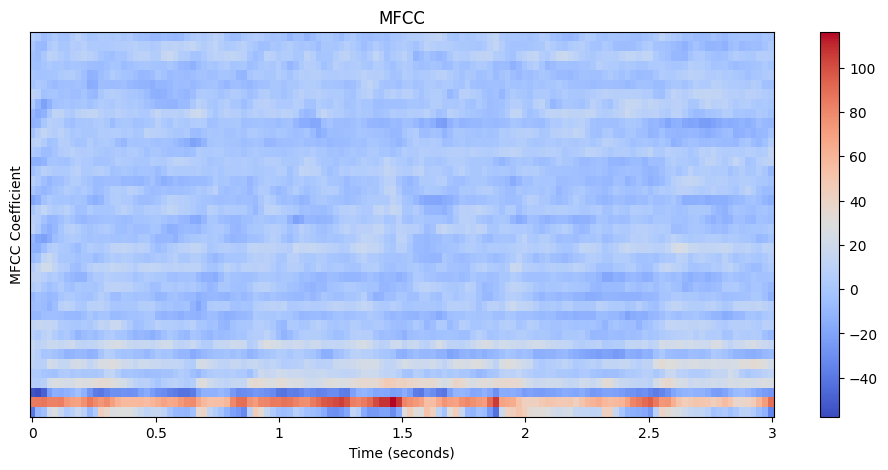

In [ ]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfcc,
    sr=sr,
    hop_length=hop_length,
    x_axis='time'
)

plt.colorbar()

plt.title("MFCC")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficient")

plt.show()

**Complete Dataset Preprocessing**

In [ ]:
import pandas as pd
import os

records = []

for root, folders, files in os.walk(DATASET_PATH):

    folder_name = os.path.basename(root)

    if folder_name in [
        'cel', 'cla', 'flu', 'gac', 'gel',
        'org', 'pia', 'sax', 'tru', 'vio', 'voi'
    ]:

        for file in files:

            if file.lower().endswith('.wav'):

                file_path = os.path.join(root, file)

                records.append([
                    file_path,
                    folder_name
                ])

df = pd.DataFrame(
    records,
    columns=['file_path', 'label']
)

print("Total audio files:", len(df))

df.head()

Total audio files: 6705


,file_path,label
0,/content/drive/MyDrive/DSP Project Group 4 /IR...,voi
1,/content/drive/MyDrive/DSP Project Group 4 /IR...,voi
2,/content/drive/MyDrive/DSP Project Group 4 /IR...,voi
3,/content/drive/MyDrive/DSP Project Group 4 /IR...,voi
4,/content/drive/MyDrive/DSP Project Group 4 /IR...,voi


In [ ]:
print("Number of audio files in each class:")
print(df['label'].value_counts().sort_index())

Number of audio files in each class:
label
cel    388
cla    505
flu    451
gac    637
gel    760
org    682
pia    721
sax    626
tru    577
vio    580
voi    778
Name: count, dtype: int64


In [ ]:
label_names = {
    'cel': 'Cello',
    'cla': 'Clarinet',
    'flu': 'Flute',
    'gac': 'Acoustic Guitar',
    'gel': 'Electric Guitar',
    'org': 'Organ',
    'pia': 'Piano',
    'sax': 'Saxophone',
    'tru': 'Trumpet',
    'vio': 'Violin',
    'voi': 'Voice'
}

df['instrument'] = df['label'].map(label_names)

print(df[['label', 'instrument']].drop_duplicates().sort_values('label'))

     label       instrument
6317   cel            Cello
5235   cla         Clarinet
3303   flu            Flute
2666   gac  Acoustic Guitar
3754   gel  Electric Guitar
1984   org            Organ
4514   pia            Piano
1358   sax        Saxophone
5740   tru          Trumpet
778    vio           Violin
0      voi            Voice


In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=42
)

# Second split: divide the remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 4693
Validation samples: 1006
Testing samples: 1006


In [ ]:
print("Training set:")
print(train_df['instrument'].value_counts().sort_index())

print("\nValidation set:")
print(val_df['instrument'].value_counts().sort_index())

print("\nTest set:")
print(test_df['instrument'].value_counts().sort_index())

Training set:
instrument
Acoustic Guitar    446
Cello              272
Clarinet           353
Electric Guitar    532
Flute              316
Organ              477
Piano              505
Saxophone          438
Trumpet            404
Violin             406
Voice              544
Name: count, dtype: int64

Validation set:
instrument
Acoustic Guitar     96
Cello               58
Clarinet            76
Electric Guitar    114
Flute               67
Organ              102
Piano              108
Saxophone           94
Trumpet             87
Violin              87
Voice              117
Name: count, dtype: int64

Test set:
instrument
Acoustic Guitar     95
Cello               58
Clarinet            76
Electric Guitar    114
Flute               68
Organ              103
Piano              108
Saxophone           94
Trumpet             86
Violin              87
Voice              117
Name: count, dtype: int64


In [ ]:
def extract_mel_spectrogram(file_path):
    # Load audio at 22050 Hz and make it mono
    y, sr = librosa.load(file_path, sr=22050, mono=True)

    # Make every audio file exactly 3 seconds
    target_length = 22050 * 3

    if len(y) < target_length:
        # Pad shorter audio with zeros
        y = np.pad(y, (0, target_length - len(y)))
    else:
        # Cut longer audio to 3 seconds
        y = y[:target_length]

    # Generate Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window='hann'
    )

    # Convert power spectrogram to decibels
    mel_db = librosa.power_to_db(mel, ref=np.max)

    return mel_db

In [ ]:
test_mel = extract_mel_spectrogram(sample_audio)

print("Mel spectrogram shape:", test_mel.shape)

Mel spectrogram shape: (128, 130)


In [ ]:
X_train = []
y_train = []

for i, row in train_df.iterrows():
    try:
        mel = extract_mel_spectrogram(row['file_path'])
        X_train.append(mel)
        y_train.append(row['label'])

    except Exception as e:
        print("Error in file:", row['file_path'])
        print(e)

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

KeyboardInterrupt: 

In [ ]:
X_train = []
y_train = []

print("Previous incomplete training data cleared.")

Previous incomplete training data cleared.


In [ ]:
import os

dataset_size = os.popen(
    "du -sh '/content/drive/MyDrive/DSP Project Group 4 /IRMAS-TrainingData/IRMAS-TrainingData'"
).read()

print("Dataset size:", dataset_size)

Dataset size: 3.4G	/content/drive/MyDrive/DSP Project Group 4 /IRMAS-TrainingData/IRMAS-TrainingData



In [ ]:
import shutil
import os

drive_dataset = '/content/drive/MyDrive/DSP Project Group 4 /IRMAS-TrainingData/IRMAS-TrainingData'
local_dataset = '/content/IRMAS-TrainingData'

print("Copying dataset to Colab local storage...")
print("This is a one-time operation and may take a few minutes.")

shutil.copytree(drive_dataset, local_dataset, dirs_exist_ok=True)

print("\nDataset copied successfully.")
print("Local dataset path:", local_dataset)

Copying dataset to Colab local storage...
This is a one-time operation and may take a few minutes.

Dataset copied successfully.
Local dataset path: /content/IRMAS-TrainingData


In [ ]:
# Change Google Drive paths to local Colab paths
df['file_path'] = df['file_path'].str.replace(
    drive_dataset,
    local_dataset,
    regex=False
)

# Update the three dataset splits as well
train_df['file_path'] = train_df['file_path'].str.replace(
    drive_dataset,
    local_dataset,
    regex=False
)

val_df['file_path'] = val_df['file_path'].str.replace(
    drive_dataset,
    local_dataset,
    regex=False
)

test_df['file_path'] = test_df['file_path'].str.replace(
    drive_dataset,
    local_dataset,
    regex=False
)

print("Paths updated to local storage.")
print(train_df.iloc[0]['file_path'])

Paths updated to local storage.
/content/IRMAS-TrainingData/cla/[cla][jaz_blu]0185__3.wav


In [ ]:
import time

X_test_speed = []
y_test_speed = []

start_time = time.time()

for i, row in train_df.head(100).iterrows():
    mel = extract_mel_spectrogram(row['file_path'])
    X_test_speed.append(mel)
    y_test_speed.append(row['label'])

elapsed_time = time.time() - start_time

print("Files processed:", len(X_test_speed))
print("Time taken:", round(elapsed_time, 2), "seconds")
print("Average time per file:", round(elapsed_time / 100, 3), "seconds")

Files processed: 100
Time taken: 2.19 seconds
Average time per file: 0.022 seconds


In [ ]:
import numpy as np
import time
from tqdm import tqdm

# Number of training samples
n_train = len(train_df)

# Pre-allocate memory
X_train = np.empty((n_train, 128, 130), dtype=np.float32)
y_train = np.empty(n_train, dtype='<U3')

start_time = time.time()

for i, (_, row) in enumerate(tqdm(train_df.iterrows(), total=n_train)):
    mel = extract_mel_spectrogram(row['file_path'])

    X_train[i] = mel.astype(np.float32)
    y_train[i] = row['label']

elapsed_time = time.time() - start_time

print("\nTraining feature extraction completed.")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Time taken:", round(elapsed_time, 2), "seconds")

100%|██████████| 4693/4693 [01:56<00:00, 40.13it/s]


Training feature extraction completed.
X_train shape: (4693, 128, 130)
y_train shape: (4693,)
Time taken: 116.94 seconds


In [ ]:
import os

processed_path = '/content/drive/MyDrive/DSP Project Group 4 /processed_data'

os.makedirs(processed_path, exist_ok=True)

np.save(os.path.join(processed_path, 'X_train.npy'), X_train)
np.save(os.path.join(processed_path, 'y_train.npy'), y_train)

print("Training features saved successfully.")
print("Saved to:", processed_path)

Training features saved successfully.
Saved to: /content/drive/MyDrive/DSP Project Group 4 /processed_data


In [ ]:
from tqdm import tqdm
import time

n_val = len(val_df)

X_val = np.empty((n_val, 128, 130), dtype=np.float32)
y_val = np.empty(n_val, dtype='<U3')

start_time = time.time()

for i, (_, row) in enumerate(tqdm(val_df.iterrows(), total=n_val)):
    mel = extract_mel_spectrogram(row['file_path'])

    X_val[i] = mel.astype(np.float32)
    y_val[i] = row['label']

elapsed_time = time.time() - start_time

print("\nValidation feature extraction completed.")
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("Time taken:", round(elapsed_time, 2), "seconds")

100%|██████████| 1006/1006 [00:22<00:00, 45.41it/s]


Validation feature extraction completed.
X_val shape: (1006, 128, 130)
y_val shape: (1006,)
Time taken: 22.16 seconds


In [ ]:
np.save(os.path.join(processed_path, 'X_val.npy'), X_val)
np.save(os.path.join(processed_path, 'y_val.npy'), y_val)

print("Validation features saved successfully.")
print("Saved to:", processed_path)

Validation features saved successfully.
Saved to: /content/drive/MyDrive/DSP Project Group 4 /processed_data


In [ ]:
from tqdm import tqdm
import time

n_test = len(test_df)

X_test = np.empty((n_test, 128, 130), dtype=np.float32)
y_test = np.empty(n_test, dtype='<U3')

start_time = time.time()

for i, (_, row) in enumerate(tqdm(test_df.iterrows(), total=n_test)):
    mel = extract_mel_spectrogram(row['file_path'])

    X_test[i] = mel.astype(np.float32)
    y_test[i] = row['label']

elapsed_time = time.time() - start_time

print("\nTest feature extraction completed.")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Time taken:", round(elapsed_time, 2), "seconds")

100%|██████████| 1006/1006 [00:22<00:00, 44.44it/s]


Test feature extraction completed.
X_test shape: (1006, 128, 130)
y_test shape: (1006,)
Time taken: 22.64 seconds


In [ ]:
np.save(os.path.join(processed_path, 'X_test.npy'), X_test)
np.save(os.path.join(processed_path, 'y_test.npy'), y_test)

print("Test features saved successfully.")
print("All three datasets are now saved.")
print("Location:", processed_path)

Test features saved successfully.
All three datasets are now saved.
Location: /content/drive/MyDrive/DSP Project Group 4 /processed_data


In [ ]:
print("===== DATASET VERIFICATION =====")

print("\nTraining:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTesting:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nNumber of classes:", len(np.unique(y_train)))
print("Classes:", sorted(np.unique(y_train)))

===== DATASET VERIFICATION =====

Training:
X_train: (4693, 128, 130)
y_train: (4693,)

Validation:
X_val: (1006, 128, 130)
y_val: (1006,)

Testing:
X_test: (1006, 128, 130)
y_test: (1006,)

Number of classes: 11
Classes: [np.str_('cel'), np.str_('cla'), np.str_('flu'), np.str_('gac'), np.str_('gel'), np.str_('org'), np.str_('pia'), np.str_('sax'), np.str_('tru'), np.str_('vio'), np.str_('voi')]


**CNN**

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Add channel dimension for CNN
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

# Convert instrument labels into numbers
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("CNN input shapes:")
print("X_train:", X_train_cnn.shape)
print("X_val:", X_val_cnn.shape)
print("X_test:", X_test_cnn.shape)

print("\nEncoded label shapes:")
print("y_train:", y_train_encoded.shape)
print("y_val:", y_val_encoded.shape)
print("y_test:", y_test_encoded.shape)

print("\nClass mapping:")
for i, name in enumerate(label_encoder.classes_):
    print(i, "=", name)

CNN input shapes:
X_train: (4693, 128, 130, 1)
X_val: (1006, 128, 130, 1)
X_test: (1006, 128, 130, 1)

Encoded label shapes:
y_train: (4693,)
y_val: (1006,)
y_test: (1006,)

Class mapping:
0 = cel
1 = cla
2 = flu
3 = gac
4 = gel
5 = org
6 = pia
7 = sax
8 = tru
9 = vio
10 = voi


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = 11

model = models.Sequential([
    layers.Input(shape=(128, 130, 1)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 130, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 130, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,419 (16.36 MB)

 Trainable params: 4,288,971 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = 11

model = models.Sequential([

    # Input
    layers.Input(shape=(128, 130, 1)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # 11 instrument classes
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 130, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 130, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,499 (435.54 KB)

 Trainable params: 111,051 (433.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN compiled successfully.")

CNN compiled successfully.


In [ ]:
# Normalize Mel spectrogram values to approximately 0 to 1

X_train_norm = (X_train_cnn + 80) / 80
X_val_norm = (X_val_cnn + 80) / 80
X_test_norm = (X_test_cnn + 80) / 80

print("Training range:", X_train_norm.min(), "to", X_train_norm.max())
print("Validation range:", X_val_norm.min(), "to", X_val_norm.max())
print("Testing range:", X_test_norm.min(), "to", X_test_norm.max())

Training range: 0.0 to 1.0
Validation range: 0.0 to 1.0
Testing range: 0.0 to 1.0


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

# Reduce learning rate when validation loss stops improving
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.000001
)

# Save the best model
model_path = os.path.join(processed_path, 'best_cnn_model.keras')

checkpoint = ModelCheckpoint(
    model_path,
    monitor='val_loss',
    save_best_only=True
)

print("Training callbacks are ready.")

Training callbacks are ready.


In [ ]:
history = model.fit(
    X_train_norm,
    y_train_encoded,
    validation_data=(X_val_norm, y_val_encoded),
    epochs=40,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.2540 - loss: 2.1473 - val_accuracy: 0.1014 - val_loss: 2.6898 - learning_rate: 0.0010
Epoch 2/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.3337 - loss: 1.9304 - val_accuracy: 0.1014 - val_loss: 3.2718 - learning_rate: 0.0010
Epoch 3/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.3976 - loss: 1.7653 - val_accuracy: 0.1014 - val_loss: 4.3836 - learning_rate: 0.0010
Epoch 4/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.4498 - loss: 1.6290 - val_accuracy: 0.2654 - val_loss: 2.2001 - learning_rate: 0.0010
Epoch 5/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 284s 2s/step - accuracy: 0.4941 - loss: 1.4907 - val_accuracy: 0.3340 - val_loss: 2.0404 - learning_rate: 0.0010
Epoch 6/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 304s 2s/step - accuracy: 0.5346 - loss: 1.3840 - val_accuracy: 0.4553 - val_loss: 1.7028 - learning_rate: 0.0010
Epoch 7/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 333s 2s/step - accuracy: 0.5645 - loss: 1.

In [ ]:
# Load the best saved CNN model
best_model = tf.keras.models.load_model(model_path)

# Evaluate on the test data
test_loss, test_accuracy = best_model.evaluate(
    X_test_norm,
    y_test_encoded,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 301ms/step - accuracy: 0.7356 - loss: 0.7806
Test Loss: 0.7806193828582764
Test Accuracy: 0.7355864644050598


In [ ]:
# Generate predictions on the test data
y_pred_prob = best_model.predict(X_test_norm)

# Convert probabilities to predicted class numbers
y_pred_encoded = np.argmax(y_pred_prob, axis=1)

print("Predictions generated.")
print("Number of predictions:", len(y_pred_encoded))

32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 295ms/step
Predictions generated.
Number of predictions: 1006


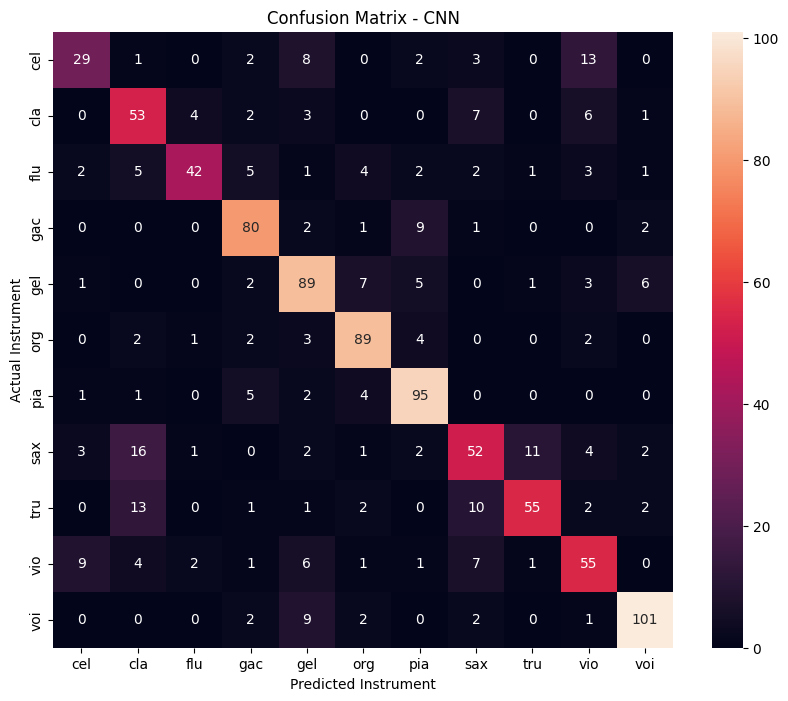

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(y_test_encoded, y_pred_encoded)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Instrument")
plt.ylabel("Actual Instrument")
plt.title("Confusion Matrix - CNN")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report - CNN")
print(
    classification_report(
        y_test_encoded,
        y_pred_encoded,
        target_names=label_encoder.classes_
    )
)

Classification Report - CNN
              precision    recall  f1-score   support

         cel       0.64      0.50      0.56        58
         cla       0.56      0.70      0.62        76
         flu       0.84      0.62      0.71        68
         gac       0.78      0.84      0.81        95
         gel       0.71      0.78      0.74       114
         org       0.80      0.86      0.83       103
         pia       0.79      0.88      0.83       108
         sax       0.62      0.55      0.58        94
         tru       0.80      0.64      0.71        86
         vio       0.62      0.63      0.62        87
         voi       0.88      0.86      0.87       117

    accuracy                           0.74      1006
   macro avg       0.73      0.72      0.72      1006
weighted avg       0.74      0.74      0.73      1006



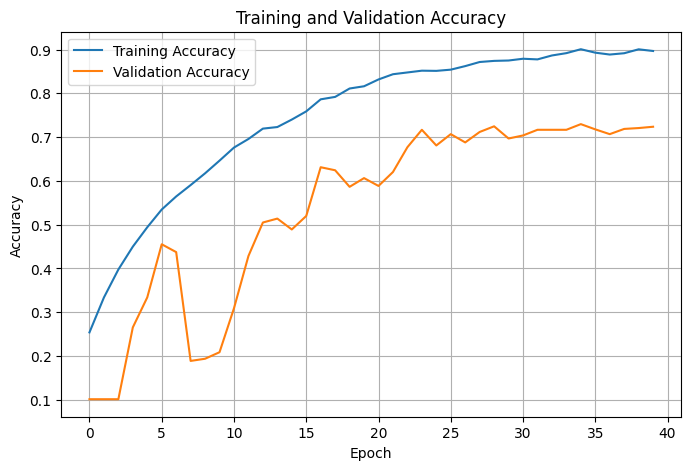

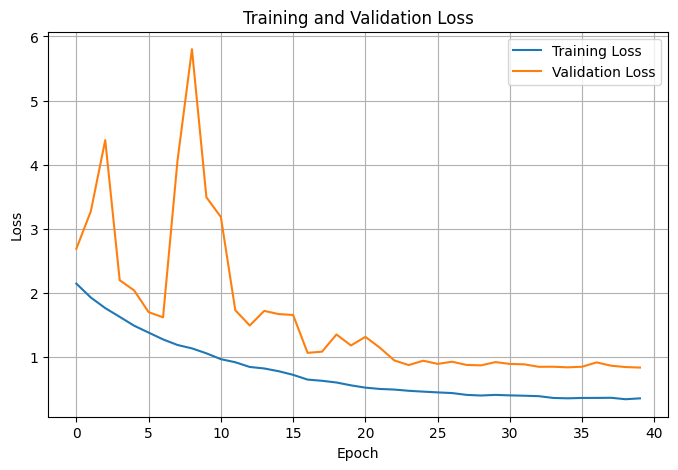

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

Saving 02. School Boy-9.wav to 02. School Boy-9.wav
   MUSICAL INSTRUMENT RECOGNITION
Audio file: 02. School Boy-9.wav
Predicted Instrument: tru
Confidence: 73.57 %


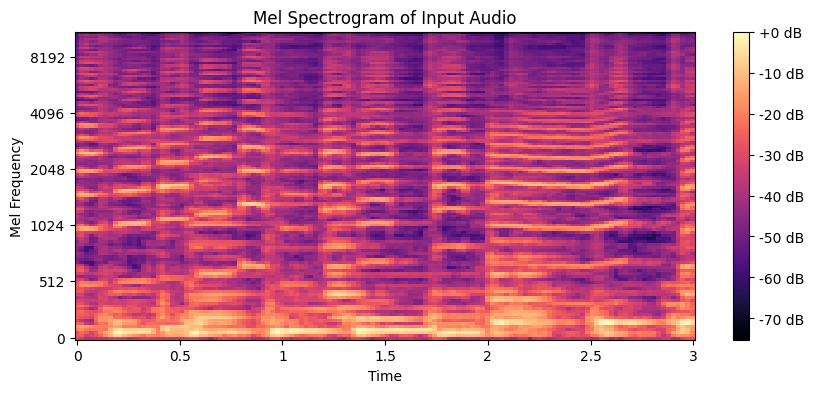

In [62]:
from google.colab import files
import numpy as np
import librosa
import matplotlib.pyplot as plt

uploaded = files.upload()

audio_file = list(uploaded.keys())[0]

y, sr = librosa.load(audio_file, sr=22050, mono=True)

target_length = 22050 * 3

if len(y) < target_length:
    y = np.pad(y, (0, target_length - len(y)))
else:
    y = y[:target_length]

mel = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_fft=2048,
    hop_length=512,
    n_mels=128,
    window='hann'
)

mel_db = librosa.power_to_db(mel, ref=np.max)

X_new = mel_db.astype(np.float32)
X_new = X_new[np.newaxis, ..., np.newaxis]

X_new_norm = (X_new + 80) / 80

prediction = best_model.predict(X_new_norm, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_label = label_encoder.inverse_transform([predicted_index])[0]

confidence = prediction[0][predicted_index] * 100

print("===================================")
print("   MUSICAL INSTRUMENT RECOGNITION")
print("===================================")
print("Audio file:", audio_file)
print("Predicted Instrument:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=512,
    x_axis='time',
    y_axis='mel'
)
plt.colorbar(format='%+2.0f dB')
plt.title("Mel Spectrogram of Input Audio")
plt.xlabel("Time")
plt.ylabel("Mel Frequency")
plt.show()

In [5]:
import os
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

PROJECT_PATH = r'E:\Musical Instrument Recognition'
PROCESSED_PATH = os.path.join(PROJECT_PATH, 'processed_data')

classes = ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']

label_encoder = LabelEncoder()
label_encoder.fit(classes)

X_train = np.load(os.path.join(PROCESSED_PATH, 'X_train.npy'))
y_train = np.load(os.path.join(PROCESSED_PATH, 'y_train.npy'))
X_val = np.load(os.path.join(PROCESSED_PATH, 'X_val.npy'))
y_val = np.load(os.path.join(PROCESSED_PATH, 'y_val.npy'))

y_train = label_encoder.transform(y_train)
y_val = label_encoder.transform(y_val)

X_train = (X_train[..., np.newaxis] + 80) / 80
X_val = (X_val[..., np.newaxis] + 80) / 80

model_deep = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 130, 1)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(11, activation='softmax')
])

model_deep.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Parameters:", model_deep.count_params())

history_deep = model_deep.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=7,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-6
        ),
        tf.keras.callbacks.ModelCheckpoint(
            os.path.join(PROCESSED_PATH, 'best_cnn_deep.keras'),
            monitor='val_loss',
            save_best_only=True
        )
    ]
)

Training data: (4693, 128, 130, 1)
Validation data: (1006, 128, 130, 1)
Parameters: 306155
Epoch 1/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.2485 - loss: 2.1876 - val_accuracy: 0.1740 - val_loss: 3.1691 - learning_rate: 0.0010
Epoch 2/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - accuracy: 0.3546 - loss: 1.9064 - val_accuracy: 0.1014 - val_loss: 5.3743 - learning_rate: 0.0010
Epoch 3/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - accuracy: 0.4238 - loss: 1.7036 - val_accuracy: 0.1083 - val_loss: 5.1090 - learning_rate: 0.0010
Epoch 4/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.4754 - loss: 1.5463 - val_accuracy: 0.2346 - val_loss: 2.8971 - learning_rate: 0.0010
Epoch 5/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 217s 1s/step - accuracy: 0.5263 - loss: 1.4035 - val_accuracy: 0.3588 - val_loss: 1.9023 - learning_rate: 0.0010
Epoch 6/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - accuracy: 0.5553 - loss: 1.2912 - val_accuracy: 0.2217 - val_loss: 3.2629 - learning_rate

In [1]:
import os
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

PROJECT_PATH = r'E:\Musical Instrument Recognition'
PROCESSED_PATH = os.path.join(PROJECT_PATH, 'processed_data')

MODEL_PATH = os.path.join(PROCESSED_PATH, 'best_cnn_deep.keras')

best_model = tf.keras.models.load_model(MODEL_PATH)

classes = ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']

label_encoder = LabelEncoder()
label_encoder.fit(classes)

print("Model loaded")
print("Parameters:", best_model.count_params())

Model loaded
Parameters: 306155


In [2]:
X_test = np.load(os.path.join(PROCESSED_PATH, 'X_test.npy'))
y_test = np.load(os.path.join(PROCESSED_PATH, 'y_test.npy'))

X_test = (X_test[..., np.newaxis] + 80) / 80
y_test = label_encoder.transform(y_test)

test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.7513
Test Accuracy: 75.25 %


In [3]:
y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

         cel       0.69      0.47      0.56        58
         cla       0.83      0.50      0.62        76
         flu       0.77      0.72      0.74        68
         gac       0.81      0.79      0.80        95
         gel       0.63      0.81      0.70       114
         org       0.83      0.88      0.85       103
         pia       0.86      0.84      0.85       108
         sax       0.68      0.60      0.64        94
         tru       0.69      0.83      0.75        86
         vio       0.59      0.69      0.63        87
         voi       0.94      0.91      0.93       117

    accuracy                           0.75      1006
   macro avg       0.75      0.73      0.73      1006
weighted avg       0.76      0.75      0.75      1006



<Figure size 900x900 with 0 Axes>

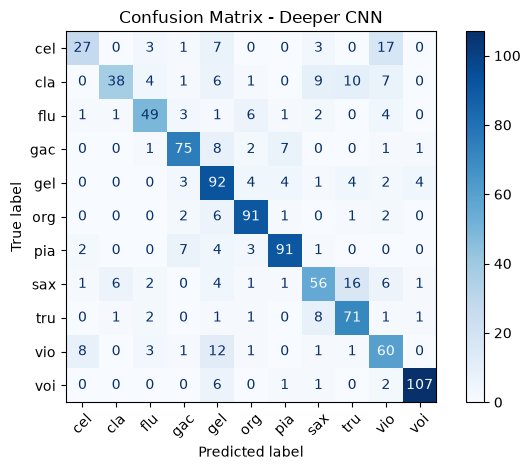

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix - Deeper CNN')
plt.tight_layout()
plt.show()

In [6]:
def predict_long_audio(file_path, top_k=1):
    y, sr = librosa.load(file_path, sr=22050, mono=True)

    segment_length = 3 * sr
    results = []

    for start in range(0, len(y), segment_length):
        segment = y[start:start + segment_length]

        if len(segment) == 0:
            continue

        if len(segment) < segment_length:
            segment = np.pad(
                segment,
                (0, segment_length - len(segment))
            )

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_fft=2048,
            hop_length=512,
            n_mels=128,
            window='hann'
        )

        mel_db = librosa.power_to_db(mel, ref=np.max)

        X = (mel_db + 80) / 80
        X = X[np.newaxis, ..., np.newaxis]

        probabilities = best_model.predict(X, verbose=0)[0]

        top_indices = np.argsort(probabilities)[::-1][:top_k]

        predictions = []

        for index in top_indices:
            predictions.append({
                'instrument': label_encoder.inverse_transform([index])[0],
                'confidence': probabilities[index] * 100
            })

        results.append({
            'start': start / sr,
            'end': min((start + segment_length) / sr, len(y) / sr),
            'predictions': predictions
        })

    return results

In [8]:
import librosa
import numpy as np

In [9]:
audio_path = r'C:\Users\hp\Downloads\IRMAS-Sample\IRMAS-Sample\Testing\02. School Boy-9.wav'

results = predict_long_audio(audio_path, top_k=2)

for result in results:
    print(
        f"{result['start']:.1f} - {result['end']:.1f} sec:"
    )

    for prediction in result['predictions']:
        print(
            f"    {prediction['instrument']} "
            f"({prediction['confidence']:.2f}%)"
        )

0.0 - 3.0 sec:
    tru (98.50%)
    sax (1.49%)
3.0 - 6.0 sec:
    sax (77.17%)
    tru (11.15%)
6.0 - 9.0 sec:
    sax (48.26%)
    gac (32.40%)
9.0 - 12.0 sec:
    tru (84.13%)
    sax (14.85%)
12.0 - 15.0 sec:
    gac (42.31%)
    sax (33.22%)
15.0 - 18.0 sec:
    tru (87.99%)
    sax (11.56%)
18.0 - 20.0 sec:
    tru (70.96%)
    sax (28.68%)


In [10]:
audio_path = r"C:\Users\hp\Downloads\IRMAS-Sample\IRMAS-Sample\Testing\12 What'll I Do - Bud Shank And Bob-4.wav"

results = predict_long_audio(audio_path, top_k=2)

for result in results:
    print(
        f"{result['start']:.1f} - {result['end']:.1f} sec:"
    )

    for prediction in result['predictions']:
        print(
            f"    {prediction['instrument']} "
            f"({prediction['confidence']:.2f}%)"
        )

0.0 - 3.0 sec:
    flu (99.77%)
    vio (0.20%)
3.0 - 6.0 sec:
    flu (71.53%)
    vio (25.36%)
6.0 - 9.0 sec:
    flu (99.40%)
    vio (0.41%)
9.0 - 12.0 sec:
    flu (99.01%)
    vio (0.76%)
12.0 - 15.0 sec:
    flu (99.14%)
    vio (0.37%)
15.0 - 18.0 sec:
    flu (88.84%)
    vio (9.10%)
18.0 - 20.0 sec:
    flu (99.60%)
    vio (0.36%)


In [11]:
audio_path = r"C:\Users\hp\Downloads\IRMAS-Sample\IRMAS-Sample\Testing\14.  Boots Randolph - Yakety Sax-1.wav"

results = predict_long_audio(audio_path, top_k=2)

for result in results:
    print(
        f"{result['start']:.1f} - {result['end']:.1f} sec:"
    )

    for prediction in result['predictions']:
        print(
            f"    {prediction['instrument']} "
            f"({prediction['confidence']:.2f}%)"
        )

0.0 - 3.0 sec:
    sax (94.06%)
    cla (4.98%)
3.0 - 6.0 sec:
    sax (36.76%)
    cla (32.08%)
6.0 - 9.0 sec:
    sax (40.05%)
    cla (31.25%)
9.0 - 12.0 sec:
    sax (53.96%)
    gel (39.06%)
12.0 - 15.0 sec:
    sax (80.58%)
    cla (6.77%)
15.0 - 18.0 sec:
    sax (94.87%)
    voi (1.70%)
18.0 - 20.0 sec:
    sax (79.93%)
    tru (7.15%)


In [1]:
import os
import tensorflow as tf

PROJECT_PATH = r"E:\Musical Instrument Recognition"
PROCESSED_PATH = os.path.join(PROJECT_PATH, "processed_data")
MODEL_PATH = os.path.join(PROCESSED_PATH, "best_cnn_deep.keras")

print("Project exists:", os.path.exists(PROJECT_PATH))
print("Processed data exists:", os.path.exists(PROCESSED_PATH))
print("Deep model exists:", os.path.exists(MODEL_PATH))

best_model = tf.keras.models.load_model(MODEL_PATH)

print("\nModel loaded successfully")
print("Parameters:", best_model.count_params())

Project exists: True
Processed data exists: True
Deep model exists: True

Model loaded successfully
Parameters: 306155


In [2]:
TEST_PATH = os.path.join(PROJECT_PATH, "IRMAS-TestingData")

print("TestingData exists:", os.path.exists(TEST_PATH))

if os.path.exists(TEST_PATH):
    print("\nContents:")
    for item in os.listdir(TEST_PATH)[:20]:
        print(item)

TestingData exists: True

Contents:
(02) dont kill the whale-1.txt
(02) dont kill the whale-1.wav
(02) dont kill the whale-11.txt
(02) dont kill the whale-11.wav
(02) dont kill the whale-12.txt
(02) dont kill the whale-12.wav
(02) dont kill the whale-13.txt
(02) dont kill the whale-13.wav
(02) dont kill the whale-14.txt
(02) dont kill the whale-14.wav
(02) dont kill the whale-15.txt
(02) dont kill the whale-15.wav
(02) dont kill the whale-2.txt
(02) dont kill the whale-2.wav
(02) dont kill the whale-3.txt
(02) dont kill the whale-3.wav
(02) dont kill the whale-4.txt
(02) dont kill the whale-4.wav
(02) dont kill the whale-6.txt
(02) dont kill the whale-6.wav


In [3]:
txt_files = [
    f for f in os.listdir(TEST_PATH)
    if f.lower().endswith(".txt")
]

print("Number of annotation files:", len(txt_files))

sample_txt = os.path.join(TEST_PATH, txt_files[0])

print("\nSample annotation file:")
print(txt_files[0])

print("\nContents:")
with open(sample_txt, "r", encoding="utf-8") as f:
    print(f.read())

Number of annotation files: 2874

Sample annotation file:
(02) dont kill the whale-1.txt

Contents:
gel	



In [4]:
from collections import Counter

label_counts = Counter()
multi_label_files = []

for filename in os.listdir(TEST_PATH):
    if filename.lower().endswith(".txt"):
        filepath = os.path.join(TEST_PATH, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            labels = [line.strip() for line in f if line.strip()]

        label_counts[len(labels)] += 1

        if len(labels) > 1:
            multi_label_files.append((filename, labels))

print("Number of annotation files:", sum(label_counts.values()))

print("\nNumber of instruments per file:")
for n in sorted(label_counts):
    print(f"{n} instrument(s): {label_counts[n]} files")

print("\nExamples of multi-instrument files:")
for filename, labels in multi_label_files[:10]:
    print(filename, "->", labels)

Number of annotation files: 2874

Number of instruments per file:
1 instrument(s): 1236 files
2 instrument(s): 1278 files
3 instrument(s): 318 files
4 instrument(s): 39 files
5 instrument(s): 3 files

Examples of multi-instrument files:
(02) dont kill the whale-12.txt -> ['gel', 'voi']
(02) dont kill the whale-13.txt -> ['gel', 'voi']
(02) dont kill the whale-14.txt -> ['gel', 'voi']
(02) dont kill the whale-15.txt -> ['gel', 'pia']
(02) dont kill the whale-2.txt -> ['gel', 'voi']
(02) dont kill the whale-3.txt -> ['gel', 'voi']
(02) dont kill the whale-6.txt -> ['gel', 'voi']
(02) dont kill the whale-9.txt -> ['gel', 'pia']
00 - gold fronts-12.txt -> ['pia', 'voi']
00 - gold fronts-13.txt -> ['gac', 'voi']


In [5]:
files = os.listdir(TEST_PATH)

wav_files = {
    os.path.splitext(f)[0]
    for f in files
    if f.lower().endswith(".wav")
}

txt_files = {
    os.path.splitext(f)[0]
    for f in files
    if f.lower().endswith(".txt")
}

print("WAV files:", len(wav_files))
print("TXT files:", len(txt_files))

print("\nWAV without TXT:")
print(wav_files - txt_files)

print("\nTXT without WAV:")
print(txt_files - wav_files)

print("\nOther file types:")
other_files = [
    f for f in files
    if not f.lower().endswith((".wav", ".txt"))
]
print(other_files)

WAV files: 2874
TXT files: 2874

WAV without TXT:
set()

TXT without WAV:
set()

Other file types:
[]


In [6]:
TRAIN_PATH = os.path.join(PROJECT_PATH, "IRMAS-TrainingData", "IRMAS-TrainingData")

class_names = [
    "cel", "cla", "flu", "gac", "gel",
    "org", "pia", "sax", "tru", "vio", "voi"
]

print("Training path exists:", os.path.exists(TRAIN_PATH))

total_files = 0

for class_name in class_names:
    class_path = os.path.join(TRAIN_PATH, class_name)
    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(".wav")
    ])
    total_files += count
    print(f"{class_name}: {count}")

print("\nTotal training audio files:", total_files)

Training path exists: True
cel: 388
cla: 505
flu: 451
gac: 637
gel: 760
org: 682
pia: 721
sax: 626
tru: 577
vio: 580
voi: 778

Total training audio files: 6705


In [7]:
from sklearn.model_selection import train_test_split
import pandas as pd

data = []

for class_name in class_names:
    class_path = os.path.join(TRAIN_PATH, class_name)

    for filename in os.listdir(class_path):
        if filename.lower().endswith(".wav"):
            data.append({
                "file_path": os.path.join(class_path, filename),
                "label": class_name
            })

train_df, temp_df = train_test_split(
    pd.DataFrame(data),
    test_size=0.30,
    stratify=pd.DataFrame(data)["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training files:", len(train_df))
print("Validation files:", len(val_df))
print("Unused internal test files:", len(test_df))

Training files: 4693
Validation files: 1006
Unused internal test files: 1006


In [8]:
import numpy as np
import librosa
import os

rng = np.random.default_rng(42)

label_to_index = {label: i for i, label in enumerate(class_names)}

def load_audio_3sec(file_path):
    y, sr = librosa.load(file_path, sr=22050, mono=True)

    target_length = 22050 * 3

    if len(y) < target_length:
        y = np.pad(y, (0, target_length - len(y)))
    else:
        y = y[:target_length]

    return y


def audio_to_mel(y):
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=22050,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window='hann'
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)

    return mel_db


def make_multihot(labels):
    target = np.zeros(len(class_names), dtype=np.float32)

    for label in labels:
        target[label_to_index[label]] = 1.0

    return target


def create_mixtures(df, number_of_mixtures=None):
    if number_of_mixtures is None:
        number_of_mixtures = len(df)

    X = []
    Y = []

    for i in range(number_of_mixtures):
        row1 = df.iloc[i]

        label1 = row1["label"]

        possible_rows = df[df["label"] != label1]

        row2 = possible_rows.iloc[
            rng.integers(0, len(possible_rows))
        ]

        label2 = row2["label"]

        y1 = load_audio_3sec(row1["file_path"])
        y2 = load_audio_3sec(row2["file_path"])

        y_mix = y1 + y2

        max_value = np.max(np.abs(y_mix))

        if max_value > 0:
            y_mix = y_mix / max_value

        mel = audio_to_mel(y_mix)

        X.append(mel)
        Y.append(make_multihot([label1, label2]))

        if (i + 1) % 500 == 0:
            print(f"Created {i + 1}/{number_of_mixtures} mixtures")

    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32)

In [9]:
X_mix_train, Y_mix_train = create_mixtures(
    train_df,
    number_of_mixtures=len(train_df)
)

print("\nTraining mixtures created")
print("X_mix_train shape:", X_mix_train.shape)
print("Y_mix_train shape:", Y_mix_train.shape)

Created 500/4693 mixtures
Created 1000/4693 mixtures
Created 1500/4693 mixtures
Created 2000/4693 mixtures
Created 2500/4693 mixtures
Created 3000/4693 mixtures
Created 3500/4693 mixtures
Created 4000/4693 mixtures
Created 4500/4693 mixtures

Training mixtures created
X_mix_train shape: (4693, 128, 130)
Y_mix_train shape: (4693, 11)


In [10]:
MIX_PATH = os.path.join(PROCESSED_PATH, "multilabel_data")

os.makedirs(MIX_PATH, exist_ok=True)

np.save(os.path.join(MIX_PATH, "X_mix_train.npy"), X_mix_train)
np.save(os.path.join(MIX_PATH, "Y_mix_train.npy"), Y_mix_train)

print("Saved successfully.")
print("Location:", MIX_PATH)

Saved successfully.
Location: E:\Musical Instrument Recognition\processed_data\multilabel_data


In [11]:
X_mix_val, Y_mix_val = create_mixtures(
    val_df,
    number_of_mixtures=len(val_df)
)

print("\nValidation mixtures created")
print("X_mix_val shape:", X_mix_val.shape)
print("Y_mix_val shape:", Y_mix_val.shape)

Created 500/1006 mixtures
Created 1000/1006 mixtures

Validation mixtures created
X_mix_val shape: (1006, 128, 130)
Y_mix_val shape: (1006, 11)


In [12]:
np.save(os.path.join(MIX_PATH, "X_mix_val.npy"), X_mix_val)
np.save(os.path.join(MIX_PATH, "Y_mix_val.npy"), Y_mix_val)

print("Validation data saved successfully.")
print("Location:", MIX_PATH)

Validation data saved successfully.
Location: E:\Musical Instrument Recognition\processed_data\multilabel_data


In [13]:
print("Training target examples:")

for i in range(10):
    labels = [
        class_names[j]
        for j in range(len(class_names))
        if Y_mix_train[i][j] == 1
    ]
    print(i, "->", labels)

print("\nNumber of labels per training mixture:")

label_counts = np.sum(Y_mix_train, axis=1)

for n in sorted(np.unique(label_counts)):
    print(f"{int(n)} instrument(s): {np.sum(label_counts == n)} examples")

Training target examples:
0 -> ['cla', 'org']
1 -> ['pia', 'tru']
2 -> ['gac', 'pia']
3 -> ['org', 'tru']
4 -> ['flu', 'org']
5 -> ['flu', 'gac']
6 -> ['flu', 'vio']
7 -> ['pia', 'voi']
8 -> ['cla', 'vio']
9 -> ['gel', 'vio']

Number of labels per training mixture:
2 instrument(s): 4693 examples


In [14]:
X_mix_train_cnn = X_mix_train[..., np.newaxis]
X_mix_val_cnn = X_mix_val[..., np.newaxis]

X_mix_train_norm = (X_mix_train_cnn + 80) / 80
X_mix_val_norm = (X_mix_val_cnn + 80) / 80

print("Training shape:", X_mix_train_norm.shape)
print("Validation shape:", X_mix_val_norm.shape)

print("\nTraining value range:")
print(X_mix_train_norm.min(), "to", X_mix_train_norm.max())

Training shape: (4693, 128, 130, 1)
Validation shape: (1006, 128, 130, 1)

Training value range:
0.0 to 1.0


In [15]:
import tensorflow as tf

multi_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 130, 1)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(11, activation='sigmoid')
])

multi_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        tf.keras.metrics.AUC(name='auc', multi_label=True)
    ]
)

multi_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 130, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 130, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 65, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 64, 65, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 32, 32, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 306,155 (1.17 MB)

 Trainable params: 305,259 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(PROCESSED_PATH, "best_cnn_multilabel.keras"),
        monitor='val_loss',
        save_best_only=True
    )
]

print("Training callbacks ready.")
print("Best model will be saved as:")
print(os.path.join(PROCESSED_PATH, "best_cnn_multilabel.keras"))

Training callbacks ready.
Best model will be saved as:
E:\Musical Instrument Recognition\processed_data\best_cnn_multilabel.keras


In [17]:
print("Training data:")
print("X:", X_mix_train_norm.shape)
print("Y:", Y_mix_train.shape)

print("\nValidation data:")
print("X:", X_mix_val_norm.shape)
print("Y:", Y_mix_val.shape)

print("\nX value range:")
print(X_mix_train_norm.min(), "to", X_mix_train_norm.max())

print("\nLabels per training example:")
print(np.unique(np.sum(Y_mix_train, axis=1)))

print("\nLabels per validation example:")
print(np.unique(np.sum(Y_mix_val, axis=1)))

Training data:
X: (4693, 128, 130, 1)
Y: (4693, 11)

Validation data:
X: (1006, 128, 130, 1)
Y: (1006, 11)

X value range:
0.0 to 1.0

Labels per training example:
[2.]

Labels per validation example:
[2.]


In [1]:
import os
import numpy as np
import tensorflow as tf

PROJECT_PATH = r"E:\Musical Instrument Recognition"
PROCESSED_PATH = os.path.join(PROJECT_PATH, "processed_data")
MIX_PATH = os.path.join(PROCESSED_PATH, "multilabel_data")

class_names = [
    "cel", "cla", "flu", "gac", "gel",
    "org", "pia", "sax", "tru", "vio", "voi"
]

print("TensorFlow:", tf.__version__)
print("Project exists:", os.path.exists(PROJECT_PATH))
print("Multi-label data exists:", os.path.exists(MIX_PATH))

TensorFlow: 2.21.0
Project exists: True
Multi-label data exists: True


In [2]:
X_mix_train = np.load(
    os.path.join(MIX_PATH, "X_mix_train.npy")
)

Y_mix_train = np.load(
    os.path.join(MIX_PATH, "Y_mix_train.npy")
)

X_mix_val = np.load(
    os.path.join(MIX_PATH, "X_mix_val.npy")
)

Y_mix_val = np.load(
    os.path.join(MIX_PATH, "Y_mix_val.npy")
)

print("Training:")
print(X_mix_train.shape)
print(Y_mix_train.shape)

print("\nValidation:")
print(X_mix_val.shape)
print(Y_mix_val.shape)

Training:
(4693, 128, 130)
(4693, 11)

Validation:
(1006, 128, 130)
(1006, 11)


In [3]:
X_mix_train_cnn = X_mix_train[..., np.newaxis]
X_mix_val_cnn = X_mix_val[..., np.newaxis]

X_mix_train_norm = (X_mix_train_cnn + 80) / 80
X_mix_val_norm = (X_mix_val_cnn + 80) / 80

print("Training:", X_mix_train_norm.shape)
print("Validation:", X_mix_val_norm.shape)
print("Range:", X_mix_train_norm.min(), "to", X_mix_train_norm.max())

Training: (4693, 128, 130, 1)
Validation: (1006, 128, 130, 1)
Range: 0.0 to 1.0


In [4]:
multi_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 130, 1)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(11, activation='sigmoid')
])

multi_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        tf.keras.metrics.AUC(name='auc', multi_label=True)
    ]
)

multi_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 130, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 130, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 65, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 64, 65, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 32, 32, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 306,155 (1.17 MB)

 Trainable params: 305,259 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [5]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(PROCESSED_PATH, "best_cnn_multilabel.keras"),
        monitor='val_loss',
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


In [6]:
history_multi = multi_model.fit(
    X_mix_train_norm,
    Y_mix_train,
    validation_data=(X_mix_val_norm, Y_mix_val),
    epochs=40,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 229s 2s/step - auc: 0.5754 - binary_accuracy: 0.8023 - loss: 0.4877 - val_auc: 0.5197 - val_binary_accuracy: 0.8131 - val_loss: 0.6245 - learning_rate: 0.0010
Epoch 2/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - auc: 0.6247 - binary_accuracy: 0.8191 - loss: 0.4564 - val_auc: 0.5513 - val_binary_accuracy: 0.8130 - val_loss: 0.5867 - learning_rate: 0.0010
Epoch 3/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - auc: 0.6608 - binary_accuracy: 0.8223 - loss: 0.4418 - val_auc: 0.5583 - val_binary_accuracy: 0.8177 - val_loss: 0.6074 - learning_rate: 0.0010
Epoch 4/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - auc: 0.6855 - binary_accuracy: 0.8300 - loss: 0.4277 - val_auc: 0.5753 - val_binary_accuracy: 0.7667 - val_loss: 0.6943 - learning_rate: 0.0010
Epoch 5/40
147/147 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - auc: 0.7117 - binary_accuracy: 0.8366 - loss: 0.4114 - val_auc: 0.6632 - val_binary_accuracy: 0.8056 - val_loss: 0.5702 - learning_rate: 0.0010
Epoch

In [7]:
from collections import Counter

mixture_counts = Counter()

for target in Y_mix_train:
    for i, value in enumerate(target):
        if value == 1:
            mixture_counts[class_names[i]] += 1

print("Instrument occurrences in training mixtures:")

for class_name in class_names:
    print(f"{class_name}: {mixture_counts[class_name]}")

Instrument occurrences in training mixtures:
cel: 540
cla: 726
flu: 650
gac: 877
gel: 1078
org: 959
pia: 980
sax: 872
tru: 799
vio: 809
voi: 1096


In [8]:
best_multi_model = tf.keras.models.load_model(
    os.path.join(PROCESSED_PATH, "best_cnn_multilabel.keras")
)

print("Best multi-label model loaded.")
print("Parameters:", best_multi_model.count_params())

Best multi-label model loaded.
Parameters: 306155


In [9]:
from sklearn.metrics import f1_score
import numpy as np

val_probabilities = best_multi_model.predict(
    X_mix_val_norm,
    batch_size=32,
    verbose=1
)

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype(int)

    f1 = f1_score(
        Y_mix_val,
        val_predictions,
        average='micro',
        zero_division=0
    )

    results.append((threshold, f1))

best_threshold, best_f1 = max(
    results,
    key=lambda x: x[1]
)

print("\nThreshold results:")

for threshold, f1 in results:
    print(f"Threshold {threshold:.2f} -> F1: {f1:.4f}")

print("\nBest threshold:", best_threshold)
print("Best validation F1:", best_f1)

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 223ms/step

Threshold results:
Threshold 0.10 -> F1: 0.4845
Threshold 0.15 -> F1: 0.5178
Threshold 0.20 -> F1: 0.5351
Threshold 0.25 -> F1: 0.5413
Threshold 0.30 -> F1: 0.5397
Threshold 0.35 -> F1: 0.5376
Threshold 0.40 -> F1: 0.5270
Threshold 0.45 -> F1: 0.5209
Threshold 0.50 -> F1: 0.5040
Threshold 0.55 -> F1: 0.4927
Threshold 0.60 -> F1: 0.4766
Threshold 0.65 -> F1: 0.4509
Threshold 0.70 -> F1: 0.4316
Threshold 0.75 -> F1: 0.4008
Threshold 0.80 -> F1: 0.3669
Threshold 0.85 -> F1: 0.3419
Threshold 0.90 -> F1: 0.3128

Best threshold: 0.25000000000000006
Best validation F1: 0.5412604042806183


In [10]:
sample_probabilities = best_multi_model.predict(
    X_mix_val_norm[:10],
    verbose=0
)

for i in range(10):
    actual_labels = [
        class_names[j]
        for j in range(len(class_names))
        if Y_mix_val[i][j] == 1
    ]

    predicted_labels = [
        class_names[j]
        for j in range(len(class_names))
        if sample_probabilities[i][j] >= best_threshold
    ]

    top_indices = np.argsort(sample_probabilities[i])[::-1][:5]

    print(f"\nExample {i + 1}")
    print("Actual:", actual_labels)
    print("Predicted:", predicted_labels)

    print("Top 5 probabilities:")
    for j in top_indices:
        print(f"  {class_names[j]}: {sample_probabilities[i][j]:.3f}")


Example 1
Actual: ['gel', 'vio']
Predicted: ['vio']
Top 5 probabilities:
  vio: 0.945
  pia: 0.199
  gac: 0.156
  gel: 0.134
  cel: 0.039

Example 2
Actual: ['gac', 'gel']
Predicted: ['gel', 'org']
Top 5 probabilities:
  org: 0.854
  gel: 0.703
  vio: 0.227
  flu: 0.078
  sax: 0.055

Example 3
Actual: ['cla', 'tru']
Predicted: ['sax', 'tru']
Top 5 probabilities:
  tru: 0.979
  sax: 0.396
  vio: 0.135
  cel: 0.059
  cla: 0.053

Example 4
Actual: ['gac', 'pia']
Predicted: ['cel', 'gac', 'pia']
Top 5 probabilities:
  gac: 0.619
  cel: 0.333
  pia: 0.259
  vio: 0.203
  sax: 0.184

Example 5
Actual: ['tru', 'voi']
Predicted: ['sax', 'voi']
Top 5 probabilities:
  voi: 0.760
  sax: 0.395
  gel: 0.227
  tru: 0.227
  vio: 0.131

Example 6
Actual: ['cla', 'pia']
Predicted: ['cla', 'gel', 'sax']
Top 5 probabilities:
  sax: 0.486
  cla: 0.430
  gel: 0.250
  tru: 0.168
  pia: 0.131

Example 7
Actual: ['flu', 'pia']
Predicted: ['flu', 'vio']
Top 5 probabilities:
  vio: 0.824
  flu: 0.482
  cla: 0.2

In [11]:
from collections import Counter

pair_counts = Counter()

for target in Y_mix_train:
    indices = np.where(target == 1)[0]

    if len(indices) == 2:
        pair = tuple(sorted([
            class_names[indices[0]],
            class_names[indices[1]]
        ]))
        pair_counts[pair] += 1

print("Number of unique instrument pairs:", len(pair_counts))
print("Total mixtures:", sum(pair_counts.values()))

print("\nMost common pairs:")
for pair, count in pair_counts.most_common(10):
    print(f"{pair}: {count}")

print("\nLeast common pairs:")
for pair, count in sorted(pair_counts.items(), key=lambda x: x[1])[:10]:
    print(f"{pair}: {count}")

Number of unique instrument pairs: 55
Total mixtures: 4693

Most common pairs:
('pia', 'voi'): 149
('org', 'voi'): 136
('gel', 'sax'): 135
('gel', 'pia'): 134
('gel', 'voi'): 133
('gel', 'org'): 132
('gac', 'gel'): 120
('org', 'pia'): 113
('gac', 'voi'): 111
('sax', 'voi'): 106

Least common pairs:
('cel', 'flu'): 41
('cel', 'tru'): 44
('cel', 'gac'): 44
('cel', 'cla'): 46
('flu', 'tru'): 52
('cla', 'flu'): 52
('cel', 'org'): 52
('cel', 'vio'): 53
('cel', 'pia'): 54
('cel', 'sax'): 57


In [12]:
X_original_train = np.load(
    os.path.join(PROCESSED_PATH, "X_train.npy")
)

y_original_train = np.load(
    os.path.join(PROCESSED_PATH, "y_train.npy")
)

print("Original training data:")
print("X:", X_original_train.shape)
print("y:", y_original_train.shape)

Original training data:
X: (4693, 128, 130)
y: (4693,)


In [15]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_PATH = r"E:\Musical Instrument Recognition"
TRAIN_PATH = os.path.join(
    PROJECT_PATH,
    "IRMAS-TrainingData",
    "IRMAS-TrainingData"
)

PROCESSED_PATH = os.path.join(
    PROJECT_PATH,
    "processed_data"
)

MIX_PATH = os.path.join(
    PROCESSED_PATH,
    "multilabel_data"
)

class_names = [
    "cel", "cla", "flu", "gac", "gel",
    "org", "pia", "sax", "tru", "vio", "voi"
]

data = []

for class_name in class_names:
    class_path = os.path.join(TRAIN_PATH, class_name)

    for filename in os.listdir(class_path):
        if filename.lower().endswith(".wav"):
            data.append({
                "file_path": os.path.join(class_path, filename),
                "label": class_name
            })

df = pd.DataFrame(data)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Total files:", len(df))
print("Training files:", len(train_df))
print("Validation files:", len(val_df))
print("Internal test files:", len(test_df))

Total files: 6705
Training files: 4693
Validation files: 1006
Internal test files: 1006


In [16]:
from itertools import combinations
from collections import Counter

rng = np.random.default_rng(42)

# Group training files by instrument
files_by_class = {}

for class_name in class_names:
    files_by_class[class_name] = train_df[
        train_df["label"] == class_name
    ]["file_path"].tolist()

# All possible instrument pairs
all_pairs = list(combinations(class_names, 2))

pair_plan = []

mixtures_per_pair = 85

for class_a, class_b in all_pairs:

    for _ in range(mixtures_per_pair):

        file_a = rng.choice(files_by_class[class_a])
        file_b = rng.choice(files_by_class[class_b])

        pair_plan.append({
            "file_a": file_a,
            "label_a": class_a,
            "file_b": file_b,
            "label_b": class_b
        })

rng.shuffle(pair_plan)

print("Number of unique pairs:", len(all_pairs))
print("Mixtures per pair:", mixtures_per_pair)
print("Total planned 2-instrument mixtures:", len(pair_plan))

print("\nFirst 10 planned mixtures:")

for item in pair_plan[:10]:
    print(
        f"{item['label_a']} + {item['label_b']}"
    )

Number of unique pairs: 55
Mixtures per pair: 85
Total planned 2-instrument mixtures: 4675

First 10 planned mixtures:
org + tru
gac + tru
cla + org
org + sax
cel + pia
sax + tru
cla + gac
cel + vio
gac + voi
tru + voi


In [17]:
def rms_normalize(y):
    rms = np.sqrt(np.mean(y ** 2))

    if rms > 0:
        y = y / rms

    return y


def create_balanced_mixtures(pair_plan):
    X = []
    Y = []

    for i, item in enumerate(pair_plan):

        y1 = load_audio_3sec(item["file_a"])
        y2 = load_audio_3sec(item["file_b"])

        y1 = rms_normalize(y1)
        y2 = rms_normalize(y2)

        gain1 = rng.uniform(0.5, 1.0)
        gain2 = rng.uniform(0.5, 1.0)

        y_mix = (gain1 * y1) + (gain2 * y2)

        max_value = np.max(np.abs(y_mix))

        if max_value > 0:
            y_mix = y_mix / max_value

        mel = audio_to_mel(y_mix)

        X.append(mel)

        target = make_multihot([
            item["label_a"],
            item["label_b"]
        ])

        Y.append(target)

        if (i + 1) % 500 == 0:
            print(f"Created {i + 1}/{len(pair_plan)} mixtures")

    return (
        np.array(X, dtype=np.float32),
        np.array(Y, dtype=np.float32)
    )

print("Improved mixing function ready.")

Improved mixing function ready.


In [19]:
import librosa

def load_audio_3sec(file_path):
    y, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True
    )

    target_length = 22050 * 3

    if len(y) < target_length:
        y = np.pad(
            y,
            (0, target_length - len(y))
        )
    else:
        y = y[:target_length]

    return y


def audio_to_mel(y):
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=22050,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window='hann'
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db


label_to_index = {
    label: i
    for i, label in enumerate(class_names)
}


def make_multihot(labels):
    target = np.zeros(
        len(class_names),
        dtype=np.float32
    )

    for label in labels:
        target[label_to_index[label]] = 1.0

    return target


def rms_normalize(y):
    rms = np.sqrt(np.mean(y ** 2))

    if rms > 0:
        y = y / rms

    return y


def create_balanced_mixtures(pair_plan):

    X = []
    Y = []

    for i, item in enumerate(pair_plan):

        y1 = load_audio_3sec(item["file_a"])
        y2 = load_audio_3sec(item["file_b"])

        y1 = rms_normalize(y1)
        y2 = rms_normalize(y2)

        gain1 = rng.uniform(0.5, 1.0)
        gain2 = rng.uniform(0.5, 1.0)

        y_mix = (gain1 * y1) + (gain2 * y2)

        max_value = np.max(np.abs(y_mix))

        if max_value > 0:
            y_mix = y_mix / max_value

        mel = audio_to_mel(y_mix)

        X.append(mel)

        target = make_multihot([
            item["label_a"],
            item["label_b"]
        ])

        Y.append(target)

        if (i + 1) % 500 == 0:
            print(
                f"Created {i + 1}/{len(pair_plan)} mixtures"
            )

    return (
        np.array(X, dtype=np.float32),
        np.array(Y, dtype=np.float32)
    )

print("All mixing functions restored.")

All mixing functions restored.


In [20]:
X_balanced_train, Y_balanced_train = create_balanced_mixtures(
    pair_plan
)

print("\nBalanced mixtures created")
print("X_balanced_train:", X_balanced_train.shape)
print("Y_balanced_train:", Y_balanced_train.shape)

Created 500/4675 mixtures
Created 1000/4675 mixtures
Created 1500/4675 mixtures
Created 2000/4675 mixtures
Created 2500/4675 mixtures
Created 3000/4675 mixtures
Created 3500/4675 mixtures
Created 4000/4675 mixtures
Created 4500/4675 mixtures

Balanced mixtures created
X_balanced_train: (4675, 128, 130)
Y_balanced_train: (4675, 11)


In [21]:
from collections import Counter

pair_counts_balanced = Counter()

for target in Y_balanced_train:
    indices = np.where(target == 1)[0]

    if len(indices) == 2:
        pair = tuple(sorted([
            class_names[indices[0]],
            class_names[indices[1]]
        ]))
        pair_counts_balanced[pair] += 1

print("Unique pairs:", len(pair_counts_balanced))
print("Total mixtures:", sum(pair_counts_balanced.values()))

print("\nMinimum pair count:", min(pair_counts_balanced.values()))
print("Maximum pair count:", max(pair_counts_balanced.values()))

print("\nFirst 10 pair counts:")

for pair, count in list(sorted(pair_counts_balanced.items()))[:10]:
    print(f"{pair}: {count}")

Unique pairs: 55
Total mixtures: 4675

Minimum pair count: 85
Maximum pair count: 85

First 10 pair counts:
('cel', 'cla'): 85
('cel', 'flu'): 85
('cel', 'gac'): 85
('cel', 'gel'): 85
('cel', 'org'): 85
('cel', 'pia'): 85
('cel', 'sax'): 85
('cel', 'tru'): 85
('cel', 'vio'): 85
('cel', 'voi'): 85


In [22]:
np.save(
    os.path.join(MIX_PATH, "X_balanced_train.npy"),
    X_balanced_train
)

np.save(
    os.path.join(MIX_PATH, "Y_balanced_train.npy"),
    Y_balanced_train
)

print("Balanced training data saved.")
print("Location:", MIX_PATH)

Balanced training data saved.
Location: E:\Musical Instrument Recognition\processed_data\multilabel_data


In [23]:
files_by_class_val = {}

for class_name in class_names:
    files_by_class_val[class_name] = val_df[
        val_df["label"] == class_name
    ]["file_path"].tolist()

val_pair_plan = []

mixtures_per_pair_val = 18

for class_a, class_b in all_pairs:

    for _ in range(mixtures_per_pair_val):

        file_a = rng.choice(files_by_class_val[class_a])
        file_b = rng.choice(files_by_class_val[class_b])

        val_pair_plan.append({
            "file_a": file_a,
            "label_a": class_a,
            "file_b": file_b,
            "label_b": class_b
        })

rng.shuffle(val_pair_plan)

print("Unique pairs:", len(all_pairs))
print("Mixtures per pair:", mixtures_per_pair_val)
print("Total planned validation mixtures:", len(val_pair_plan))

Unique pairs: 55
Mixtures per pair: 18
Total planned validation mixtures: 990


In [24]:
X_balanced_val, Y_balanced_val = create_balanced_mixtures(
    val_pair_plan
)

print("\nBalanced validation mixtures created")
print("X_balanced_val:", X_balanced_val.shape)
print("Y_balanced_val:", Y_balanced_val.shape)

Created 500/990 mixtures

Balanced validation mixtures created
X_balanced_val: (990, 128, 130)
Y_balanced_val: (990, 11)


In [25]:
np.save(
    os.path.join(MIX_PATH, "X_balanced_val.npy"),
    X_balanced_val
)

np.save(
    os.path.join(MIX_PATH, "Y_balanced_val.npy"),
    Y_balanced_val
)

print("Balanced validation data saved.")

Balanced validation data saved.


In [26]:
X_balanced_train = np.load(
    os.path.join(MIX_PATH, "X_balanced_train.npy")
)

Y_balanced_train = np.load(
    os.path.join(MIX_PATH, "Y_balanced_train.npy")
)

X_balanced_val = np.load(
    os.path.join(MIX_PATH, "X_balanced_val.npy")
)

Y_balanced_val = np.load(
    os.path.join(MIX_PATH, "Y_balanced_val.npy")
)

print("Training:")
print("X:", X_balanced_train.shape)
print("Y:", Y_balanced_train.shape)

print("\nValidation:")
print("X:", X_balanced_val.shape)
print("Y:", Y_balanced_val.shape)

Training:
X: (4675, 128, 130)
Y: (4675, 11)

Validation:
X: (990, 128, 130)
Y: (990, 11)


In [27]:
from itertools import combinations

all_triplets = list(combinations(class_names, 3))

files_by_class_train = {}

for class_name in class_names:
    files_by_class_train[class_name] = train_df[
        train_df["label"] == class_name
    ]["file_path"].tolist()

triplet_plan = []

mixtures_per_triplet = 20

for class_a, class_b, class_c in all_triplets:

    for _ in range(mixtures_per_triplet):

        file_a = rng.choice(files_by_class_train[class_a])
        file_b = rng.choice(files_by_class_train[class_b])
        file_c = rng.choice(files_by_class_train[class_c])

        triplet_plan.append({
            "file_a": file_a,
            "label_a": class_a,
            "file_b": file_b,
            "label_b": class_b,
            "file_c": file_c,
            "label_c": class_c
        })

rng.shuffle(triplet_plan)

print("Unique triplets:", len(all_triplets))
print("Mixtures per triplet:", mixtures_per_triplet)
print("Total 3-instrument mixtures:", len(triplet_plan))

Unique triplets: 165
Mixtures per triplet: 20
Total 3-instrument mixtures: 3300


In [28]:
X_triplet_train = []
Y_triplet_train = []

for i, item in enumerate(triplet_plan):

    y_a = load_audio_3sec(item["file_a"])
    y_b = load_audio_3sec(item["file_b"])
    y_c = load_audio_3sec(item["file_c"])

    y_a = rms_normalize(y_a)
    y_b = rms_normalize(y_b)
    y_c = rms_normalize(y_c)

    gain_a = rng.uniform(0.5, 1.0)
    gain_b = rng.uniform(0.5, 1.0)
    gain_c = rng.uniform(0.5, 1.0)

    y_mix = (
        gain_a * y_a +
        gain_b * y_b +
        gain_c * y_c
    )

    max_value = np.max(np.abs(y_mix))

    if max_value > 0:
        y_mix = y_mix / max_value

    mel_db = audio_to_mel(y_mix)

    target = make_multihot([
        item["label_a"],
        item["label_b"],
        item["label_c"]
    ])

    X_triplet_train.append(mel_db)
    Y_triplet_train.append(target)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(triplet_plan)}")

X_triplet_train = np.array(X_triplet_train, dtype=np.float32)
Y_triplet_train = np.array(Y_triplet_train, dtype=np.float32)

print("\n3-instrument training data created")
print("X_triplet_train:", X_triplet_train.shape)
print("Y_triplet_train:", Y_triplet_train.shape)

Processed 500/3300
Processed 1000/3300
Processed 1500/3300
Processed 2000/3300
Processed 2500/3300
Processed 3000/3300

3-instrument training data created
X_triplet_train: (3300, 128, 130)
Y_triplet_train: (3300, 11)


In [29]:
np.save(
    os.path.join(MIX_PATH, "X_triplet_train.npy"),
    X_triplet_train
)

np.save(
    os.path.join(MIX_PATH, "Y_triplet_train.npy"),
    Y_triplet_train
)

print("3-instrument training data saved.")

3-instrument training data saved.


In [30]:
files_by_class_val = {}

for class_name in class_names:
    files_by_class_val[class_name] = val_df[
        val_df["label"] == class_name
    ]["file_path"].tolist()

triplet_val_plan = []

mixtures_per_triplet_val = 6

for class_a, class_b, class_c in all_triplets:

    for _ in range(mixtures_per_triplet_val):

        file_a = rng.choice(files_by_class_val[class_a])
        file_b = rng.choice(files_by_class_val[class_b])
        file_c = rng.choice(files_by_class_val[class_c])

        triplet_val_plan.append({
            "file_a": file_a,
            "label_a": class_a,
            "file_b": file_b,
            "label_b": class_b,
            "file_c": file_c,
            "label_c": class_c
        })

rng.shuffle(triplet_val_plan)

print("Unique triplets:", len(all_triplets))
print("Mixtures per triplet:", mixtures_per_triplet_val)
print("Total 3-instrument validation mixtures:", len(triplet_val_plan))

Unique triplets: 165
Mixtures per triplet: 6
Total 3-instrument validation mixtures: 990


In [31]:
X_triplet_val = []
Y_triplet_val = []

for i, item in enumerate(triplet_val_plan):

    y_a = load_audio_3sec(item["file_a"])
    y_b = load_audio_3sec(item["file_b"])
    y_c = load_audio_3sec(item["file_c"])

    y_a = rms_normalize(y_a)
    y_b = rms_normalize(y_b)
    y_c = rms_normalize(y_c)

    gain_a = rng.uniform(0.5, 1.0)
    gain_b = rng.uniform(0.5, 1.0)
    gain_c = rng.uniform(0.5, 1.0)

    y_mix = (
        gain_a * y_a +
        gain_b * y_b +
        gain_c * y_c
    )

    max_value = np.max(np.abs(y_mix))

    if max_value > 0:
        y_mix = y_mix / max_value

    mel_db = audio_to_mel(y_mix)

    target = make_multihot([
        item["label_a"],
        item["label_b"],
        item["label_c"]
    ])

    X_triplet_val.append(mel_db)
    Y_triplet_val.append(target)

    if (i + 1) % 200 == 0:
        print(f"Processed {i + 1}/{len(triplet_val_plan)}")

X_triplet_val = np.array(X_triplet_val, dtype=np.float32)
Y_triplet_val = np.array(Y_triplet_val, dtype=np.float32)

print("\n3-instrument validation data created")
print("X_triplet_val:", X_triplet_val.shape)
print("Y_triplet_val:", Y_triplet_val.shape)

Processed 200/990
Processed 400/990
Processed 600/990
Processed 800/990

3-instrument validation data created
X_triplet_val: (990, 128, 130)
Y_triplet_val: (990, 11)


In [32]:
np.save(
    os.path.join(MIX_PATH, "X_triplet_val.npy"),
    X_triplet_val
)

np.save(
    os.path.join(MIX_PATH, "Y_triplet_val.npy"),
    Y_triplet_val
)

print("3-instrument validation data saved.")

3-instrument validation data saved.


In [33]:
print("2-instrument validation:")
print("X:", X_balanced_val.shape)
print("Y:", Y_balanced_val.shape)

print("\n3-instrument validation:")
print("X:", X_triplet_val.shape)
print("Y:", Y_triplet_val.shape)

print("\nNumber of labels per 2-instrument sample:")
print(np.unique(Y_balanced_val.sum(axis=1), return_counts=True))

print("\nNumber of labels per 3-instrument sample:")
print(np.unique(Y_triplet_val.sum(axis=1), return_counts=True))

2-instrument validation:
X: (990, 128, 130)
Y: (990, 11)

3-instrument validation:
X: (990, 128, 130)
Y: (990, 11)

Number of labels per 2-instrument sample:
(array([2.], dtype=float32), array([990]))

Number of labels per 3-instrument sample:
(array([3.], dtype=float32), array([990]))


In [35]:
X_original_train_ml = X_original_train.astype(np.float32)

y_original_train_indices = np.array([
    label_to_index[label] for label in y_original_train
])

Y_original_train_ml = tf.keras.utils.to_categorical(
    y_original_train_indices,
    num_classes=len(class_names)
).astype(np.float32)

X_train_v2 = np.concatenate([
    X_original_train_ml,
    X_balanced_train.astype(np.float32),
    X_triplet_train.astype(np.float32)
], axis=0)

Y_train_v2 = np.concatenate([
    Y_original_train_ml,
    Y_balanced_train.astype(np.float32),
    Y_triplet_train.astype(np.float32)
], axis=0)

X_val_v2 = np.concatenate([
    X_balanced_val.astype(np.float32),
    X_triplet_val.astype(np.float32)
], axis=0)

Y_val_v2 = np.concatenate([
    Y_balanced_val.astype(np.float32),
    Y_triplet_val.astype(np.float32)
], axis=0)

print("Training data:")
print("X_train_v2:", X_train_v2.shape)
print("Y_train_v2:", Y_train_v2.shape)

print("\nValidation data:")
print("X_val_v2:", X_val_v2.shape)
print("Y_val_v2:", Y_val_v2.shape)

print("\nSingle-instrument labels:")
print(np.unique(Y_original_train_ml.sum(axis=1), return_counts=True))

Training data:
X_train_v2: (12668, 128, 130)
Y_train_v2: (12668, 11)

Validation data:
X_val_v2: (1980, 128, 130)
Y_val_v2: (1980, 11)

Single-instrument labels:
(array([1.], dtype=float32), array([4693]))


In [36]:
print("Original training range:")
print("Min:", X_original_train_ml.min())
print("Max:", X_original_train_ml.max())

print("\n2-instrument range:")
print("Min:", X_balanced_train.min())
print("Max:", X_balanced_train.max())

print("\n3-instrument range:")
print("Min:", X_triplet_train.min())
print("Max:", X_triplet_train.max())

print("\nCombined training range:")
print("Min:", X_train_v2.min())
print("Max:", X_train_v2.max())

Original training range:
Min: -80.0
Max: 0.0

2-instrument range:
Min: -80.0
Max: 0.0

3-instrument range:
Min: -80.0
Max: 0.0

Combined training range:
Min: -80.0
Max: 0.0


In [37]:
X_train_v2 = (X_train_v2 + 80.0) / 80.0
X_val_v2 = (X_val_v2 + 80.0) / 80.0

print("Training range:")
print("Min:", X_train_v2.min())
print("Max:", X_train_v2.max())

print("\nValidation range:")
print("Min:", X_val_v2.min())
print("Max:", X_val_v2.max())

Training range:
Min: 0.0
Max: 1.0

Validation range:
Min: 0.0
Max: 1.0


In [39]:
model_multilabel_v2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 130, 1)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(11, activation='sigmoid')
])

model_multilabel_v2.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        tf.keras.metrics.AUC(name='auc', multi_label=True)
    ]
)

checkpoint_path_v2 = os.path.join(
    MIX_PATH,
    "best_cnn_multilabel_v2.keras"
)

callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path_v2,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

model_multilabel_v2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)                   │ (None, 128, 130, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 128, 130, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_14 (Conv2D)                   │ (None, 64, 65, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 64, 65, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_16 (Conv2D)                   │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_16               │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 32, 32, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_17               │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 306,155 (1.17 MB)

 Trainable params: 305,259 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [40]:
history_v2 = model_multilabel_v2.fit(
    X_train_v2[..., np.newaxis],
    Y_train_v2,
    validation_data=(
        X_val_v2[..., np.newaxis],
        Y_val_v2
    ),
    epochs=50,
    batch_size=32,
    callbacks=callbacks_v2,
    verbose=1
)

Epoch 1/50
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - auc: 0.6578 - binary_accuracy: 0.8236 - loss: 0.4411
Epoch 1: val_loss improved from None to 1.09373, saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_v2.keras

Epoch 1: finished saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_v2.keras
396/396 ━━━━━━━━━━━━━━━━━━━━ 617s 2s/step - auc: 0.6578 - binary_accuracy: 0.8236 - loss: 0.4411 - val_auc: 0.5075 - val_binary_accuracy: 0.7727 - val_loss: 1.0937 - learning_rate: 0.0010
Epoch 2/50
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - auc: 0.7506 - binary_accuracy: 0.8388 - loss: 0.3938
Epoch 2: val_loss improved from 1.09373 to 0.56490, saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_v2.keras

Epoch 2: finished saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_v2.keras
396/396 ━━━━━━━━━━━━━

In [41]:
from sklearn.metrics import f1_score

val_probabilities_v2 = model_multilabel_v2.predict(
    X_val_v2[..., np.newaxis],
    verbose=1
)

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results_v2 = []

for threshold in thresholds:

    y_pred = (val_probabilities_v2 >= threshold).astype(int)

    micro_f1 = f1_score(
        Y_val_v2,
        y_pred,
        average='micro',
        zero_division=0
    )

    macro_f1 = f1_score(
        Y_val_v2,
        y_pred,
        average='macro',
        zero_division=0
    )

    threshold_results_v2.append({
        "threshold": threshold,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1
    })

best_result_v2 = max(
    threshold_results_v2,
    key=lambda x: x["micro_f1"]
)

print("Best threshold:", best_result_v2["threshold"])
print("Best micro-F1:", best_result_v2["micro_f1"])
print("Corresponding macro-F1:", best_result_v2["macro_f1"])

print("\nAll threshold results:")
for result in threshold_results_v2:
    print(
        f"Threshold {result['threshold']:.2f} | "
        f"Micro-F1: {result['micro_f1']:.4f} | "
        f"Macro-F1: {result['macro_f1']:.4f}"
    )

62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 232ms/step
Best threshold: 0.25000000000000006
Best micro-F1: 0.5893564823551614
Corresponding macro-F1: 0.5965178657092273

All threshold results:
Threshold 0.10 | Micro-F1: 0.5443 | Macro-F1: 0.5636
Threshold 0.15 | Micro-F1: 0.5709 | Macro-F1: 0.5873
Threshold 0.20 | Micro-F1: 0.5856 | Macro-F1: 0.5980
Threshold 0.25 | Micro-F1: 0.5894 | Macro-F1: 0.5965
Threshold 0.30 | Micro-F1: 0.5849 | Macro-F1: 0.5887
Threshold 0.35 | Micro-F1: 0.5819 | Macro-F1: 0.5812
Threshold 0.40 | Micro-F1: 0.5717 | Macro-F1: 0.5663
Threshold 0.45 | Micro-F1: 0.5537 | Macro-F1: 0.5455
Threshold 0.50 | Micro-F1: 0.5301 | Macro-F1: 0.5192
Threshold 0.55 | Micro-F1: 0.5062 | Macro-F1: 0.4929
Threshold 0.60 | Micro-F1: 0.4804 | Macro-F1: 0.4644
Threshold 0.65 | Micro-F1: 0.4513 | Macro-F1: 0.4335
Threshold 0.70 | Micro-F1: 0.4181 | Macro-F1: 0.3986
Threshold 0.75 | Micro-F1: 0.3883 | Macro-F1: 0.3680
Threshold 0.80 | Micro-F1: 0.3507 | Macro-F1: 0.3305
Threshold 0.85 | Micro-F1:

In [42]:
X_internal_test = np.load(
    os.path.join(PROCESSED_PATH, "X_test.npy")
).astype(np.float32)

y_internal_test = np.array([
    label_to_index[label] for label in test_df["label"]
])

Y_internal_test = tf.keras.utils.to_categorical(
    y_internal_test,
    num_classes=len(class_names)
).astype(np.float32)

X_internal_test = (X_internal_test + 80.0) / 80.0

print("X_internal_test:", X_internal_test.shape)
print("Y_internal_test:", Y_internal_test.shape)
print("Range:", X_internal_test.min(), "to", X_internal_test.max())

X_internal_test: (1006, 128, 130)
Y_internal_test: (1006, 11)
Range: 0.0 to 1.0


In [43]:
internal_test_probabilities_v2 = model_multilabel_v2.predict(
    X_internal_test[..., np.newaxis],
    verbose=1
)

internal_test_predictions_v2 = (
    internal_test_probabilities_v2 >= 0.25
).astype(int)

internal_micro_f1_v2 = f1_score(
    Y_internal_test,
    internal_test_predictions_v2,
    average='micro',
    zero_division=0
)

internal_macro_f1_v2 = f1_score(
    Y_internal_test,
    internal_test_predictions_v2,
    average='macro',
    zero_division=0
)

print("Internal Test Micro-F1:", internal_micro_f1_v2)
print("Internal Test Macro-F1:", internal_macro_f1_v2)

32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 233ms/step
Internal Test Micro-F1: 0.7218736930154747
Internal Test Macro-F1: 0.7277868122394267


In [45]:
def predict_official_file(file_path, threshold=0.25, hop_seconds=1.5):

    y, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True
    )

    segment_length = int(3 * sr)
    hop_length = int(hop_seconds * sr)

    windows = []
    window_times = []

    if len(y) <= segment_length:
        starts = [0]
    else:
        starts = list(range(
            0,
            len(y) - segment_length + 1,
            hop_length
        ))

        if starts[-1] + segment_length < len(y):
            starts.append(len(y) - segment_length)

    for start in starts:

        segment = y[start:start + segment_length]

        if len(segment) < segment_length:
            segment = np.pad(
                segment,
                (0, segment_length - len(segment))
            )

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_fft=2048,
            hop_length=512,
            n_mels=128,
            window='hann'
        )

        mel_db = librosa.power_to_db(
            mel,
            ref=np.max
        )

        mel_normalized = (mel_db + 80.0) / 80.0

        windows.append(mel_normalized)

        window_times.append({
            "start": start / sr,
            "end": min(
                (start + segment_length) / sr,
                len(y) / sr
            )
        })

    X_windows = np.array(
        windows,
        dtype=np.float32
    )

    probabilities = model_multilabel_v2.predict(
        X_windows[..., np.newaxis],
        verbose=0
    )

    mean_probabilities = np.mean(
        probabilities,
        axis=0
    )

    predicted_indices = np.where(
        mean_probabilities >= threshold
    )[0]

    predictions = [
        {
            "instrument": class_names[i],
            "confidence": float(mean_probabilities[i])
        }
        for i in predicted_indices
    ]

    predictions.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    return {
        "duration": len(y) / sr,
        "window_times": window_times,
        "window_probabilities": probabilities,
        "mean_probabilities": mean_probabilities,
        "predictions": predictions
    }

In [46]:
TEST_PATH = r"E:\Musical Instrument Recognition\IRMAS-TestingData"

In [47]:
test_file = os.path.join(
    TEST_PATH,
    "02. School Boy-9.wav"
)

result = predict_official_file(
    test_file,
    threshold=0.25,
    hop_seconds=1.5
)

print("Duration:", result["duration"])
print("Number of windows:", len(result["window_times"]))

print("\nOverall predictions:")
for p in result["predictions"]:
    print(
        f"{p['instrument']}: "
        f"{p['confidence'] * 100:.2f}%"
    )

Duration: 20.0
Number of windows: 13

Overall predictions:
tru: 65.70%
gac: 26.67%


In [48]:
for i, (time_info, probs) in enumerate(
    zip(
        result["window_times"],
        result["window_probabilities"]
    )
):

    top_indices = np.argsort(probs)[::-1][:3]

    print(
        f"\nWindow {i+1}: "
        f"{time_info['start']:.1f}s - "
        f"{time_info['end']:.1f}s"
    )

    for idx in top_indices:
        print(
            f"  {class_names[idx]}: "
            f"{probs[idx] * 100:.2f}%"
        )


Window 1: 0.0s - 3.0s
  tru: 99.67%
  gel: 16.50%
  sax: 4.53%

Window 2: 1.5s - 4.5s
  sax: 71.23%
  tru: 52.94%
  gac: 15.02%

Window 3: 3.0s - 6.0s
  sax: 68.55%
  tru: 37.40%
  gac: 15.76%

Window 4: 4.5s - 7.5s
  sax: 52.98%
  gac: 22.46%
  gel: 17.86%

Window 5: 6.0s - 9.0s
  gel: 56.00%
  gac: 17.15%
  tru: 16.83%

Window 6: 7.5s - 10.5s
  tru: 98.55%
  gel: 33.42%
  gac: 11.74%

Window 7: 9.0s - 12.0s
  tru: 99.48%
  gel: 26.89%
  gac: 9.38%

Window 8: 10.5s - 13.5s
  gac: 56.23%
  gel: 50.32%
  tru: 8.27%

Window 9: 12.0s - 15.0s
  gac: 88.18%
  tru: 60.47%
  sax: 11.58%

Window 10: 13.5s - 16.5s
  tru: 91.41%
  gac: 76.02%
  gel: 13.58%

Window 11: 15.0s - 18.0s
  tru: 83.68%
  gel: 49.21%
  gac: 24.73%

Window 12: 16.5s - 19.5s
  tru: 99.74%
  gel: 16.57%
  sax: 8.08%

Window 13: 17.0s - 20.0s
  tru: 99.66%
  gel: 12.68%
  sax: 7.71%


In [49]:
annotation_file = os.path.join(
    TEST_PATH,
    "02. School Boy-9.txt"
)

with open(annotation_file, "r") as f:
    annotations = [
        line.strip()
        for line in f
        if line.strip()
    ]

print("Official IRMAS annotations:")
for label in annotations:
    print(label)

Official IRMAS annotations:
pia
tru


In [50]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

TEST_PATH = r"E:\Musical Instrument Recognition\IRMAS-TestingData"

wav_files = sorted([
    os.path.join(TEST_PATH, f)
    for f in os.listdir(TEST_PATH)
    if f.lower().endswith(".wav")
])

all_true = []
all_pred = []
official_results = []

print("Total official WAV files:", len(wav_files))

for file_number, wav_file in enumerate(wav_files, start=1):

    base_name = os.path.splitext(os.path.basename(wav_file))[0]
    txt_file = os.path.join(TEST_PATH, base_name + ".txt")

    with open(txt_file, "r") as f:
        true_labels = [
            line.strip()
            for line in f
            if line.strip()
        ]

    true_vector = np.zeros(len(class_names), dtype=np.int32)

    for label in true_labels:
        if label in label_to_index:
            true_vector[label_to_index[label]] = 1

    result = predict_official_file(
        wav_file,
        threshold=0.25,
        hop_seconds=1.5
    )

    mean_probabilities = result["mean_probabilities"]

    predicted_vector = (
        mean_probabilities >= 0.25
    ).astype(np.int32)

    all_true.append(true_vector)
    all_pred.append(predicted_vector)

    official_results.append({
        "file": os.path.basename(wav_file),
        "true_labels": true_labels,
        "predicted_labels": [
            class_names[i]
            for i in np.where(predicted_vector == 1)[0]
        ],
        "mean_probabilities": mean_probabilities,
        "duration": result["duration"],
        "window_times": result["window_times"],
        "window_probabilities": result["window_probabilities"]
    })

    if file_number % 100 == 0:
        print(f"Processed {file_number}/{len(wav_files)}")

all_true = np.array(all_true)
all_pred = np.array(all_pred)

official_micro_f1 = f1_score(
    all_true,
    all_pred,
    average="micro",
    zero_division=0
)

official_macro_f1 = f1_score(
    all_true,
    all_pred,
    average="macro",
    zero_division=0
)

official_micro_precision = precision_score(
    all_true,
    all_pred,
    average="micro",
    zero_division=0
)

official_micro_recall = recall_score(
    all_true,
    all_pred,
    average="micro",
    zero_division=0
)

print("\n===== OFFICIAL IRMAS RESULTS =====")
print("Files evaluated:", len(wav_files))
print("Micro Precision:", official_micro_precision)
print("Micro Recall:", official_micro_recall)
print("Micro F1:", official_micro_f1)
print("Macro F1:", official_macro_f1)

Total official WAV files: 2874
Processed 100/2874
Processed 200/2874
Processed 300/2874
Processed 400/2874
Processed 500/2874
Processed 600/2874
Processed 700/2874
Processed 800/2874
Processed 900/2874
Processed 1000/2874
Processed 1100/2874
Processed 1200/2874
Processed 1300/2874
Processed 1400/2874
Processed 1500/2874
Processed 1600/2874
Processed 1700/2874
Processed 1800/2874
Processed 1900/2874
Processed 2000/2874
Processed 2100/2874
Processed 2200/2874
Processed 2300/2874
Processed 2400/2874
Processed 2500/2874
Processed 2600/2874
Processed 2700/2874
Processed 2800/2874

===== OFFICIAL IRMAS RESULTS =====
Files evaluated: 2874
Micro Precision: 0.6742966142107774
Micro Recall: 0.5751474476306692
Micro F1: 0.620788058390956
Macro F1: 0.5317229376118586


In [51]:
from sklearn.metrics import precision_recall_fscore_support

precision_per_class, recall_per_class, f1_per_class, support_per_class = (
    precision_recall_fscore_support(
        all_true,
        all_pred,
        average=None,
        zero_division=0
    )
)

print("Official IRMAS per-class results:\n")

for i, class_name in enumerate(class_names):

    print(
        f"{class_name:>3} | "
        f"Precision: {precision_per_class[i]:.4f} | "
        f"Recall: {recall_per_class[i]:.4f} | "
        f"F1: {f1_per_class[i]:.4f} | "
        f"Support: {support_per_class[i]}"
    )

Official IRMAS per-class results:

cel | Precision: 0.2845 | Recall: 0.2973 | F1: 0.2907 | Support: 111
cla | Precision: 0.1856 | Recall: 0.5000 | F1: 0.2707 | Support: 62
flu | Precision: 0.3162 | Recall: 0.7546 | F1: 0.4457 | Support: 163
gac | Precision: 0.7262 | Recall: 0.4561 | F1: 0.5603 | Support: 535
gel | Precision: 0.6862 | Recall: 0.6338 | F1: 0.6589 | Support: 942
org | Precision: 0.4238 | Recall: 0.4238 | F1: 0.4238 | Support: 361
pia | Precision: 0.8886 | Recall: 0.3286 | F1: 0.4798 | Support: 995
sax | Precision: 0.7950 | Recall: 0.7853 | F1: 0.7901 | Support: 326
tru | Precision: 0.4628 | Recall: 0.6707 | F1: 0.5477 | Support: 167
vio | Precision: 0.6406 | Recall: 0.3886 | F1: 0.4838 | Support: 211
voi | Precision: 0.9721 | Recall: 0.8333 | F1: 0.8974 | Support: 1044


In [52]:
from collections import Counter

num_labels_per_file = np.sum(all_true, axis=1)

print("Number of instruments in official files:")
print(Counter(num_labels_per_file))

print("\nF1 by number of instruments:\n")

for n in sorted(np.unique(num_labels_per_file)):

    mask = num_labels_per_file == n

    subset_true = all_true[mask]
    subset_pred = all_pred[mask]

    micro_f1 = f1_score(
        subset_true,
        subset_pred,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        subset_true,
        subset_pred,
        average="macro",
        zero_division=0
    )

    print(
        f"{int(n)} instrument(s) | "
        f"Files: {mask.sum()} | "
        f"Micro-F1: {micro_f1:.4f} | "
        f"Macro-F1: {macro_f1:.4f}"
    )

Number of instruments in official files:
Counter({np.int64(2): 1278, np.int64(1): 1236, np.int64(3): 318, np.int64(4): 39, np.int64(5): 3})

F1 by number of instruments:

1 instrument(s) | Files: 1236 | Micro-F1: 0.6423 | Macro-F1: 0.4919
2 instrument(s) | Files: 1278 | Micro-F1: 0.6322 | Macro-F1: 0.5255
3 instrument(s) | Files: 318 | Micro-F1: 0.5735 | Macro-F1: 0.4455
4 instrument(s) | Files: 39 | Micro-F1: 0.4581 | Macro-F1: 0.4095
5 instrument(s) | Files: 3 | Micro-F1: 0.4167 | Macro-F1: 0.2273


In [53]:
true_counts = np.sum(all_true, axis=1)
pred_counts = np.sum(all_pred, axis=1)

print("Predicted instrument count by ground-truth instrument count:\n")

for n in sorted(np.unique(true_counts)):

    mask = true_counts == n

    counts = pred_counts[mask]

    print(f"\nGround truth: {int(n)} instrument(s)")
    print(f"Files: {mask.sum()}")
    print(
        f"Average predicted: {counts.mean():.2f}"
    )

    unique_counts, count_values = np.unique(
        counts,
        return_counts=True
    )

    for predicted_n, count in zip(
        unique_counts,
        count_values
    ):
        print(
            f"  Predicted {int(predicted_n)}: "
            f"{count} files"
        )

Predicted instrument count by ground-truth instrument count:


Ground truth: 1 instrument(s)
Files: 1236
Average predicted: 1.30
  Predicted 0: 80 files
  Predicted 1: 779 files
  Predicted 2: 311 files
  Predicted 3: 55 files
  Predicted 4: 11 files

Ground truth: 2 instrument(s)
Files: 1278
Average predicted: 1.53
  Predicted 0: 34 files
  Predicted 1: 650 files
  Predicted 2: 490 files
  Predicted 3: 91 files
  Predicted 4: 13 files

Ground truth: 3 instrument(s)
Files: 318
Average predicted: 1.73
  Predicted 0: 4 files
  Predicted 1: 141 files
  Predicted 2: 131 files
  Predicted 3: 28 files
  Predicted 4: 9 files
  Predicted 5: 4 files
  Predicted 6: 1 files

Ground truth: 4 instrument(s)
Files: 39
Average predicted: 1.82
  Predicted 0: 1 files
  Predicted 1: 19 files
  Predicted 2: 10 files
  Predicted 3: 6 files
  Predicted 4: 1 files
  Predicted 5: 2 files

Ground truth: 5 instrument(s)
Files: 3
Average predicted: 3.00
  Predicted 2: 1 files
  Predicted 3: 1 files
  Predicted 4

In [54]:
true_probabilities = []
false_probabilities = []

for i in range(len(all_true)):

    probs = official_results[i]["mean_probabilities"]
    true_mask = all_true[i] == 1
    false_mask = all_true[i] == 0

    true_probs = probs[true_mask]
    false_probs = probs[false_mask]

    true_probabilities.extend(true_probs.tolist())
    false_probabilities.extend(false_probs.tolist())

print("True-label probability statistics:")
print("Mean:", np.mean(true_probabilities))
print("Median:", np.median(true_probabilities))
print("25th percentile:", np.percentile(true_probabilities, 25))
print("Minimum:", np.min(true_probabilities))

print("\nFalse-label probability statistics:")
print("Mean:", np.mean(false_probabilities))
print("Median:", np.median(false_probabilities))
print("75th percentile:", np.percentile(false_probabilities, 75))
print("Maximum:", np.max(false_probabilities))

True-label probability statistics:
Mean: 0.4183642790670815
Median: 0.3583102822303772
25th percentile: 0.06794224679470062
Minimum: 3.127659738311195e-06

False-label probability statistics:
Mean: 0.05571528383606942
Median: 0.014911575242877007
75th percentile: 0.05451011285185814
Maximum: 0.9985065460205078


In [55]:
aggregation_predictions = {
    "mean": [],
    "max": [],
    "top3_mean": []
}

for item in official_results:

    window_probs = item["window_probabilities"]

    mean_probs = np.mean(
        window_probs,
        axis=0
    )

    max_probs = np.max(
        window_probs,
        axis=0
    )

    sorted_probs = np.sort(
        window_probs,
        axis=0
    )

    top3_probs = sorted_probs[-3:, :]

    top3_mean_probs = np.mean(
        top3_probs,
        axis=0
    )

    aggregation_predictions["mean"].append(
        (mean_probs >= 0.25).astype(int)
    )

    aggregation_predictions["max"].append(
        (max_probs >= 0.25).astype(int)
    )

    aggregation_predictions["top3_mean"].append(
        (top3_mean_probs >= 0.25).astype(int)
    )

for method in aggregation_predictions:

    predictions = np.array(
        aggregation_predictions[method]
    )

    micro_f1 = f1_score(
        all_true,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_true,
        predictions,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        all_true,
        predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        all_true,
        predictions,
        average="micro",
        zero_division=0
    )

    print(
        f"{method:>10} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Micro-F1: {micro_f1:.4f} | "
        f"Macro-F1: {macro_f1:.4f}"
    )

      mean | Precision: 0.6743 | Recall: 0.5751 | Micro-F1: 0.6208 | Macro-F1: 0.5317
       max | Precision: 0.4204 | Recall: 0.7368 | Micro-F1: 0.5354 | Macro-F1: 0.4690
 top3_mean | Precision: 0.4856 | Recall: 0.6945 | Micro-F1: 0.5716 | Macro-F1: 0.4973


In [56]:
threshold_candidates = np.arange(0.10, 0.51, 0.025)

best_thresholds = []
best_class_f1 = []

for class_index, class_name in enumerate(class_names):

    best_f1 = -1
    best_threshold = 0.25

    y_true_class = Y_val_v2[:, class_index]
    y_prob_class = val_probabilities_v2[:, class_index]

    for threshold in threshold_candidates:

        y_pred_class = (
            y_prob_class >= threshold
        ).astype(int)

        class_f1 = f1_score(
            y_true_class,
            y_pred_class,
            zero_division=0
        )

        if class_f1 > best_f1:
            best_f1 = class_f1
            best_threshold = threshold

    best_thresholds.append(best_threshold)
    best_class_f1.append(best_f1)

print("Class-specific thresholds:\n")

for i, class_name in enumerate(class_names):

    print(
        f"{class_name:>3} | "
        f"Threshold: {best_thresholds[i]:.3f} | "
        f"Validation F1: {best_class_f1[i]:.4f}"
    )

Class-specific thresholds:

cel | Threshold: 0.175 | Validation F1: 0.5402
cla | Threshold: 0.350 | Validation F1: 0.5874
flu | Threshold: 0.400 | Validation F1: 0.5580
gac | Threshold: 0.175 | Validation F1: 0.6067
gel | Threshold: 0.475 | Validation F1: 0.5346
org | Threshold: 0.450 | Validation F1: 0.6863
pia | Threshold: 0.125 | Validation F1: 0.6955
sax | Threshold: 0.225 | Validation F1: 0.5259
tru | Threshold: 0.200 | Validation F1: 0.6896
vio | Threshold: 0.175 | Validation F1: 0.5792
voi | Threshold: 0.125 | Validation F1: 0.8169


In [57]:
class_threshold_predictions = np.zeros_like(Y_val_v2, dtype=int)

for i in range(len(class_names)):
    class_threshold_predictions[:, i] = (
        val_probabilities_v2[:, i] >= best_thresholds[i]
    ).astype(int)

class_threshold_micro_f1 = f1_score(
    Y_val_v2,
    class_threshold_predictions,
    average="micro",
    zero_division=0
)

class_threshold_macro_f1 = f1_score(
    Y_val_v2,
    class_threshold_predictions,
    average="macro",
    zero_division=0
)

class_threshold_precision = precision_score(
    Y_val_v2,
    class_threshold_predictions,
    average="micro",
    zero_division=0
)

class_threshold_recall = recall_score(
    Y_val_v2,
    class_threshold_predictions,
    average="micro",
    zero_division=0
)

print("Class-specific threshold validation results:")
print("Micro Precision:", class_threshold_precision)
print("Micro Recall:", class_threshold_recall)
print("Micro F1:", class_threshold_micro_f1)
print("Macro F1:", class_threshold_macro_f1)

print("\nGlobal threshold 0.25 results:")
global_025_predictions = (
    val_probabilities_v2 >= 0.25
).astype(int)

print(
    "Micro F1:",
    f1_score(
        Y_val_v2,
        global_025_predictions,
        average="micro",
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        Y_val_v2,
        global_025_predictions,
        average="macro",
        zero_division=0
    )
)

Class-specific threshold validation results:
Micro Precision: 0.5939597315436241
Micro Recall: 0.6436363636363637
Micro F1: 0.6178010471204188
Macro F1: 0.6200278572021035

Global threshold 0.25 results:
Micro F1: 0.5893564823551614
Macro F1: 0.5965178657092273


In [58]:
official_class_threshold_pred = np.zeros_like(all_true, dtype=int)

for i in range(len(class_names)):
    official_class_threshold_pred[:, i] = (
        np.array([
            item["mean_probabilities"][i]
            for item in official_results
        ]) >= best_thresholds[i]
    ).astype(int)

official_cs_precision = precision_score(
    all_true,
    official_class_threshold_pred,
    average="micro",
    zero_division=0
)

official_cs_recall = recall_score(
    all_true,
    official_class_threshold_pred,
    average="micro",
    zero_division=0
)

official_cs_micro_f1 = f1_score(
    all_true,
    official_class_threshold_pred,
    average="micro",
    zero_division=0
)

official_cs_macro_f1 = f1_score(
    all_true,
    official_class_threshold_pred,
    average="macro",
    zero_division=0
)

print("===== OFFICIAL IRMAS — CLASS-SPECIFIC THRESHOLDS =====")
print("Micro Precision:", official_cs_precision)
print("Micro Recall:", official_cs_recall)
print("Micro F1:", official_cs_micro_f1)
print("Macro F1:", official_cs_macro_f1)

print("\nPrevious global threshold 0.25:")
print("Micro F1:", official_micro_f1)
print("Macro F1:", official_macro_f1)

===== OFFICIAL IRMAS — CLASS-SPECIFIC THRESHOLDS =====
Micro Precision: 0.7081958893681807
Micro Recall: 0.5676225340654871
Micro F1: 0.6301648227590878
Macro F1: 0.5344170345710018

Previous global threshold 0.25:
Micro F1: 0.620788058390956
Macro F1: 0.5317229376118586


In [59]:
cs_precision, cs_recall, cs_f1, cs_support = (
    precision_recall_fscore_support(
        all_true,
        official_class_threshold_pred,
        average=None,
        zero_division=0
    )
)

print("Official IRMAS — class-specific thresholds:\n")

for i, class_name in enumerate(class_names):

    print(
        f"{class_name:>3} | "
        f"Precision: {cs_precision[i]:.4f} | "
        f"Recall: {cs_recall[i]:.4f} | "
        f"F1: {cs_f1[i]:.4f} | "
        f"Support: {cs_support[i]}"
    )

Official IRMAS — class-specific thresholds:

cel | Precision: 0.2183 | Recall: 0.3874 | F1: 0.2792 | Support: 111
cla | Precision: 0.2500 | Recall: 0.2903 | F1: 0.2687 | Support: 62
flu | Precision: 0.4313 | Recall: 0.5583 | F1: 0.4866 | Support: 163
gac | Precision: 0.6063 | Recall: 0.5065 | F1: 0.5519 | Support: 535
gel | Precision: 0.7913 | Recall: 0.4628 | F1: 0.5841 | Support: 942
org | Precision: 0.5769 | Recall: 0.2909 | F1: 0.3867 | Support: 361
pia | Precision: 0.8452 | Recall: 0.4060 | F1: 0.5485 | Support: 995
sax | Precision: 0.7564 | Recall: 0.8098 | F1: 0.7822 | Support: 326
tru | Precision: 0.4184 | Recall: 0.7066 | F1: 0.5256 | Support: 167
vio | Precision: 0.5699 | Recall: 0.5213 | F1: 0.5446 | Support: 211
voi | Precision: 0.9510 | Recall: 0.8918 | F1: 0.9204 | Support: 1044


In [60]:
import numpy as np
import pandas as pd
import librosa

def analyze_audio_features(file_path):
    y, sr = librosa.load(file_path, sr=22050, mono=True)

    f0, voiced_flag, voiced_prob = librosa.pyin(
        y,
        fmin=librosa.note_to_hz('C2'),
        fmax=librosa.note_to_hz('C7'),
        sr=sr,
        frame_length=2048,
        hop_length=512
    )

    valid_f0 = f0[~np.isnan(f0)]

    if len(valid_f0) > 0:
        median_f0 = np.median(valid_f0)
        median_pitch_midi = librosa.hz_to_midi(median_f0)
        voiced_percentage = 100 * len(valid_f0) / len(f0)
    else:
        median_f0 = np.nan
        median_pitch_midi = np.nan
        voiced_percentage = 0

    tempo, beats = librosa.beat.beat_track(
        y=y,
        sr=sr,
        hop_length=512
    )

    tempo = float(np.asarray(tempo).reshape(-1)[0])

    return {
        "file": file_path,
        "median_f0_hz": median_f0,
        "median_pitch_midi": median_pitch_midi,
        "voiced_percentage": voiced_percentage,
        "tempo_bpm": tempo
    }


sample_files = train_df["file_path"].sample(
    n=min(20, len(train_df)),
    random_state=42
).tolist()

feature_results = []

for file_path in sample_files:
    result = analyze_audio_features(file_path)
    feature_results.append(result)

feature_df = pd.DataFrame(feature_results)

feature_df

,file,median_f0_hz,median_pitch_midi,voiced_percentage,tempo_bpm
0,E:\Musical Instrument Recognition\IRMAS-Traini...,145.986692,49.900000,80.769231,86.132812
1,E:\Musical Instrument Recognition\IRMAS-Traini...,233.081881,58.000000,96.153846,95.703125
2,E:\Musical Instrument Recognition\IRMAS-Traini...,105.641024,44.300000,73.076923,112.347147
3,E:\Musical Instrument Recognition\IRMAS-Traini...,295.365951,62.100000,70.000000,135.999178
4,E:\Musical Instrument Recognition\IRMAS-Traini...,65.406391,36.000000,61.538462,103.359375
5,E:\Musical Instrument Recognition\IRMAS-Traini...,70.100835,37.200000,57.692308,135.999178
6,E:\Musical Instrument Recognition\IRMAS-Traini...,104.427633,44.100000,30.769231,103.359375
7,E:\Musical Instrument Recognition\IRMAS-Traini...,103.826174,44.000000,76.153846,112.347147
8,E:\Musical Instrument Recognition\IRMAS-Traini...,458.155347,69.700000,83.846154,151.999081
9,E:\Musical Instrument Recognition\IRMAS-Traini...,82.884267,40.100000,96.923077,92.285156


In [62]:
class_feature_results = []

for label in class_names:
    class_files = train_df[train_df["label"] == label]["file_path"]

    sample_files = class_files.sample(
        n=min(3, len(class_files)),
        random_state=42
    ).tolist()

    for file_path in sample_files:
        result = analyze_audio_features(file_path)
        result["label"] = label
        class_feature_results.append(result)

class_feature_df = pd.DataFrame(class_feature_results)

class_feature_df = class_feature_df[
    [
        "label",
        "median_f0_hz",
        "median_pitch_midi",
        "voiced_percentage",
        "tempo_bpm"
    ]
]

class_feature_df

,label,median_f0_hz,median_pitch_midi,voiced_percentage,tempo_bpm
0,cel,75.133468,38.400289,61.538462,117.453835
1,cel,68.499729,36.800000,42.307692,112.347147
2,cel,78.685526,39.200000,77.692308,95.703125
3,cla,74.269247,38.200000,76.923077,143.554688
4,cla,165.768535,52.100000,60.769231,123.046875
5,cla,175.625645,53.100000,96.923077,129.199219
6,flu,95.760562,42.600000,78.461538,117.453835
7,flu,999.243898,83.200000,89.230769,103.359375
8,flu,142.652351,49.500000,73.846154,129.199219
9,gac,76.445502,38.700000,44.615385,95.703125


In [63]:
class_summary = class_feature_df.groupby("label").agg(
    median_pitch_midi=("median_pitch_midi", "median"),
    voiced_percentage=("voiced_percentage", "median"),
    tempo_bpm=("tempo_bpm", "median")
).round(2)

class_summary

,median_pitch_midi,voiced_percentage,tempo_bpm
label,,,
cel,38.40,61.54,112.35
cla,52.10,76.92,129.20
flu,49.50,78.46,117.45
gac,41.40,70.00,99.38
gel,57.30,74.62,103.36
org,42.80,70.77,129.20
pia,40.40,63.08,129.20
sax,44.50,60.00,117.45
tru,43.50,98.46,136.00


In [64]:
def compatibility_score(row1, row2):
    pitch_score = 0.5
    tempo_score = 0.5

    if (
        not np.isnan(row1["median_pitch_midi"])
        and not np.isnan(row2["median_pitch_midi"])
    ):
        pitch_diff = abs(
            row1["median_pitch_midi"] -
            row2["median_pitch_midi"]
        )

        pitch_score = np.exp(-pitch_diff / 6.0)

        voiced_quality = min(
            row1["voiced_percentage"],
            row2["voiced_percentage"]
        ) / 100.0

        pitch_score = (
            pitch_score * voiced_quality +
            0.5 * (1 - voiced_quality)
        )

    tempo_diff = abs(
        row1["tempo_bpm"] -
        row2["tempo_bpm"]
    )

    tempo_score = np.exp(-tempo_diff / 30.0)

    final_score = (
        0.65 * pitch_score +
        0.35 * tempo_score
    )

    return final_score


compatibility_results = []

for i in range(len(class_feature_df)):
    for j in range(i + 1, len(class_feature_df)):
        
        row1 = class_feature_df.iloc[i]
        row2 = class_feature_df.iloc[j]

        if row1["label"] == row2["label"]:
            continue

        score = compatibility_score(row1, row2)

        compatibility_results.append({
            "instrument_1": row1["label"],
            "instrument_2": row2["label"],
            "pitch_1": row1["median_pitch_midi"],
            "pitch_2": row2["median_pitch_midi"],
            "tempo_1": row1["tempo_bpm"],
            "tempo_2": row2["tempo_bpm"],
            "compatibility_score": score
        })

compatibility_df = pd.DataFrame(compatibility_results)

compatibility_df.sort_values(
    "compatibility_score",
    ascending=False
).head(15)

,instrument_1,instrument_2,pitch_1,pitch_2,tempo_1,tempo_2,compatibility_score
294,gac,sax,41.4,41.300000,99.384014,103.359375,0.820116
359,gel,voi,61.0,62.500000,123.046875,123.046875,0.810218
299,gac,tru,41.4,42.000000,99.384014,107.666016,0.807155
482,tru,vio,42.0,40.000000,107.666016,107.666016,0.807084
66,cel,gac,39.2,38.700000,95.703125,95.703125,0.796813
184,flu,sax,42.6,44.500289,117.453835,117.453835,0.791555
317,gel,tru,43.1,42.000000,103.359375,107.666016,0.787791
188,flu,tru,42.6,42.000000,117.453835,107.666016,0.784033
443,sax,tru,41.3,42.000000,103.359375,107.666016,0.780250
390,org,pia,42.8,41.100000,129.199219,129.199219,0.777574


E:\Musical Instrument Recognition\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
E:\Musical Instrument Recognition\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
E:\Musical Instrument Recognition\.venv\Lib\site-packages\numba\np\ufunc\dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


Guitar file:
E:\Musical Instrument Recognition\IRMAS-TrainingData\IRMAS-TrainingData\gac\[gac][jaz_blu]0598__2.wav

Saxophone file:
E:\Musical Instrument Recognition\IRMAS-TrainingData\IRMAS-TrainingData\sax\[sax][jaz_blu]1774__1.wav

Original guitar pitch: 38.7 MIDI
Original saxophone pitch: 41.0 MIDI
Pitch shift applied to saxophone: -2.3 semitones

Final mixed signal range:
-1.0 to 0.9974

Original guitar:


Original saxophone:


Pitch-synchronized mixture:


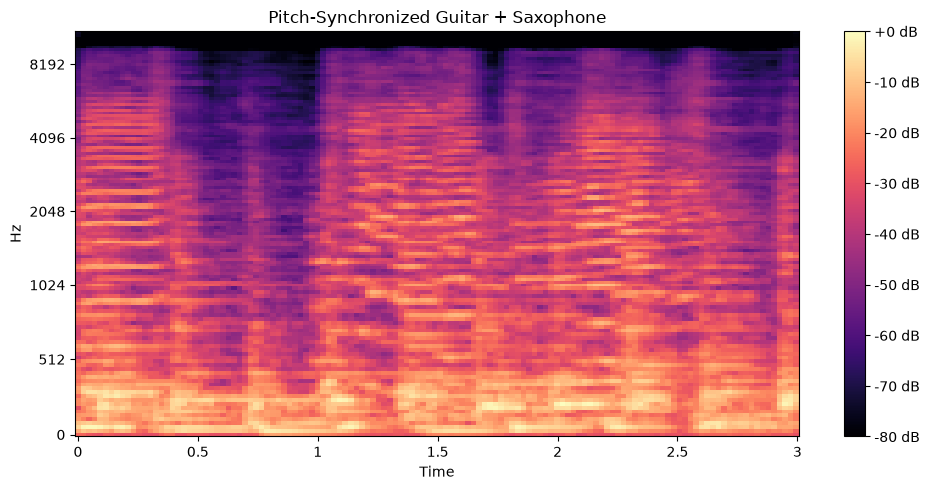

In [65]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display

SR = 22050
DURATION = 3

def load_audio_3sec(file_path):
    y, sr = librosa.load(
        file_path,
        sr=SR,
        mono=True
    )

    target_length = SR * DURATION

    if len(y) < target_length:
        y = np.pad(
            y,
            (0, target_length - len(y))
        )
    else:
        y = y[:target_length]

    return y, sr


def estimate_median_pitch(y, sr):
    f0, _, _ = librosa.pyin(
        y,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7"),
        sr=sr,
        frame_length=2048,
        hop_length=512
    )

    valid_f0 = f0[~np.isnan(f0)]

    if len(valid_f0) == 0:
        return np.nan

    return np.median(
        librosa.hz_to_midi(valid_f0)
    )


# Find two reasonably compatible clips
gac_files = train_df[
    train_df["label"] == "gac"
]["file_path"].sample(
    n=30,
    random_state=42
).tolist()

sax_files = train_df[
    train_df["label"] == "sax"
]["file_path"].sample(
    n=30,
    random_state=43
).tolist()


selected_pair = None

for gac_file in gac_files:

    y_gac, sr = load_audio_3sec(gac_file)
    pitch_gac = estimate_median_pitch(y_gac, sr)

    if np.isnan(pitch_gac):
        continue

    for sax_file in sax_files:

        y_sax, _ = load_audio_3sec(sax_file)
        pitch_sax = estimate_median_pitch(y_sax, sr)

        if np.isnan(pitch_sax):
            continue

        pitch_difference = abs(
            pitch_gac - pitch_sax
        )

        if pitch_difference <= 3:
            selected_pair = (
                gac_file,
                sax_file,
                y_gac,
                y_sax,
                pitch_gac,
                pitch_sax
            )
            break

    if selected_pair is not None:
        break


if selected_pair is None:
    raise RuntimeError(
        "Could not find a suitable pair."
    )


gac_file, sax_file, y_gac, y_sax, pitch_gac, pitch_sax = selected_pair


# Shift saxophone toward the guitar pitch
pitch_shift_steps = pitch_gac - pitch_sax

y_sax_shifted = librosa.effects.pitch_shift(
    y_sax,
    sr=sr,
    n_steps=pitch_shift_steps
)


# RMS normalization
def rms_normalize(y):
    rms = np.sqrt(np.mean(y ** 2))

    if rms == 0:
        return y

    return y / rms


y_gac_norm = rms_normalize(y_gac)
y_sax_shifted_norm = rms_normalize(y_sax_shifted)


# Mix the two instruments
y_mix = y_gac_norm + y_sax_shifted_norm

# Prevent clipping
max_value = np.max(np.abs(y_mix))

if max_value > 1:
    y_mix = y_mix / max_value


print("Guitar file:")
print(gac_file)

print("\nSaxophone file:")
print(sax_file)

print("\nOriginal guitar pitch:",
      round(pitch_gac, 2), "MIDI")

print("Original saxophone pitch:",
      round(pitch_sax, 2), "MIDI")

print("Pitch shift applied to saxophone:",
      round(pitch_shift_steps, 2), "semitones")

print("\nFinal mixed signal range:")
print(
    round(float(np.min(y_mix)), 4),
    "to",
    round(float(np.max(y_mix)), 4)
)


# Display audio
print("\nOriginal guitar:")
display(Audio(y_gac_norm, rate=sr))

print("Original saxophone:")
display(Audio(y_sax_norm if 'y_sax_norm' in locals()
              else rms_normalize(y_sax), rate=sr))

print("Pitch-synchronized mixture:")
display(Audio(y_mix, rate=sr))


# Mel spectrogram of the mixture
mel = librosa.feature.melspectrogram(
    y=y_mix,
    sr=sr,
    n_fft=2048,
    hop_length=512,
    n_mels=128,
    window="hann"
)

mel_db = librosa.power_to_db(
    mel,
    ref=np.max
)

plt.figure(figsize=(10, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Pitch-Synchronized Guitar + Saxophone")
plt.tight_layout()
plt.show()

In [66]:
def estimate_tempo(y, sr):
    tempo, _ = librosa.beat.beat_track(
        y=y,
        sr=sr,
        hop_length=512
    )
    return float(np.asarray(tempo).reshape(-1)[0])


# Estimate tempos
tempo_gac = estimate_tempo(y_gac, sr)
tempo_sax = estimate_tempo(y_sax, sr)

# Stretch saxophone toward guitar tempo
stretch_rate = tempo_sax / tempo_gac

y_sax_tempo = librosa.effects.time_stretch(
    y_sax,
    rate=stretch_rate
)

# Keep exactly 3 seconds
target_length = SR * DURATION

if len(y_sax_tempo) < target_length:
    y_sax_tempo = np.pad(
        y_sax_tempo,
        (0, target_length - len(y_sax_tempo))
    )
else:
    y_sax_tempo = y_sax_tempo[:target_length]


# Estimate the resulting tempo
tempo_sax_after = estimate_tempo(
    y_sax_tempo,
    sr
)

print("Original guitar tempo:",
      round(tempo_gac, 2), "BPM")

print("Original saxophone tempo:",
      round(tempo_sax, 2), "BPM")

print("Stretch rate:",
      round(stretch_rate, 4))

print("Estimated saxophone tempo after synchronization:",
      round(tempo_sax_after, 2), "BPM")


# Listen to original and synchronized saxophone
print("\nOriginal saxophone:")
display(Audio(y_sax, rate=sr))

print("Tempo-synchronized saxophone:")
display(Audio(y_sax_tempo, rate=sr))

Original guitar tempo: 95.7 BPM
Original saxophone tempo: 129.2 BPM
Stretch rate: 1.35
Estimated saxophone tempo after synchronization: 107.67 BPM

Original saxophone:


E:\Musical Instrument Recognition\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
E:\Musical Instrument Recognition\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
E:\Musical Instrument Recognition\.venv\Lib\site-packages\numba\np\ufunc\dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


Tempo-synchronized saxophone:


In [67]:
def estimate_tempo(y, sr):
    tempo, _ = librosa.beat.beat_track(
        y=y,
        sr=sr,
        hop_length=512
    )
    return float(np.asarray(tempo).reshape(-1)[0])


tempo_gac = estimate_tempo(y_gac, sr)
tempo_sax = estimate_tempo(y_sax, sr)

# Slow/speed up saxophone to match guitar tempo
stretch_rate = tempo_gac / tempo_sax

y_sax_tempo = librosa.effects.time_stretch(
    y_sax,
    rate=stretch_rate
)

target_length = SR * DURATION

if len(y_sax_tempo) < target_length:
    y_sax_tempo = np.pad(
        y_sax_tempo,
        (0, target_length - len(y_sax_tempo))
    )
else:
    y_sax_tempo = y_sax_tempo[:target_length]


tempo_sax_after = estimate_tempo(
    y_sax_tempo,
    sr
)

print("Original guitar tempo:",
      round(tempo_gac, 2), "BPM")

print("Original saxophone tempo:",
      round(tempo_sax, 2), "BPM")

print("Correct stretch rate:",
      round(stretch_rate, 4))

print("Estimated saxophone tempo after synchronization:",
      round(tempo_sax_after, 2), "BPM")


print("\nOriginal saxophone:")
display(Audio(y_sax, rate=sr))

print("Tempo-synchronized saxophone:")
display(Audio(y_sax_tempo, rate=sr))

Original guitar tempo: 95.7 BPM
Original saxophone tempo: 129.2 BPM
Correct stretch rate: 0.7407
Estimated saxophone tempo after synchronization: 143.55 BPM

Original saxophone:


Tempo-synchronized saxophone:


In [68]:
def load_audio_3sec(file_path, sr=22050):
    y, _ = librosa.load(
        file_path,
        sr=sr,
        mono=True
    )

    target_length = sr * 3

    if len(y) < target_length:
        y = np.pad(
            y,
            (0, target_length - len(y))
        )
    else:
        y = y[:target_length]

    return y


def estimate_pitch(y, sr=22050):
    f0, _, _ = librosa.pyin(
        y,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7"),
        sr=sr,
        frame_length=2048,
        hop_length=512
    )

    valid_f0 = f0[~np.isnan(f0)]

    if len(valid_f0) == 0:
        return np.nan

    return float(
        np.median(librosa.hz_to_midi(valid_f0))
    )


def estimate_tempo(y, sr=22050):
    tempo, _ = librosa.beat.beat_track(
        y=y,
        sr=sr,
        hop_length=512
    )

    return float(
        np.asarray(tempo).reshape(-1)[0]
    )


def rms_normalize(y):
    rms = np.sqrt(np.mean(y ** 2))

    if rms < 1e-8:
        return y

    return y / rms


def fix_length_3sec(y, sr=22050):
    target_length = sr * 3

    if len(y) < target_length:
        y = np.pad(
            y,
            (0, target_length - len(y))
        )
    elif len(y) > target_length:
        start = (len(y) - target_length) // 2
        y = y[start:start + target_length]

    return y


def synchronized_mix(
    file_1,
    file_2,
    sr=22050,
    max_pitch_shift=5.0,
    min_tempo=60,
    max_tempo=200
):
    y1 = load_audio_3sec(file_1, sr)
    y2 = load_audio_3sec(file_2, sr)

    pitch1 = estimate_pitch(y1, sr)
    pitch2 = estimate_pitch(y2, sr)

    tempo1 = estimate_tempo(y1, sr)
    tempo2 = estimate_tempo(y2, sr)

    y2_sync = y2.copy()

    # Pitch synchronization
    if (
        not np.isnan(pitch1)
        and not np.isnan(pitch2)
    ):
        pitch_shift = pitch1 - pitch2

        if abs(pitch_shift) <= max_pitch_shift:
            y2_sync = librosa.effects.pitch_shift(
                y2_sync,
                sr=sr,
                n_steps=pitch_shift
            )
        else:
            pitch_shift = 0.0
    else:
        pitch_shift = 0.0

    # Tempo synchronization
    tempo_sync_used = False

    if (
        min_tempo <= tempo1 <= max_tempo
        and min_tempo <= tempo2 <= max_tempo
        and tempo1 > 0
        and tempo2 > 0
    ):
        stretch_rate = tempo1 / tempo2

        if 0.5 <= stretch_rate <= 2.0:
            y2_sync = librosa.effects.time_stretch(
                y2_sync,
                rate=stretch_rate
            )
            tempo_sync_used = True
        else:
            stretch_rate = 1.0
    else:
        stretch_rate = 1.0

    # Restore exactly 3 seconds
    y1 = fix_length_3sec(y1, sr)
    y2_sync = fix_length_3sec(y2_sync, sr)

    # RMS normalization
    y1 = rms_normalize(y1)
    y2_sync = rms_normalize(y2_sync)

    # Equal contribution from both instruments
    y_mix = 0.5 * y1 + 0.5 * y2_sync

    # Final peak normalization
    peak = np.max(np.abs(y_mix))

    if peak > 1e-8:
        y_mix = y_mix / peak

    return {
        "y_mix": y_mix,
        "pitch_1": pitch1,
        "pitch_2": pitch2,
        "pitch_shift": pitch_shift,
        "tempo_1": tempo1,
        "tempo_2": tempo2,
        "stretch_rate": stretch_rate,
        "tempo_sync_used": tempo_sync_used
    }

In [69]:
result_sync = synchronized_mix(
    gac_file,
    sax_file
)

print("Instrument 1: Guitar")
print("Pitch:", round(result_sync["pitch_1"], 2), "MIDI")
print("Tempo:", round(result_sync["tempo_1"], 2), "BPM")

print("\nInstrument 2: Saxophone")
print("Pitch:", round(result_sync["pitch_2"], 2), "MIDI")
print("Tempo:", round(result_sync["tempo_2"], 2), "BPM")

print("\nSynchronization")
print(
    "Pitch shift:",
    round(result_sync["pitch_shift"], 2),
    "semitones"
)

print(
    "Tempo stretch rate:",
    round(result_sync["stretch_rate"], 4)
)

print(
    "Tempo synchronization used:",
    result_sync["tempo_sync_used"]
)

print("\nFinal mixture:")
display(
    Audio(
        result_sync["y_mix"],
        rate=22050
    )
)

Instrument 1: Guitar
Pitch: 38.7 MIDI
Tempo: 95.7 BPM

Instrument 2: Saxophone
Pitch: 41.0 MIDI
Tempo: 129.2 BPM

Synchronization
Pitch shift: -2.3 semitones
Tempo stretch rate: 0.7407
Tempo synchronization used: True

Final mixture:


In [71]:
import warnings

def synchronized_mix(
    file_1,
    file_2,
    sr=22050,
    max_pitch_shift=5.0,
    min_tempo=60,
    max_tempo=200
):
    y1 = load_audio_3sec(file_1, sr)
    y2 = load_audio_3sec(file_2, sr)

    pitch1 = estimate_pitch(y1, sr)
    pitch2 = estimate_pitch(y2, sr)

    tempo1 = estimate_tempo(y1, sr)
    tempo2 = estimate_tempo(y2, sr)

    y2_sync = y2.copy()

    pitch_shift = 0.0

    # Pitch synchronization
    if (
        not np.isnan(pitch1)
        and not np.isnan(pitch2)
    ):
        pitch_shift = pitch1 - pitch2

        if abs(pitch_shift) <= max_pitch_shift:
            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore",
                    category=FutureWarning
                )
                warnings.filterwarnings(
                    "ignore",
                    category=RuntimeWarning
                )

                y2_sync = librosa.effects.pitch_shift(
                    y2_sync,
                    sr=sr,
                    n_steps=pitch_shift
                )
        else:
            pitch_shift = 0.0

    # Tempo synchronization
    tempo_sync_used = False

    if (
        min_tempo <= tempo1 <= max_tempo
        and min_tempo <= tempo2 <= max_tempo
        and tempo1 > 0
        and tempo2 > 0
    ):
        stretch_rate = tempo1 / tempo2

        if 0.5 <= stretch_rate <= 2.0:

            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore",
                    category=FutureWarning
                )
                warnings.filterwarnings(
                    "ignore",
                    category=RuntimeWarning
                )

                y2_sync = librosa.effects.time_stretch(
                    y2_sync,
                    rate=stretch_rate
                )

            tempo_sync_used = True

        else:
            stretch_rate = 1.0
    else:
        stretch_rate = 1.0

    # Restore exactly 3 seconds
    y1 = fix_length_3sec(y1, sr)
    y2_sync = fix_length_3sec(y2_sync, sr)

    # RMS normalization
    y1 = rms_normalize(y1)
    y2_sync = rms_normalize(y2_sync)

    # Equal contribution
    y_mix = 0.5 * y1 + 0.5 * y2_sync

    # Final peak normalization
    peak = np.max(np.abs(y_mix))

    if peak > 1e-8:
        y_mix = y_mix / peak

    return {
        "y_mix": y_mix,
        "pitch_1": pitch1,
        "pitch_2": pitch2,
        "pitch_shift": pitch_shift,
        "tempo_1": tempo1,
        "tempo_2": tempo2,
        "stretch_rate": stretch_rate,
        "tempo_sync_used": tempo_sync_used
    }

In [72]:
result_sync = synchronized_mix(
    gac_file,
    sax_file
)

print("Pitch shift:",
      round(result_sync["pitch_shift"], 2),
      "semitones")

print("Tempo stretch rate:",
      round(result_sync["stretch_rate"], 4))

print("Tempo synchronization used:",
      result_sync["tempo_sync_used"])

display(
    Audio(
        result_sync["y_mix"],
        rate=22050
    )
)

Pitch shift: -2.3 semitones
Tempo stretch rate: 0.7407
Tempo synchronization used: True


In [73]:
import random
import numpy as np
import pandas as pd
import librosa

random.seed(42)
np.random.seed(42)

def mix_to_mel(y, sr=22050):
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window="hann"
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db.astype(np.float32)


pilot_X = []
pilot_Y = []
pilot_metadata = []

failed = 0

for i in range(100):

    label_1, label_2 = random.sample(class_names, 2)

    file_1 = train_df[
        train_df["label"] == label_1
    ]["file_path"].sample(
        n=1,
        random_state=1000 + i
    ).iloc[0]

    file_2 = train_df[
        train_df["label"] == label_2
    ]["file_path"].sample(
        n=1,
        random_state=2000 + i
    ).iloc[0]

    try:
        result = synchronized_mix(
            file_1,
            file_2
        )

        mel = mix_to_mel(
            result["y_mix"]
        )

        if mel.shape != (128, 130):
            raise ValueError(
                f"Unexpected Mel shape: {mel.shape}"
            )

        target = np.zeros(
            len(class_names),
            dtype=np.float32
        )

        target[
            label_to_index[label_1]
        ] = 1.0

        target[
            label_to_index[label_2]
        ] = 1.0

        pilot_X.append(mel)
        pilot_Y.append(target)

        pilot_metadata.append({
            "label_1": label_1,
            "label_2": label_2,
            "pitch_1": result["pitch_1"],
            "pitch_2": result["pitch_2"],
            "pitch_shift": result["pitch_shift"],
            "tempo_1": result["tempo_1"],
            "tempo_2": result["tempo_2"],
            "stretch_rate": result["stretch_rate"],
            "tempo_sync_used": result["tempo_sync_used"]
        })

    except Exception as e:
        failed += 1
        print(
            f"Mixture {i + 1} failed: {e}"
        )


pilot_X = np.array(
    pilot_X,
    dtype=np.float32
)

pilot_Y = np.array(
    pilot_Y,
    dtype=np.float32
)

pilot_metadata = pd.DataFrame(
    pilot_metadata
)


print("Successful mixtures:", len(pilot_X))
print("Failed mixtures:", failed)

print("\nX shape:", pilot_X.shape)
print("Y shape:", pilot_Y.shape)

print("\nMel range:")
print("Minimum:", float(pilot_X.min()))
print("Maximum:", float(pilot_X.max()))

print("\nUnique label counts:")

label_counts = pilot_Y.sum(axis=1)

print(
    pd.Series(
        label_counts
    ).value_counts().sort_index()
)

print("\nFirst 10 mixtures:")
pilot_metadata.head(10)

Successful mixtures: 100
Failed mixtures: 0

X shape: (100, 128, 130)
Y shape: (100, 11)

Mel range:
Minimum: -80.0
Maximum: 0.0

Unique label counts:
2.0    100
Name: count, dtype: int64

First 10 mixtures:


,label_1,label_2,pitch_1,pitch_2,pitch_shift,tempo_1,tempo_2,stretch_rate,tempo_sync_used
0,voi,cla,41.2,72.20,0.0,135.999178,143.554688,0.947368,True
1,cel,gel,48.9,54.90,0.0,143.554688,129.199219,1.111111,True
2,gac,voi,40.0,44.20,-4.2,151.999081,123.046875,1.235294,True
3,flu,cla,43.3,76.00,0.0,129.199219,184.570312,0.700000,True
4,voi,tru,43.1,66.85,0.0,143.554688,215.332031,1.000000,False
5,cla,vio,37.2,51.00,0.0,86.132812,161.499023,0.533333,True
6,pia,cel,41.1,43.20,-2.1,129.199219,123.046875,1.050000,True
7,cel,cla,43.8,73.10,0.0,151.999081,129.199219,1.176471,True
8,gac,voi,44.6,38.00,0.0,129.199219,161.499023,0.800000,True
9,tru,vio,62.0,49.00,0.0,80.749512,43.066406,1.000000,False


In [74]:
print("Pitch shift statistics")
print("-----------------------")

pitch_shift_values = pilot_metadata["pitch_shift"]

print(
    "Pitch synchronization used:",
    np.sum(pitch_shift_values != 0),
    "/",
    len(pitch_shift_values)
)

print(
    "Pitch synchronization percentage:",
    round(
        100 * np.mean(pitch_shift_values != 0),
        2
    ),
    "%"
)

print(
    "\nMean absolute pitch shift:",
    round(
        np.mean(np.abs(pitch_shift_values)),
        2
    ),
    "semitones"
)

print(
    "Maximum absolute pitch shift:",
    round(
        np.max(np.abs(pitch_shift_values)),
        2
    ),
    "semitones"
)


print("\nTempo synchronization")
print("---------------------")

tempo_sync_values = pilot_metadata[
    "tempo_sync_used"
]

print(
    "Tempo synchronization used:",
    int(tempo_sync_values.sum()),
    "/",
    len(tempo_sync_values)
)

print(
    "Tempo synchronization percentage:",
    round(
        100 * tempo_sync_values.mean(),
        2
    ),
    "%"
)

print(
    "\nStretch-rate statistics:"
)

print(
    "Minimum:",
    round(
        pilot_metadata["stretch_rate"].min(),
        3
    )
)

print(
    "Maximum:",
    round(
        pilot_metadata["stretch_rate"].max(),
        3
    )
)

print(
    "Mean:",
    round(
        pilot_metadata["stretch_rate"].mean(),
        3
    )
)

Pitch shift statistics
-----------------------
Pitch synchronization used: 26 / 100
Pitch synchronization percentage: 26.0 %

Mean absolute pitch shift: 0.54 semitones
Maximum absolute pitch shift: 5.0 semitones

Tempo synchronization
---------------------
Tempo synchronization used: 89 / 100
Tempo synchronization percentage: 89.0 %

Stretch-rate statistics:
Minimum: 0.5
Maximum: 2.0
Mean: 1.077


In [75]:
import numpy as np
import pandas as pd

pitch_samples = []

for label in class_names:

    files = train_df[
        train_df["label"] == label
    ]["file_path"].sample(
        n=min(20, len(
            train_df[train_df["label"] == label]
        )),
        random_state=42
    ).tolist()

    for file_path in files:

        y = load_audio_3sec(file_path)

        pitch = estimate_pitch(
            y,
            sr=22050
        )

        pitch_samples.append({
            "label": label,
            "file_path": file_path,
            "pitch_midi": pitch
        })

pitch_df = pd.DataFrame(
    pitch_samples
)

print("Total pitch estimates:",
      len(pitch_df))

print(
    "Valid pitch estimates:",
    pitch_df["pitch_midi"].notna().sum()
)

print(
    "Invalid pitch estimates:",
    pitch_df["pitch_midi"].isna().sum()
)

print("\nPitch statistics by class:")

pitch_summary = pitch_df.groupby("label")[
    "pitch_midi"
].agg(
    count="count",
    median="median",
    minimum="min",
    maximum="max"
).round(2)

pitch_summary

Total pitch estimates: 220
Valid pitch estimates: 220
Invalid pitch estimates: 0

Pitch statistics by class:


,count,median,minimum,maximum
label,,,,
cel,20,45.57,36.80,68.90
cla,20,52.60,36.40,93.60
flu,20,49.22,37.40,93.70
gac,20,42.75,38.00,57.00
gel,20,42.20,36.05,75.70
org,20,40.05,36.20,65.00
pia,20,41.10,36.10,76.20
sax,20,44.40,37.10,70.20
tru,20,45.15,36.00,78.00


In [76]:
valid_pitch_df = pitch_df.dropna(
    subset=["pitch_midi"]
).reset_index(drop=True)


different_class_pairs = []

for i in range(len(valid_pitch_df)):

    row1 = valid_pitch_df.iloc[i]

    for j in range(i + 1, len(valid_pitch_df)):

        row2 = valid_pitch_df.iloc[j]

        if row1["label"] == row2["label"]:
            continue

        pitch_difference = abs(
            row1["pitch_midi"] -
            row2["pitch_midi"]
        )

        different_class_pairs.append({
            "label_1": row1["label"],
            "label_2": row2["label"],
            "pitch_difference": pitch_difference
        })


pitch_pair_df = pd.DataFrame(
    different_class_pairs
)


print("Total cross-instrument pairs:",
      len(pitch_pair_df))

print("\nPitch compatibility:")

for threshold in [2, 3, 4, 5, 6, 7]:

    compatible = (
        pitch_pair_df["pitch_difference"]
        <= threshold
    )

    percentage = 100 * compatible.mean()

    print(
        f"Within ±{threshold} semitones: "
        f"{compatible.sum()} / "
        f"{len(compatible)} "
        f"({percentage:.2f}%)"
    )


print("\nOverall pitch-difference statistics:")

print(
    pitch_pair_df["pitch_difference"].describe().round(2)
)

Total cross-instrument pairs: 22000

Pitch compatibility:
Within ±2 semitones: 3626 / 22000 (16.48%)
Within ±3 semitones: 5290 / 22000 (24.05%)
Within ±4 semitones: 6777 / 22000 (30.80%)
Within ±5 semitones: 8071 / 22000 (36.69%)
Within ±6 semitones: 9286 / 22000 (42.21%)
Within ±7 semitones: 10218 / 22000 (46.45%)

Overall pitch-difference statistics:
count    22000.00
mean        12.95
std         12.58
min          0.00
25%          3.10
50%          8.00
75%         20.00
max         57.70
Name: pitch_difference, dtype: float64


In [77]:
def get_pitch_cache(df, samples_per_class=20):
    cache = {}

    for label in class_names:

        files = df[
            df["label"] == label
        ]["file_path"].tolist()

        sample_count = min(
            samples_per_class,
            len(files)
        )

        selected_files = pd.Series(
            files
        ).sample(
            n=sample_count,
            random_state=42
        ).tolist()

        cache[label] = []

        for file_path in selected_files:

            y = load_audio_3sec(
                file_path
            )

            pitch = estimate_pitch(
                y,
                sr=22050
            )

            if not np.isnan(pitch):
                cache[label].append({
                    "file_path": file_path,
                    "pitch": pitch
                })

    return cache


pitch_cache = get_pitch_cache(
    train_df,
    samples_per_class=20
)


def find_pitch_compatible_pair(
    label_1,
    label_2,
    pitch_cache,
    max_difference=5.0
):
    candidates = []

    for item_1 in pitch_cache[label_1]:

        for item_2 in pitch_cache[label_2]:

            difference = abs(
                item_1["pitch"] -
                item_2["pitch"]
            )

            if difference <= max_difference:

                candidates.append({
                    "file_1": item_1["file_path"],
                    "file_2": item_2["file_path"],
                    "pitch_1": item_1["pitch"],
                    "pitch_2": item_2["pitch"],
                    "difference": difference
                })

    if len(candidates) == 0:
        return None

    return random.choice(candidates)


# Test all 55 instrument pairs
pair_test_results = []

for i in range(len(class_names)):

    for j in range(i + 1, len(class_names)):

        label_1 = class_names[i]
        label_2 = class_names[j]

        pair = find_pitch_compatible_pair(
            label_1,
            label_2,
            pitch_cache,
            max_difference=5.0
        )

        pair_test_results.append({
            "label_1": label_1,
            "label_2": label_2,
            "compatible": pair is not None,
            "pitch_difference": (
                pair["difference"]
                if pair is not None
                else np.nan
            )
        })


pair_test_df = pd.DataFrame(
    pair_test_results
)

print(
    "Total instrument pairs:",
    len(pair_test_df)
)

print(
    "Pairs with compatible recordings:",
    pair_test_df["compatible"].sum()
)

print(
    "Pairs without compatible recordings:",
    (~pair_test_df["compatible"]).sum()
)

print("\nPair results:")

pair_test_df

Total instrument pairs: 55
Pairs with compatible recordings: 55
Pairs without compatible recordings: 0

Pair results:


,label_1,label_2,compatible,pitch_difference
0,cel,cla,True,4.90
1,cel,flu,True,1.80
2,cel,gac,True,3.40
3,cel,gel,True,2.80
4,cel,org,True,2.20
5,cel,pia,True,0.40
6,cel,sax,True,1.55
7,cel,tru,True,1.90
8,cel,vio,True,0.20
9,cel,voi,True,4.50


In [80]:
import os
import warnings

project_folder = r"E:\Musical Instrument Recognition"

feature_cache_path = os.path.join(
    project_folder,
    "processed_data",
    "multilabel_data",
    "training_audio_features.csv"
)

os.makedirs(
    os.path.dirname(feature_cache_path),
    exist_ok=True
)


if os.path.exists(feature_cache_path):

    feature_cache_df = pd.read_csv(
        feature_cache_path
    )

    print("Existing feature cache loaded.")

else:

    feature_cache = []

    total_files = len(train_df)

    for count, (_, row) in enumerate(
        train_df.iterrows(),
        start=1
    ):

        file_path = row["file_path"]
        label = row["label"]

        try:
            y = load_audio_3sec(
                file_path,
                sr=22050
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                pitch = estimate_pitch(
                    y,
                    sr=22050
                )

                tempo = estimate_tempo(
                    y,
                    sr=22050
                )

            feature_cache.append({
                "file_path": file_path,
                "label": label,
                "pitch_midi": pitch,
                "tempo_bpm": tempo
            })

        except Exception:

            feature_cache.append({
                "file_path": file_path,
                "label": label,
                "pitch_midi": np.nan,
                "tempo_bpm": np.nan
            })

        if count % 100 == 0 or count == total_files:
            print(
                f"Processed {count}/{total_files}"
            )

    feature_cache_df = pd.DataFrame(
        feature_cache
    )

    feature_cache_df.to_csv(
        feature_cache_path,
        index=False
    )

    print("\nFeature cache saved to:")
    print(feature_cache_path)


print("\nTotal files:",
      len(feature_cache_df))

print(
    "Valid pitch:",
    feature_cache_df["pitch_midi"].notna().sum()
)

print(
    "Invalid pitch:",
    feature_cache_df["pitch_midi"].isna().sum()
)

print(
    "Valid tempo:",
    feature_cache_df["tempo_bpm"].notna().sum()
)

print(
    "Invalid tempo:",
    feature_cache_df["tempo_bpm"].isna().sum()
)

Processed 100/4693
Processed 200/4693
Processed 300/4693
Processed 400/4693
Processed 500/4693
Processed 600/4693
Processed 700/4693
Processed 800/4693
Processed 900/4693
Processed 1000/4693
Processed 1100/4693
Processed 1200/4693
Processed 1300/4693
Processed 1400/4693
Processed 1500/4693
Processed 1600/4693
Processed 1700/4693
Processed 1800/4693
Processed 1900/4693
Processed 2000/4693
Processed 2100/4693
Processed 2200/4693
Processed 2300/4693
Processed 2400/4693
Processed 2500/4693
Processed 2600/4693
Processed 2700/4693
Processed 2800/4693
Processed 2900/4693
Processed 3000/4693
Processed 3100/4693
Processed 3200/4693
Processed 3300/4693
Processed 3400/4693
Processed 3500/4693
Processed 3600/4693
Processed 3700/4693
Processed 3800/4693
Processed 3900/4693
Processed 4000/4693
Processed 4100/4693
Processed 4200/4693
Processed 4300/4693
Processed 4400/4693
Processed 4500/4693
Processed 4600/4693
Processed 4693/4693

Feature cache saved to:
E:\Musical Instrument Recognition\processed_

In [81]:
pitch_class_summary = feature_cache_df.groupby("label").agg(
    total_files=("file_path", "count"),
    valid_pitch=("pitch_midi", lambda x: x.notna().sum()),
    invalid_pitch=("pitch_midi", lambda x: x.isna().sum()),
    valid_tempo=("tempo_bpm", lambda x: x.notna().sum())
)

pitch_class_summary["valid_pitch_percent"] = (
    100 *
    pitch_class_summary["valid_pitch"] /
    pitch_class_summary["total_files"]
)

pitch_class_summary = pitch_class_summary.round(2)

pitch_class_summary

,total_files,valid_pitch,invalid_pitch,valid_tempo,valid_pitch_percent
label,,,,,
cel,272,272,0,272,100.00
cla,353,353,0,353,100.00
flu,316,316,0,316,100.00
gac,446,445,1,446,99.78
gel,532,524,8,532,98.50
org,477,474,3,477,99.37
pia,505,504,1,505,99.80
sax,438,437,1,438,99.77
tru,404,403,1,404,99.75


In [82]:
valid_features = feature_cache_df[
    feature_cache_df["pitch_midi"].notna()
].copy()

compatible_pairs = []

for i in range(len(class_names)):

    for j in range(i + 1, len(class_names)):

        label_1 = class_names[i]
        label_2 = class_names[j]

        files_1 = valid_features[
            valid_features["label"] == label_1
        ]

        files_2 = valid_features[
            valid_features["label"] == label_2
        ]

        for _, row1 in files_1.iterrows():

            pitch_difference = np.abs(
                row1["pitch_midi"]
                - files_2["pitch_midi"].values
            )

            valid_indices = np.where(
                pitch_difference <= 5.0
            )[0]

            for idx in valid_indices:

                row2 = files_2.iloc[idx]

                compatible_pairs.append({
                    "label_1": label_1,
                    "file_1": row1["file_path"],
                    "pitch_1": row1["pitch_midi"],
                    "tempo_1": row1["tempo_bpm"],

                    "label_2": label_2,
                    "file_2": row2["file_path"],
                    "pitch_2": row2["pitch_midi"],
                    "tempo_2": row2["tempo_bpm"],

                    "pitch_difference": pitch_difference[idx]
                })


compatible_pairs_df = pd.DataFrame(
    compatible_pairs
)


print(
    "Total compatible file pairs:",
    len(compatible_pairs_df)
)

print("\nCompatible pairs by instrument pair:")

pair_counts = (
    compatible_pairs_df
    .groupby(["label_1", "label_2"])
    .size()
    .reset_index(name="count")
)

pair_counts

Total compatible file pairs: 3200521

Compatible pairs by instrument pair:


,label_1,label_2,count
0,cel,cla,19424
1,cel,flu,20543
2,cel,gac,41260
3,cel,gel,48348
4,cel,org,45973
5,cel,pia,45028
6,cel,sax,31371
7,cel,tru,26871
8,cel,vio,31552
9,cel,voi,48112


In [83]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import librosa

random.seed(42)
np.random.seed(42)

exp3_folder = os.path.join(
    project_folder,
    "processed_data",
    "multilabel_data"
)

os.makedirs(
    exp3_folder,
    exist_ok=True
)


def synchronized_mix_cached(
    file_1,
    file_2,
    pitch_1,
    pitch_2,
    tempo_1,
    tempo_2,
    sr=22050,
    max_pitch_shift=5.0
):
    y1 = load_audio_3sec(
        file_1,
        sr
    )

    y2 = load_audio_3sec(
        file_2,
        sr
    )

    # Pitch synchronization
    pitch_shift = pitch_1 - pitch_2

    if abs(pitch_shift) <= max_pitch_shift:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            y2 = librosa.effects.pitch_shift(
                y2,
                sr=sr,
                n_steps=pitch_shift
            )

    # Tempo synchronization
    tempo_sync_used = False

    if (
        tempo_1 > 0
        and tempo_2 > 0
        and 60 <= tempo_1 <= 200
        and 60 <= tempo_2 <= 200
    ):
        stretch_rate = tempo_1 / tempo_2

        if 0.5 <= stretch_rate <= 2.0:

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                y2 = librosa.effects.time_stretch(
                    y2,
                    rate=stretch_rate
                )

            tempo_sync_used = True

        else:
            stretch_rate = 1.0

    else:
        stretch_rate = 1.0

    # Restore exactly 3 seconds
    y1 = fix_length_3sec(
        y1,
        sr
    )

    y2 = fix_length_3sec(
        y2,
        sr
    )

    # RMS normalization
    y1 = rms_normalize(y1)
    y2 = rms_normalize(y2)

    # Small random gain variation
    gain_1 = np.random.uniform(
        0.8,
        1.2
    )

    gain_2 = np.random.uniform(
        0.8,
        1.2
    )

    y_mix = (
        gain_1 * y1 +
        gain_2 * y2
    )

    # Final peak normalization
    peak = np.max(
        np.abs(y_mix)
    )

    if peak > 1e-8:
        y_mix = y_mix / peak

    return (
        y_mix,
        pitch_shift,
        stretch_rate,
        tempo_sync_used
    )


def audio_to_mel(y, sr=22050):
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window="hann"
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db.astype(
        np.float32
    )


X_exp3_double = []
Y_exp3_double = []
metadata_exp3_double = []

mixtures_per_pair = 85

pair_groups = compatible_pairs_df.groupby(
    ["label_1", "label_2"]
)

pair_number = 0

for (label_1, label_2), group in pair_groups:

    pair_number += 1

    if len(group) < mixtures_per_pair:
        raise ValueError(
            f"Not enough compatible pairs for "
            f"{label_1} + {label_2}"
        )

    selected = group.sample(
        n=mixtures_per_pair,
        replace=False,
        random_state=42 + pair_number
    )

    for _, row in selected.iterrows():

        try:

            (
                y_mix,
                pitch_shift,
                stretch_rate,
                tempo_sync_used
            ) = synchronized_mix_cached(
                row["file_1"],
                row["file_2"],
                row["pitch_1"],
                row["pitch_2"],
                row["tempo_1"],
                row["tempo_2"]
            )

            mel = audio_to_mel(
                y_mix
            )

            if mel.shape != (
                128,
                130
            ):
                raise ValueError(
                    f"Unexpected shape: {mel.shape}"
                )

            target = np.zeros(
                len(class_names),
                dtype=np.float32
            )

            target[
                label_to_index[label_1]
            ] = 1.0

            target[
                label_to_index[label_2]
            ] = 1.0

            X_exp3_double.append(
                mel
            )

            Y_exp3_double.append(
                target
            )

            metadata_exp3_double.append({
                "label_1": label_1,
                "label_2": label_2,
                "file_1": row["file_1"],
                "file_2": row["file_2"],
                "pitch_1": row["pitch_1"],
                "pitch_2": row["pitch_2"],
                "pitch_difference": row[
                    "pitch_difference"
                ],
                "pitch_shift": pitch_shift,
                "tempo_1": row["tempo_1"],
                "tempo_2": row["tempo_2"],
                "stretch_rate": stretch_rate,
                "tempo_sync_used": tempo_sync_used
            })

        except Exception as e:

            print(
                f"Failed: {label_1} + {label_2}: {e}"
            )


X_exp3_double = np.array(
    X_exp3_double,
    dtype=np.float32
)

Y_exp3_double = np.array(
    Y_exp3_double,
    dtype=np.float32
)

metadata_exp3_double = pd.DataFrame(
    metadata_exp3_double
)


print(
    "Experiment 3 double mixtures generated:",
    len(X_exp3_double)
)

print(
    "X shape:",
    X_exp3_double.shape
)

print(
    "Y shape:",
    Y_exp3_double.shape
)

print(
    "Expected:",
    55 * 85
)

print(
    "\nMel range:",
    float(X_exp3_double.min()),
    "to",
    float(X_exp3_double.max())
)

print(
    "\nNumber of labels per mixture:"
)

print(
    pd.Series(
        Y_exp3_double.sum(axis=1)
    ).value_counts()
)

print(
    "\nPitch synchronization:"
)

print(
    "Mean absolute shift:",
    round(
        metadata_exp3_double[
            "pitch_shift"
        ].abs().mean(),
        2
    ),
    "semitones"
)

print(
    "Maximum absolute shift:",
    round(
        metadata_exp3_double[
            "pitch_shift"
        ].abs().max(),
        2
    ),
    "semitones"
)

print(
    "\nTempo synchronization used:",
    metadata_exp3_double[
        "tempo_sync_used"
    ].sum(),
    "/",
    len(metadata_exp3_double)
)

Failed: cel + gel: t_out values must be in the range [0, D.shape[-1])
Failed: cel + org: t_out values must be in the range [0, D.shape[-1])
Failed: cel + sax: t_out values must be in the range [0, D.shape[-1])
Failed: cel + vio: t_out values must be in the range [0, D.shape[-1])
Failed: cel + vio: t_out values must be in the range [0, D.shape[-1])
Failed: cla + gac: t_out values must be in the range [0, D.shape[-1])
Failed: cla + org: t_out values must be in the range [0, D.shape[-1])
Failed: cla + vio: t_out values must be in the range [0, D.shape[-1])
Failed: cla + voi: t_out values must be in the range [0, D.shape[-1])
Failed: cla + voi: t_out values must be in the range [0, D.shape[-1])
Failed: flu + gel: t_out values must be in the range [0, D.shape[-1])
Failed: flu + org: t_out values must be in the range [0, D.shape[-1])
Failed: flu + pia: t_out values must be in the range [0, D.shape[-1])
Failed: flu + sax: t_out values must be in the range [0, D.shape[-1])
Failed: flu + tru: t

In [84]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import librosa

random.seed(42)
np.random.seed(42)

# ---------------------------------------------------------
# Paths
# ---------------------------------------------------------

exp3_folder = os.path.join(
    r"E:\Musical Instrument Recognition",
    "processed_data",
    "multilabel_data"
)

os.makedirs(
    exp3_folder,
    exist_ok=True
)


# ---------------------------------------------------------
# Corrected synchronization function
# ---------------------------------------------------------

def synchronized_mix_cached(
    file_1,
    file_2,
    pitch_1,
    pitch_2,
    tempo_1,
    tempo_2,
    sr=22050,
    max_pitch_shift=5.0
):

    y1 = load_audio_3sec(
        file_1,
        sr
    )

    y2 = load_audio_3sec(
        file_2,
        sr
    )

    # -----------------------------------------------------
    # Tempo synchronization
    # -----------------------------------------------------

    tempo_sync_used = False
    stretch_rate = 1.0

    if (
        np.isfinite(tempo_1)
        and np.isfinite(tempo_2)
        and tempo_1 > 0
        and tempo_2 > 0
        and 60 <= tempo_1 <= 200
        and 60 <= tempo_2 <= 200
    ):

        stretch_rate = tempo_1 / tempo_2

        if 0.5 <= stretch_rate <= 2.0:

            try:

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    y2 = librosa.effects.time_stretch(
                        y2,
                        rate=stretch_rate
                    )

                tempo_sync_used = True

            except Exception:

                stretch_rate = 1.0
                tempo_sync_used = False


    # -----------------------------------------------------
    # Restore length before pitch synchronization
    # -----------------------------------------------------

    y2 = fix_length_3sec(
        y2,
        sr
    )


    # -----------------------------------------------------
    # Pitch synchronization
    # -----------------------------------------------------

    pitch_shift = 0.0

    if (
        np.isfinite(pitch_1)
        and np.isfinite(pitch_2)
    ):

        pitch_shift = pitch_1 - pitch_2

        if abs(pitch_shift) <= max_pitch_shift:

            try:

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    y2 = librosa.effects.pitch_shift(
                        y2,
                        sr=sr,
                        n_steps=pitch_shift
                    )

            except Exception:

                pitch_shift = 0.0


    # -----------------------------------------------------
    # Final length correction
    # -----------------------------------------------------

    y1 = fix_length_3sec(
        y1,
        sr
    )

    y2 = fix_length_3sec(
        y2,
        sr
    )


    # -----------------------------------------------------
    # RMS normalization
    # -----------------------------------------------------

    y1 = rms_normalize(y1)
    y2 = rms_normalize(y2)


    # -----------------------------------------------------
    # Random gain variation
    # -----------------------------------------------------

    gain_1 = np.random.uniform(
        0.8,
        1.2
    )

    gain_2 = np.random.uniform(
        0.8,
        1.2
    )


    # -----------------------------------------------------
    # Mix
    # -----------------------------------------------------

    y_mix = (
        gain_1 * y1 +
        gain_2 * y2
    )


    # -----------------------------------------------------
    # Final peak normalization
    # -----------------------------------------------------

    peak = np.max(
        np.abs(y_mix)
    )

    if peak > 1e-8:
        y_mix = y_mix / peak


    return (
        y_mix,
        pitch_shift,
        stretch_rate,
        tempo_sync_used
    )


# ---------------------------------------------------------
# Mel spectrogram function
# ---------------------------------------------------------

def audio_to_mel(y, sr=22050):

    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        window="hann"
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db.astype(
        np.float32
    )


# ---------------------------------------------------------
# Test the corrected function on a previously problematic
# cello + electric guitar pair
# ---------------------------------------------------------

test_row = compatible_pairs_df[
    (compatible_pairs_df["label_1"] == "cel") &
    (compatible_pairs_df["label_2"] == "gel")
].iloc[0]


test_result = synchronized_mix_cached(
    test_row["file_1"],
    test_row["file_2"],
    test_row["pitch_1"],
    test_row["pitch_2"],
    test_row["tempo_1"],
    test_row["tempo_2"]
)


print("TEST RESULT")
print("-----------")

print(
    "Pitch shift:",
    round(test_result[1], 2),
    "semitones"
)

print(
    "Stretch rate:",
    round(test_result[2], 4)
)

print(
    "Tempo synchronization used:",
    test_result[3]
)

print(
    "Audio length:",
    len(test_result[0])
)

print(
    "Expected length:",
    22050 * 3
)

print(
    "Audio range:",
    round(float(test_result[0].min()), 4),
    "to",
    round(float(test_result[0].max()), 4)
)


# ---------------------------------------------------------
# Generate Experiment 3 double-instrument dataset
# ---------------------------------------------------------

X_exp3_double = []
Y_exp3_double = []
metadata_exp3_double = []

mixtures_per_pair = 85

pair_groups = compatible_pairs_df.groupby(
    ["label_1", "label_2"]
)

pair_number = 0
failed_count = 0


for (label_1, label_2), group in pair_groups:

    pair_number += 1

    print(
        f"Processing pair {pair_number}/55: "
        f"{label_1} + {label_2}"
    )


    if len(group) < mixtures_per_pair:

        raise ValueError(
            f"Not enough compatible recordings for "
            f"{label_1} + {label_2}"
        )


    selected = group.sample(
        n=mixtures_per_pair,
        replace=False,
        random_state=42 + pair_number
    )


    successful_for_pair = 0


    for _, row in selected.iterrows():

        try:

            (
                y_mix,
                pitch_shift,
                stretch_rate,
                tempo_sync_used
            ) = synchronized_mix_cached(

                row["file_1"],
                row["file_2"],

                row["pitch_1"],
                row["pitch_2"],

                row["tempo_1"],
                row["tempo_2"]
            )


            mel = audio_to_mel(
                y_mix
            )


            if mel.shape != (128, 130):

                raise ValueError(
                    f"Unexpected Mel shape: {mel.shape}"
                )


            target = np.zeros(
                len(class_names),
                dtype=np.float32
            )


            target[
                label_to_index[label_1]
            ] = 1.0


            target[
                label_to_index[label_2]
            ] = 1.0


            X_exp3_double.append(
                mel
            )

            Y_exp3_double.append(
                target
            )


            metadata_exp3_double.append({

                "label_1": label_1,

                "label_2": label_2,

                "file_1": row["file_1"],

                "file_2": row["file_2"],

                "pitch_1": row["pitch_1"],

                "pitch_2": row["pitch_2"],

                "pitch_difference":
                    row["pitch_difference"],

                "pitch_shift":
                    pitch_shift,

                "tempo_1":
                    row["tempo_1"],

                "tempo_2":
                    row["tempo_2"],

                "stretch_rate":
                    stretch_rate,

                "tempo_sync_used":
                    tempo_sync_used

            })


            successful_for_pair += 1


        except Exception as e:

            failed_count += 1

            print(
                f"  Failed mixture: {e}"
            )


    print(
        f"  Successful: "
        f"{successful_for_pair}/{mixtures_per_pair}"
    )


# ---------------------------------------------------------
# Convert to NumPy arrays
# ---------------------------------------------------------

X_exp3_double = np.array(
    X_exp3_double,
    dtype=np.float32
)

Y_exp3_double = np.array(
    Y_exp3_double,
    dtype=np.float32
)

metadata_exp3_double = pd.DataFrame(
    metadata_exp3_double
)


# ---------------------------------------------------------
# Save dataset
# ---------------------------------------------------------

X_path = os.path.join(
    exp3_folder,
    "X_exp3_double.npy"
)

Y_path = os.path.join(
    exp3_folder,
    "Y_exp3_double.npy"
)

metadata_path = os.path.join(
    exp3_folder,
    "metadata_exp3_double.csv"
)


np.save(
    X_path,
    X_exp3_double
)

np.save(
    Y_path,
    Y_exp3_double
)

metadata_exp3_double.to_csv(
    metadata_path,
    index=False
)


# ---------------------------------------------------------
# Final verification
# ---------------------------------------------------------

print("\n")
print("=" * 60)
print("EXPERIMENT 3 DOUBLE-INSTRUMENT DATASET")
print("=" * 60)

print(
    "Successful mixtures:",
    len(X_exp3_double)
)

print(
    "Failed mixtures:",
    failed_count
)

print(
    "Expected mixtures:",
    55 * 85
)

print(
    "\nX shape:",
    X_exp3_double.shape
)

print(
    "Y shape:",
    Y_exp3_double.shape
)

print(
    "\nMel minimum:",
    float(X_exp3_double.min())
)

print(
    "Mel maximum:",
    float(X_exp3_double.max())
)


print(
    "\nNumber of labels per mixture:"
)

print(
    pd.Series(
        Y_exp3_double.sum(axis=1)
    ).value_counts()
)


print(
    "\nPitch shift statistics:"
)

print(
    "Mean absolute shift:",
    round(
        metadata_exp3_double[
            "pitch_shift"
        ].abs().mean(),
        2
    ),
    "semitones"
)

print(
    "Maximum absolute shift:",
    round(
        metadata_exp3_double[
            "pitch_shift"
        ].abs().max(),
        2
    ),
    "semitones"
)


print(
    "\nTempo synchronization:"
)

print(
    "Used:",
    int(
        metadata_exp3_double[
            "tempo_sync_used"
        ].sum()
    ),
    "/",
    len(metadata_exp3_double)
)


print(
    "\nFiles saved:"
)

print(X_path)
print(Y_path)
print(metadata_path)

TEST RESULT
-----------
Pitch shift: -2.15 semitones
Stretch rate: 1.0
Tempo synchronization used: True
Audio length: 66150
Expected length: 66150
Audio range: -0.9221 to 1.0
Processing pair 1/55: cel + cla
  Successful: 85/85
Processing pair 2/55: cel + flu
  Successful: 85/85
Processing pair 3/55: cel + gac
  Successful: 85/85
Processing pair 4/55: cel + gel
  Successful: 85/85
Processing pair 5/55: cel + org
  Successful: 85/85
Processing pair 6/55: cel + pia
  Successful: 85/85
Processing pair 7/55: cel + sax
  Successful: 85/85
Processing pair 8/55: cel + tru
  Successful: 85/85
Processing pair 9/55: cel + vio
  Successful: 85/85
Processing pair 10/55: cel + voi
  Successful: 85/85
Processing pair 11/55: cla + flu
  Successful: 85/85
Processing pair 12/55: cla + gac
  Successful: 85/85
Processing pair 13/55: cla + gel
  Successful: 85/85
Processing pair 14/55: cla + org
  Successful: 85/85
Processing pair 15/55: cla + pia
  Successful: 85/85
Processing pair 16/55: cla + sax
  Succ

In [86]:
from itertools import combinations

valid_features = feature_cache_df[
    feature_cache_df["pitch_midi"].notna()
].copy()

triplet_results = []

samples_per_class = 50

for triplet in combinations(class_names, 3):

    label_1, label_2, label_3 = triplet

    files_1 = valid_features[
        valid_features["label"] == label_1
    ].sample(
        n=min(
            samples_per_class,
            len(valid_features[
                valid_features["label"] == label_1
            ])
        ),
        random_state=42
    )

    files_2 = valid_features[
        valid_features["label"] == label_2
    ].sample(
        n=min(
            samples_per_class,
            len(valid_features[
                valid_features["label"] == label_2
            ])
        ),
        random_state=43
    )

    files_3 = valid_features[
        valid_features["label"] == label_3
    ].sample(
        n=min(
            samples_per_class,
            len(valid_features[
                valid_features["label"] == label_3
            ])
        ),
        random_state=44
    )

    compatible_count = 0

    for _, row1 in files_1.iterrows():

        diff_12 = np.abs(
            files_2["pitch_midi"].values
            - row1["pitch_midi"]
        )

        compatible_2 = files_2[
            diff_12 <= 5.0
        ]

        for _, row2 in compatible_2.iterrows():

            diff_13 = np.abs(
                files_3["pitch_midi"].values
                - row1["pitch_midi"]
            )

            diff_23 = np.abs(
                files_3["pitch_midi"].values
                - row2["pitch_midi"]
            )

            compatible_3 = files_3[
                (diff_13 <= 5.0) &
                (diff_23 <= 5.0)
            ]

            compatible_count += len(
                compatible_3
            )

    triplet_results.append({
        "label_1": label_1,
        "label_2": label_2,
        "label_3": label_3,
        "compatible_combinations": compatible_count
    })


triplet_check_df = pd.DataFrame(
    triplet_results
)


print(
    "Total possible instrument triplets:",
    len(triplet_check_df)
)

print(
    "Triplets with compatible recordings:",
    (
        triplet_check_df[
            "compatible_combinations"
        ] > 0
    ).sum()
)

print(
    "Triplets without compatible recordings:",
    (
        triplet_check_df[
            "compatible_combinations"
        ] == 0
    ).sum()
)

print(
    "\nMinimum compatible combinations:",
    triplet_check_df[
        "compatible_combinations"
    ].min()
)

print(
    "\nTriplet compatibility results:"
)

triplet_check_df

Total possible instrument triplets: 165
Triplets with compatible recordings: 165
Triplets without compatible recordings: 0

Minimum compatible combinations: 4749

Triplet compatibility results:


,label_1,label_2,label_3,compatible_combinations
0,cel,cla,flu,5478
1,cel,cla,gac,8882
2,cel,cla,gel,9431
3,cel,cla,org,10098
4,cel,cla,pia,8314
...,...,...,...,...
160,pia,vio,voi,18650
161,sax,tru,vio,11111
162,sax,tru,voi,12038
163,sax,vio,voi,14437


In [88]:
from itertools import combinations

triplet_samples = 20

X_exp3_triplet = []
Y_exp3_triplet = []
triplet_metadata = []

for triplet in combinations(class_names, 3):

    label_1, label_2, label_3 = triplet

    files_1 = valid_features[
        valid_features["label"] == label_1
    ]

    files_2 = valid_features[
        valid_features["label"] == label_2
    ]

    files_3 = valid_features[
        valid_features["label"] == label_3
    ]

    generated = 0
    attempts = 0
    max_attempts = triplet_samples * 30

    while generated < triplet_samples and attempts < max_attempts:

        attempts += 1

        row1 = files_1.sample(
            n=1,
            random_state=np.random.randint(0, 100000)
        ).iloc[0]

        row2 = files_2.sample(
            n=1,
            random_state=np.random.randint(0, 100000)
        ).iloc[0]

        row3 = files_3.sample(
            n=1,
            random_state=np.random.randint(0, 100000)
        ).iloc[0]

        pitch_1 = row1["pitch_midi"]
        pitch_2 = row2["pitch_midi"]
        pitch_3 = row3["pitch_midi"]

        if (
            not np.isfinite(pitch_1)
            or not np.isfinite(pitch_2)
            or not np.isfinite(pitch_3)
        ):
            continue

        if (
            abs(pitch_1 - pitch_2) > 5.0
            or abs(pitch_1 - pitch_3) > 5.0
            or abs(pitch_2 - pitch_3) > 5.0
        ):
            continue

        try:

            y1 = load_audio_3sec(
                row1["file_path"]
            )

            y2 = load_audio_3sec(
                row2["file_path"]
            )

            y3 = load_audio_3sec(
                row3["file_path"]
            )

            tempo_sync_count = 0

            target_tempo = row1["tempo_bpm"]

            if (
                np.isfinite(target_tempo)
                and target_tempo > 0
                and 60 <= target_tempo <= 200
            ):

                for source_idx, source_tempo in [
                    (2, row2["tempo_bpm"]),
                    (3, row3["tempo_bpm"])
                ]:

                    if (
                        np.isfinite(source_tempo)
                        and source_tempo > 0
                        and 60 <= source_tempo <= 200
                    ):

                        stretch_rate = (
                            target_tempo /
                            source_tempo
                        )

                        if 0.5 <= stretch_rate <= 2.0:

                            try:

                                with warnings.catch_warnings():
                                    warnings.simplefilter(
                                        "ignore"
                                    )

                                    y_stretched = (
                                        librosa.effects.time_stretch(
                                            y2 if source_idx == 2 else y3,
                                            rate=stretch_rate
                                        )
                                    )

                                y_stretched = fix_length_3sec(
                                    y_stretched
                                )

                                if source_idx == 2:
                                    y2 = y_stretched
                                else:
                                    y3 = y_stretched

                                tempo_sync_count += 1

                            except Exception:
                                pass

            shift_2 = pitch_1 - pitch_2
            shift_3 = pitch_1 - pitch_3

            try:

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    y2 = librosa.effects.pitch_shift(
                        y2,
                        sr=22050,
                        n_steps=shift_2
                    )

                    y3 = librosa.effects.pitch_shift(
                        y3,
                        sr=22050,
                        n_steps=shift_3
                    )

            except Exception:
                continue

            y1 = fix_length_3sec(y1)
            y2 = fix_length_3sec(y2)
            y3 = fix_length_3sec(y3)

            y1 = rms_normalize(y1)
            y2 = rms_normalize(y2)
            y3 = rms_normalize(y3)

            gain_1 = np.random.uniform(
                0.8, 1.2
            )

            gain_2 = np.random.uniform(
                0.8, 1.2
            )

            gain_3 = np.random.uniform(
                0.8, 1.2
            )

            y_mix = (
                gain_1 * y1
                + gain_2 * y2
                + gain_3 * y3
            )

            peak = np.max(
                np.abs(y_mix)
            )

            if peak > 1e-8:
                y_mix = y_mix / peak

            mel = librosa.feature.melspectrogram(
                y=y_mix,
                sr=22050,
                n_fft=2048,
                hop_length=512,
                n_mels=128,
                window="hann"
            )

            mel_db = librosa.power_to_db(
                mel,
                ref=np.max
            )

            X_exp3_triplet.append(
                mel_db.astype(np.float32)
            )

            target = np.zeros(
                len(class_names),
                dtype=np.float32
            )

            target[
                label_to_index[label_1]
            ] = 1.0

            target[
                label_to_index[label_2]
            ] = 1.0

            target[
                label_to_index[label_3]
            ] = 1.0

            Y_exp3_triplet.append(
                target
            )

            triplet_metadata.append({
                "label_1": label_1,
                "label_2": label_2,
                "label_3": label_3,
                "file_1": row1["file_path"],
                "file_2": row2["file_path"],
                "file_3": row3["file_path"],
                "pitch_shift_2": shift_2,
                "pitch_shift_3": shift_3,
                "tempo_sync_count": tempo_sync_count
            })

            generated += 1

        except Exception:
            continue

X_exp3_triplet = np.array(
    X_exp3_triplet,
    dtype=np.float32
)

Y_exp3_triplet = np.array(
    Y_exp3_triplet,
    dtype=np.float32
)

triplet_metadata_df = pd.DataFrame(
    triplet_metadata
)

print(
    "X shape:",
    X_exp3_triplet.shape
)

print(
    "Y shape:",
    Y_exp3_triplet.shape
)

print(
    "Total mixtures:",
    len(X_exp3_triplet)
)

print(
    "Minimum labels per mixture:",
    Y_exp3_triplet.sum(axis=1).min()
)

print(
    "Maximum labels per mixture:",
    Y_exp3_triplet.sum(axis=1).max()
)

X shape: (3297, 128, 130)
Y shape: (3297, 11)
Total mixtures: 3297
Minimum labels per mixture: 3.0
Maximum labels per mixture: 3.0


In [89]:
triplet_counts = (
    triplet_metadata_df
    .groupby(["label_1", "label_2", "label_3"])
    .size()
    .reset_index(name="count")
)

print("Number of triplets:", len(triplet_counts))

print("\nTriplets with fewer than 20 samples:")
print(
    triplet_counts[
        triplet_counts["count"] < 20
    ]
)

print(
    "\nTotal mixtures:",
    len(triplet_metadata_df)
)

print(
    "Minimum samples per triplet:",
    triplet_counts["count"].min()
)

Number of triplets: 165

Triplets with fewer than 20 samples:
   label_1 label_2 label_3  count
56     cla     gac     sax     17

Total mixtures: 3297
Minimum samples per triplet: 17


In [90]:
label_1 = "cla"
label_2 = "gac"
label_3 = "sax"

files_1 = valid_features[
    valid_features["label"] == label_1
]

files_2 = valid_features[
    valid_features["label"] == label_2
]

files_3 = valid_features[
    valid_features["label"] == label_3
]

generated = 0
attempts = 0

while generated < 3 and attempts < 100:

    attempts += 1

    row1 = files_1.sample(
        n=1,
        random_state=np.random.randint(0, 100000)
    ).iloc[0]

    row2 = files_2.sample(
        n=1,
        random_state=np.random.randint(0, 100000)
    ).iloc[0]

    row3 = files_3.sample(
        n=1,
        random_state=np.random.randint(0, 100000)
    ).iloc[0]

    pitch_1 = row1["pitch_midi"]
    pitch_2 = row2["pitch_midi"]
    pitch_3 = row3["pitch_midi"]

    if (
        not np.isfinite(pitch_1)
        or not np.isfinite(pitch_2)
        or not np.isfinite(pitch_3)
    ):
        continue

    if (
        abs(pitch_1 - pitch_2) > 5.0
        or abs(pitch_1 - pitch_3) > 5.0
        or abs(pitch_2 - pitch_3) > 5.0
    ):
        continue

    try:

        y1 = load_audio_3sec(
            row1["file_path"]
        )

        y2 = load_audio_3sec(
            row2["file_path"]
        )

        y3 = load_audio_3sec(
            row3["file_path"]
        )

        tempo_sync_count = 0
        target_tempo = row1["tempo_bpm"]

        if (
            np.isfinite(target_tempo)
            and target_tempo > 0
            and 60 <= target_tempo <= 200
        ):

            for source_idx, source_tempo in [
                (2, row2["tempo_bpm"]),
                (3, row3["tempo_bpm"])
            ]:

                if (
                    np.isfinite(source_tempo)
                    and source_tempo > 0
                    and 60 <= source_tempo <= 200
                ):

                    stretch_rate = (
                        target_tempo /
                        source_tempo
                    )

                    if 0.5 <= stretch_rate <= 2.0:

                        try:

                            with warnings.catch_warnings():
                                warnings.simplefilter("ignore")

                                source_audio = (
                                    y2
                                    if source_idx == 2
                                    else y3
                                )

                                y_stretched = (
                                    librosa.effects.time_stretch(
                                        source_audio,
                                        rate=stretch_rate
                                    )
                                )

                            y_stretched = fix_length_3sec(
                                y_stretched
                            )

                            if source_idx == 2:
                                y2 = y_stretched
                            else:
                                y3 = y_stretched

                            tempo_sync_count += 1

                        except Exception:
                            pass

        shift_2 = pitch_1 - pitch_2
        shift_3 = pitch_1 - pitch_3

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            y2 = librosa.effects.pitch_shift(
                y2,
                sr=22050,
                n_steps=shift_2
            )

            y3 = librosa.effects.pitch_shift(
                y3,
                sr=22050,
                n_steps=shift_3
            )

        y1 = fix_length_3sec(y1)
        y2 = fix_length_3sec(y2)
        y3 = fix_length_3sec(y3)

        y1 = rms_normalize(y1)
        y2 = rms_normalize(y2)
        y3 = rms_normalize(y3)

        gain_1 = np.random.uniform(0.8, 1.2)
        gain_2 = np.random.uniform(0.8, 1.2)
        gain_3 = np.random.uniform(0.8, 1.2)

        y_mix = (
            gain_1 * y1
            + gain_2 * y2
            + gain_3 * y3
        )

        peak = np.max(
            np.abs(y_mix)
        )

        if peak > 1e-8:
            y_mix = y_mix / peak

        mel = librosa.feature.melspectrogram(
            y=y_mix,
            sr=22050,
            n_fft=2048,
            hop_length=512,
            n_mels=128,
            window="hann"
        )

        mel_db = librosa.power_to_db(
            mel,
            ref=np.max
        )

        X_exp3_triplet = np.concatenate(
            [
                X_exp3_triplet,
                mel_db[np.newaxis, ...].astype(np.float32)
            ],
            axis=0
        )

        target = np.zeros(
            len(class_names),
            dtype=np.float32
        )

        target[label_to_index[label_1]] = 1.0
        target[label_to_index[label_2]] = 1.0
        target[label_to_index[label_3]] = 1.0

        Y_exp3_triplet = np.concatenate(
            [
                Y_exp3_triplet,
                target[np.newaxis, ...]
            ],
            axis=0
        )

        triplet_metadata_df = pd.concat(
            [
                triplet_metadata_df,
                pd.DataFrame([{
                    "label_1": label_1,
                    "label_2": label_2,
                    "label_3": label_3,
                    "file_1": row1["file_path"],
                    "file_2": row2["file_path"],
                    "file_3": row3["file_path"],
                    "pitch_shift_2": shift_2,
                    "pitch_shift_3": shift_3,
                    "tempo_sync_count": tempo_sync_count
                }])
            ],
            ignore_index=True
        )

        generated += 1

        print(
            f"Generated {generated}/3"
        )

    except Exception:
        continue

print(
    "\nFinal X shape:",
    X_exp3_triplet.shape
)

print(
    "Final Y shape:",
    Y_exp3_triplet.shape
)

print(
    "Total triplet mixtures:",
    len(X_exp3_triplet)
)

Generated 1/3
Generated 2/3
Generated 3/3

Final X shape: (3300, 128, 130)
Final Y shape: (3300, 11)
Total triplet mixtures: 3300


In [91]:
import os

save_dir = r"E:\Musical Instrument Recognition\processed_data\multilabel_data"

os.makedirs(save_dir, exist_ok=True)

np.save(
    os.path.join(
        save_dir,
        "X_exp3_triplet.npy"
    ),
    X_exp3_triplet
)

np.save(
    os.path.join(
        save_dir,
        "Y_exp3_triplet.npy"
    ),
    Y_exp3_triplet
)

triplet_metadata_df.to_csv(
    os.path.join(
        save_dir,
        "metadata_exp3_triplet.csv"
    ),
    index=False
)

triplet_counts = (
    triplet_metadata_df
    .groupby(
        ["label_1", "label_2", "label_3"]
    )
    .size()
)

print("X shape:", X_exp3_triplet.shape)
print("Y shape:", Y_exp3_triplet.shape)
print("Total mixtures:", len(X_exp3_triplet))

print(
    "Minimum samples per triplet:",
    triplet_counts.min()
)

print(
    "Maximum samples per triplet:",
    triplet_counts.max()
)

print(
    "Triplets with exactly 20 samples:",
    (triplet_counts == 20).sum()
)

print(
    "Triplets with fewer than 20:",
    (triplet_counts < 20).sum()
)

print(
    "\nSaved files:"
)

print(
    os.path.join(
        save_dir,
        "X_exp3_triplet.npy"
    )
)

print(
    os.path.join(
        save_dir,
        "Y_exp3_triplet.npy"
    )
)

print(
    os.path.join(
        save_dir,
        "metadata_exp3_triplet.csv"
    )
)

X shape: (3300, 128, 130)
Y shape: (3300, 11)
Total mixtures: 3300
Minimum samples per triplet: 20
Maximum samples per triplet: 20
Triplets with exactly 20 samples: 165
Triplets with fewer than 20: 0

Saved files:
E:\Musical Instrument Recognition\processed_data\multilabel_data\X_exp3_triplet.npy
E:\Musical Instrument Recognition\processed_data\multilabel_data\Y_exp3_triplet.npy
E:\Musical Instrument Recognition\processed_data\multilabel_data\metadata_exp3_triplet.csv


In [92]:
import os
import numpy as np

save_dir = r"E:\Musical Instrument Recognition\processed_data\multilabel_data"

X_exp3_double = np.load(
    os.path.join(
        save_dir,
        "X_exp3_double.npy"
    )
)

Y_exp3_double = np.load(
    os.path.join(
        save_dir,
        "Y_exp3_double.npy"
    )
)

X_exp3_triplet = np.load(
    os.path.join(
        save_dir,
        "X_exp3_triplet.npy"
    )
)

Y_exp3_triplet = np.load(
    os.path.join(
        save_dir,
        "Y_exp3_triplet.npy"
    )
)

X_train_exp3 = np.concatenate(
    [
        X_original_train_ml.astype(np.float32),
        X_exp3_double.astype(np.float32),
        X_exp3_triplet.astype(np.float32)
    ],
    axis=0
)

Y_train_exp3 = np.concatenate(
    [
        Y_original_train_ml.astype(np.float32),
        Y_exp3_double.astype(np.float32),
        Y_exp3_triplet.astype(np.float32)
    ],
    axis=0
)

X_val_exp3 = np.concatenate(
    [
        X_balanced_val.astype(np.float32),
        X_triplet_val.astype(np.float32)
    ],
    axis=0
)

Y_val_exp3 = np.concatenate(
    [
        Y_balanced_val.astype(np.float32),
        Y_triplet_val.astype(np.float32)
    ],
    axis=0
)

X_train_exp3 = (
    X_train_exp3 + 80.0
) / 80.0

X_val_exp3 = (
    X_val_exp3 + 80.0
) / 80.0

print("Training data:")
print("X:", X_train_exp3.shape)
print("Y:", Y_train_exp3.shape)

print("\nValidation data:")
print("X:", X_val_exp3.shape)
print("Y:", Y_val_exp3.shape)

print("\nTraining samples:", len(X_train_exp3))
print("Validation samples:", len(X_val_exp3))

print(
    "\nTraining input range:",
    X_train_exp3.min(),
    "to",
    X_train_exp3.max()
)

print(
    "Validation input range:",
    X_val_exp3.min(),
    "to",
    X_val_exp3.max()
)

print(
    "\nAverage number of labels per training sample:",
    Y_train_exp3.sum(axis=1).mean()
)

print(
    "Average number of labels per validation sample:",
    Y_val_exp3.sum(axis=1).mean()
)

Training data:
X: (12668, 128, 130)
Y: (12668, 11)

Validation data:
X: (1980, 128, 130)
Y: (1980, 11)

Training samples: 12668
Validation samples: 1980

Training input range: 0.0 to 1.0
Validation input range: 0.0 to 1.0

Average number of labels per training sample: 1.8900379
Average number of labels per validation sample: 2.5


In [93]:
import tensorflow as tf

model_exp3 = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(128, 130, 1)
    ),

    tf.keras.layers.Conv2D(
        32, (3,3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Conv2D(
        32, (3,3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.MaxPooling2D(
        (2,2)
    ),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(
        64, (3,3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Conv2D(
        64, (3,3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.MaxPooling2D(
        (2,2)
    ),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(
        128, (3,3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Conv2D(
        128, (3,3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.MaxPooling2D(
        (2,2)
    ),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        11,
        activation="sigmoid"
    )
])

model_exp3.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        ),
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True
        )
    ]
)

model_exp3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)                   │ (None, 128, 130, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_18               │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_19 (Conv2D)                   │ (None, 128, 130, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_19               │ (None, 128, 130, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 64, 65, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_20 (Conv2D)                   │ (None, 64, 65, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_20               │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_21 (Conv2D)                   │ (None, 64, 65, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_21               │ (None, 64, 65, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_13 (Dropout)                 │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_22 (Conv2D)                   │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_22               │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_23 (Conv2D)                   │ (None, 32, 32, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_23               │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 306,155 (1.17 MB)

 Trainable params: 305,259 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [94]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

model_path_exp3 = (
    r"E:\Musical Instrument Recognition"
    r"\processed_data\multilabel_data"
    r"\best_cnn_multilabel_exp3.keras"
)

callbacks_exp3 = [
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        model_path_exp3,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history_exp3 = model_exp3.fit(
    X_train_exp3[..., np.newaxis],
    Y_train_exp3,
    validation_data=(
        X_val_exp3[..., np.newaxis],
        Y_val_exp3
    ),
    epochs=50,
    batch_size=32,
    callbacks=callbacks_exp3,
    verbose=1
)

Epoch 1/50
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - auc: 0.6606 - binary_accuracy: 0.8240 - loss: 0.4393
Epoch 1: val_loss improved from None to 0.87445, saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_exp3.keras

Epoch 1: finished saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_exp3.keras
396/396 ━━━━━━━━━━━━━━━━━━━━ 615s 2s/step - auc: 0.6606 - binary_accuracy: 0.8240 - loss: 0.4393 - val_auc: 0.5567 - val_binary_accuracy: 0.7727 - val_loss: 0.8745 - learning_rate: 0.0010
Epoch 2/50
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - auc: 0.7439 - binary_accuracy: 0.8348 - loss: 0.3982
Epoch 2: val_loss improved from 0.87445 to 0.59751, saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_exp3.keras

Epoch 2: finished saving model to E:\Musical Instrument Recognition\processed_data\multilabel_data\best_cnn_multilabel_exp3.keras
396/396 ━━━━━

In [95]:
from sklearn.metrics import f1_score
import numpy as np

val_prob_exp3 = model_exp3.predict(
    X_val_exp3[..., np.newaxis],
    verbose=1
)

thresholds = np.arange(
    0.10,
    0.51,
    0.025
)

threshold_results_exp3 = []

for threshold in thresholds:

    val_pred = (
        val_prob_exp3 >= threshold
    ).astype(int)

    micro_f1 = f1_score(
        Y_val_exp3,
        val_pred,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        Y_val_exp3,
        val_pred,
        average="macro",
        zero_division=0
    )

    threshold_results_exp3.append({
        "threshold": threshold,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1
    })

threshold_results_exp3 = pd.DataFrame(
    threshold_results_exp3
)

best_threshold_exp3 = (
    threshold_results_exp3
    .loc[
        threshold_results_exp3["micro_f1"].idxmax(),
        "threshold"
    ]
)

best_micro_f1_exp3 = (
    threshold_results_exp3["micro_f1"].max()
)

best_macro_f1_exp3 = (
    threshold_results_exp3.loc[
        threshold_results_exp3["micro_f1"].idxmax(),
        "macro_f1"
    ]
)

print(
    "Best threshold:",
    best_threshold_exp3
)

print(
    "Best validation Micro-F1:",
    best_micro_f1_exp3
)

print(
    "Validation Macro-F1 at best threshold:",
    best_macro_f1_exp3
)

print(
    "\nThreshold results:"
)

print(
    threshold_results_exp3
)

62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 230ms/step
Best threshold: 0.24999999999999997
Best validation Micro-F1: 0.5567074434998963
Validation Macro-F1 at best threshold: 0.5530785210047988

Threshold results:
    threshold  micro_f1  macro_f1
0       0.100  0.527889  0.540043
1       0.125  0.538021  0.548321
2       0.150  0.548929  0.556381
3       0.175  0.552982  0.557824
4       0.200  0.553849  0.555936
5       0.225  0.554953  0.554304
6       0.250  0.556707  0.553079
7       0.275  0.552158  0.545575
8       0.300  0.548485  0.540105
9       0.325  0.542547  0.532192
10      0.350  0.532398  0.520163
11      0.375  0.520548  0.506590
12      0.400  0.511658  0.496241
13      0.425  0.497239  0.480360
14      0.450  0.485941  0.468553
15      0.475  0.473445  0.453877
16      0.500  0.460888  0.439723


In [96]:
from sklearn.metrics import f1_score, precision_score, recall_score

# Experiment 2 predictions
prob_exp2 = model_multilabel_v2.predict(
    X_val_v2[..., np.newaxis],
    verbose=1
)

# Experiment 3 predictions are already available
prob_exp3 = val_prob_exp3

threshold = 0.25

pred_exp2 = (
    prob_exp2 >= threshold
).astype(int)

pred_exp3 = (
    prob_exp3 >= threshold
).astype(int)

results_comparison = []

for name, y_pred in [
    ("Experiment 2", pred_exp2),
    ("Experiment 3", pred_exp3)
]:

    precision = precision_score(
        Y_val_v2,
        y_pred,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        Y_val_v2,
        y_pred,
        average="micro",
        zero_division=0
    )

    micro_f1 = f1_score(
        Y_val_v2,
        y_pred,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        Y_val_v2,
        y_pred,
        average="macro",
        zero_division=0
    )

    avg_predicted_labels = (
        y_pred.sum(axis=1).mean()
    )

    results_comparison.append({
        "Experiment": name,
        "Precision": precision,
        "Recall": recall,
        "Micro-F1": micro_f1,
        "Macro-F1": macro_f1,
        "Avg Predicted Labels": avg_predicted_labels
    })

comparison_df = pd.DataFrame(
    results_comparison
)

print(comparison_df.to_string(index=False))

62/62 ━━━━━━━━━━━━━━━━━━━━ 14s 219ms/step
  Experiment  Precision   Recall  Micro-F1  Macro-F1  Avg Predicted Labels
Experiment 2   0.552939 0.630909  0.589356  0.596518              2.852525
Experiment 3   0.571763 0.542424  0.556707  0.553079              2.371717


In [97]:
from itertools import combinations

double_val_samples = 18

X_exp3_double_val = []
Y_exp3_double_val = []
double_val_metadata = []

for pair in combinations(class_names, 2):

    label_1, label_2 = pair

    files_1 = valid_features[
        valid_features["label"] == label_1
    ]

    files_2 = valid_features[
        valid_features["label"] == label_2
    ]

    generated = 0
    attempts = 0
    max_attempts = double_val_samples * 30

    while (
        generated < double_val_samples
        and attempts < max_attempts
    ):

        attempts += 1

        row1 = files_1.sample(
            n=1,
            random_state=np.random.randint(
                0, 100000
            )
        ).iloc[0]

        row2 = files_2.sample(
            n=1,
            random_state=np.random.randint(
                0, 100000
            )
        ).iloc[0]

        pitch_1 = row1["pitch_midi"]
        pitch_2 = row2["pitch_midi"]

        if (
            not np.isfinite(pitch_1)
            or not np.isfinite(pitch_2)
        ):
            continue

        if abs(pitch_1 - pitch_2) > 5.0:
            continue

        try:

            y1 = load_audio_3sec(
                row1["file_path"]
            )

            y2 = load_audio_3sec(
                row2["file_path"]
            )

            tempo_sync_used = False
            stretch_rate = 1.0

            tempo_1 = row1["tempo_bpm"]
            tempo_2 = row2["tempo_bpm"]

            if (
                np.isfinite(tempo_1)
                and np.isfinite(tempo_2)
                and tempo_1 > 0
                and tempo_2 > 0
                and 60 <= tempo_1 <= 200
                and 60 <= tempo_2 <= 200
            ):

                stretch_rate = tempo_1 / tempo_2

                if 0.5 <= stretch_rate <= 2.0:

                    try:

                        with warnings.catch_warnings():
                            warnings.simplefilter(
                                "ignore"
                            )

                            y2 = (
                                librosa.effects.time_stretch(
                                    y2,
                                    rate=stretch_rate
                                )
                            )

                        y2 = fix_length_3sec(
                            y2
                        )

                        tempo_sync_used = True

                    except Exception:

                        stretch_rate = 1.0
                        tempo_sync_used = False

            y2 = fix_length_3sec(
                y2
            )

            pitch_shift = (
                pitch_1 - pitch_2
            )

            try:

                with warnings.catch_warnings():
                    warnings.simplefilter(
                        "ignore"
                    )

                    y2 = (
                        librosa.effects.pitch_shift(
                            y2,
                            sr=22050,
                            n_steps=pitch_shift
                        )
                    )

            except Exception:

                continue

            y1 = fix_length_3sec(
                y1
            )

            y2 = fix_length_3sec(
                y2
            )

            y1 = rms_normalize(
                y1
            )

            y2 = rms_normalize(
                y2
            )

            gain_1 = np.random.uniform(
                0.8,
                1.2
            )

            gain_2 = np.random.uniform(
                0.8,
                1.2
            )

            y_mix = (
                gain_1 * y1
                + gain_2 * y2
            )

            peak = np.max(
                np.abs(y_mix)
            )

            if peak > 1e-8:
                y_mix = y_mix / peak

            mel = (
                librosa.feature.melspectrogram(
                    y=y_mix,
                    sr=22050,
                    n_fft=2048,
                    hop_length=512,
                    n_mels=128,
                    window="hann"
                )
            )

            mel_db = (
                librosa.power_to_db(
                    mel,
                    ref=np.max
                )
            )

            X_exp3_double_val.append(
                mel_db.astype(
                    np.float32
                )
            )

            target = np.zeros(
                len(class_names),
                dtype=np.float32
            )

            target[
                label_to_index[label_1]
            ] = 1.0

            target[
                label_to_index[label_2]
            ] = 1.0

            Y_exp3_double_val.append(
                target
            )

            double_val_metadata.append({
                "label_1": label_1,
                "label_2": label_2,
                "file_1": row1["file_path"],
                "file_2": row2["file_path"],
                "pitch_shift": pitch_shift,
                "stretch_rate": stretch_rate,
                "tempo_sync_used": tempo_sync_used
            })

            generated += 1

        except Exception:
            continue

X_exp3_double_val = np.array(
    X_exp3_double_val,
    dtype=np.float32
)

Y_exp3_double_val = np.array(
    Y_exp3_double_val,
    dtype=np.float32
)

double_val_metadata_df = pd.DataFrame(
    double_val_metadata
)

print(
    "X shape:",
    X_exp3_double_val.shape
)

print(
    "Y shape:",
    Y_exp3_double_val.shape
)

print(
    "Total mixtures:",
    len(X_exp3_double_val)
)

print(
    "Minimum labels:",
    Y_exp3_double_val.sum(axis=1).min()
)

print(
    "Maximum labels:",
    Y_exp3_double_val.sum(axis=1).max()
)

print(
    "\nTempo synchronization used:",
    double_val_metadata_df[
        "tempo_sync_used"
    ].sum(),
    "/",
    len(double_val_metadata_df)
)

X shape: (990, 128, 130)
Y shape: (990, 11)
Total mixtures: 990
Minimum labels: 2.0
Maximum labels: 2.0

Tempo synchronization used: 903 / 990


In [98]:
from itertools import combinations

triplet_val_samples = 6

X_exp3_triplet_val = []
Y_exp3_triplet_val = []
triplet_val_metadata = []

for triplet in combinations(class_names, 3):

    label_1, label_2, label_3 = triplet

    files_1 = valid_features[
        valid_features["label"] == label_1
    ]

    files_2 = valid_features[
        valid_features["label"] == label_2
    ]

    files_3 = valid_features[
        valid_features["label"] == label_3
    ]

    generated = 0
    attempts = 0
    max_attempts = triplet_val_samples * 50

    while (
        generated < triplet_val_samples
        and attempts < max_attempts
    ):

        attempts += 1

        row1 = files_1.sample(
            n=1,
            random_state=np.random.randint(
                0, 100000
            )
        ).iloc[0]

        row2 = files_2.sample(
            n=1,
            random_state=np.random.randint(
                0, 100000
            )
        ).iloc[0]

        row3 = files_3.sample(
            n=1,
            random_state=np.random.randint(
                0, 100000
            )
        ).iloc[0]

        pitch_1 = row1["pitch_midi"]
        pitch_2 = row2["pitch_midi"]
        pitch_3 = row3["pitch_midi"]

        if (
            not np.isfinite(pitch_1)
            or not np.isfinite(pitch_2)
            or not np.isfinite(pitch_3)
        ):
            continue

        if (
            abs(pitch_1 - pitch_2) > 5.0
            or abs(pitch_1 - pitch_3) > 5.0
            or abs(pitch_2 - pitch_3) > 5.0
        ):
            continue

        try:

            y1 = load_audio_3sec(
                row1["file_path"]
            )

            y2 = load_audio_3sec(
                row2["file_path"]
            )

            y3 = load_audio_3sec(
                row3["file_path"]
            )

            tempo_sync_count = 0

            target_tempo = row1["tempo_bpm"]

            if (
                np.isfinite(target_tempo)
                and target_tempo > 0
                and 60 <= target_tempo <= 200
            ):

                for source_idx, source_tempo in [
                    (2, row2["tempo_bpm"]),
                    (3, row3["tempo_bpm"])
                ]:

                    if (
                        np.isfinite(source_tempo)
                        and source_tempo > 0
                        and 60 <= source_tempo <= 200
                    ):

                        stretch_rate = (
                            target_tempo /
                            source_tempo
                        )

                        if 0.5 <= stretch_rate <= 2.0:

                            try:

                                with warnings.catch_warnings():
                                    warnings.simplefilter(
                                        "ignore"
                                    )

                                    source_audio = (
                                        y2
                                        if source_idx == 2
                                        else y3
                                    )

                                    y_stretched = (
                                        librosa.effects.time_stretch(
                                            source_audio,
                                            rate=stretch_rate
                                        )
                                    )

                                y_stretched = fix_length_3sec(
                                    y_stretched
                                )

                                if source_idx == 2:
                                    y2 = y_stretched
                                else:
                                    y3 = y_stretched

                                tempo_sync_count += 1

                            except Exception:
                                pass

            shift_2 = pitch_1 - pitch_2
            shift_3 = pitch_1 - pitch_3

            try:

                with warnings.catch_warnings():
                    warnings.simplefilter(
                        "ignore"
                    )

                    y2 = librosa.effects.pitch_shift(
                        y2,
                        sr=22050,
                        n_steps=shift_2
                    )

                    y3 = librosa.effects.pitch_shift(
                        y3,
                        sr=22050,
                        n_steps=shift_3
                    )

            except Exception:
                continue

            y1 = fix_length_3sec(y1)
            y2 = fix_length_3sec(y2)
            y3 = fix_length_3sec(y3)

            y1 = rms_normalize(y1)
            y2 = rms_normalize(y2)
            y3 = rms_normalize(y3)

            gain_1 = np.random.uniform(
                0.8,
                1.2
            )

            gain_2 = np.random.uniform(
                0.8,
                1.2
            )

            gain_3 = np.random.uniform(
                0.8,
                1.2
            )

            y_mix = (
                gain_1 * y1
                + gain_2 * y2
                + gain_3 * y3
            )

            peak = np.max(
                np.abs(y_mix)
            )

            if peak > 1e-8:
                y_mix = y_mix / peak

            mel = librosa.feature.melspectrogram(
                y=y_mix,
                sr=22050,
                n_fft=2048,
                hop_length=512,
                n_mels=128,
                window="hann"
            )

            mel_db = librosa.power_to_db(
                mel,
                ref=np.max
            )

            X_exp3_triplet_val.append(
                mel_db.astype(
                    np.float32
                )
            )

            target = np.zeros(
                len(class_names),
                dtype=np.float32
            )

            target[
                label_to_index[label_1]
            ] = 1.0

            target[
                label_to_index[label_2]
            ] = 1.0

            target[
                label_to_index[label_3]
            ] = 1.0

            Y_exp3_triplet_val.append(
                target
            )

            triplet_val_metadata.append({
                "label_1": label_1,
                "label_2": label_2,
                "label_3": label_3,
                "file_1": row1["file_path"],
                "file_2": row2["file_path"],
                "file_3": row3["file_path"],
                "pitch_shift_2": shift_2,
                "pitch_shift_3": shift_3,
                "tempo_sync_count": tempo_sync_count
            })

            generated += 1

        except Exception:
            continue

X_exp3_triplet_val = np.array(
    X_exp3_triplet_val,
    dtype=np.float32
)

Y_exp3_triplet_val = np.array(
    Y_exp3_triplet_val,
    dtype=np.float32
)

triplet_val_metadata_df = pd.DataFrame(
    triplet_val_metadata
)

print(
    "X shape:",
    X_exp3_triplet_val.shape
)

print(
    "Y shape:",
    Y_exp3_triplet_val.shape
)

print(
    "Total mixtures:",
    len(X_exp3_triplet_val)
)

print(
    "Minimum labels:",
    Y_exp3_triplet_val.sum(axis=1).min()
)

print(
    "Maximum labels:",
    Y_exp3_triplet_val.sum(axis=1).max()
)

print(
    "\nTriplets:",
    triplet_val_metadata_df[
        ["label_1", "label_2", "label_3"]
    ].drop_duplicates().shape[0]
)

print(
    "Tempo synchronization operations used:",
    triplet_val_metadata_df[
        "tempo_sync_count"
    ].sum()
)

X shape: (990, 128, 130)
Y shape: (990, 11)
Total mixtures: 990
Minimum labels: 3.0
Maximum labels: 3.0

Triplets: 165
Tempo synchronization operations used: 1819


In [99]:
X_val_exp3_sync = np.concatenate(
    [
        X_exp3_double_val.astype(np.float32),
        X_exp3_triplet_val.astype(np.float32)
    ],
    axis=0
)

Y_val_exp3_sync = np.concatenate(
    [
        Y_exp3_double_val.astype(np.float32),
        Y_exp3_triplet_val.astype(np.float32)
    ],
    axis=0
)

X_val_exp3_sync = (
    X_val_exp3_sync + 80.0
) / 80.0

print(
    "Validation X shape:",
    X_val_exp3_sync.shape
)

print(
    "Validation Y shape:",
    Y_val_exp3_sync.shape
)

print(
    "Total validation samples:",
    len(X_val_exp3_sync)
)

print(
    "Input range:",
    X_val_exp3_sync.min(),
    "to",
    X_val_exp3_sync.max()
)

print(
    "Minimum labels:",
    Y_val_exp3_sync.sum(axis=1).min()
)

print(
    "Maximum labels:",
    Y_val_exp3_sync.sum(axis=1).max()
)

print(
    "Average labels:",
    Y_val_exp3_sync.sum(axis=1).mean()
)

Validation X shape: (1980, 128, 130)
Validation Y shape: (1980, 11)
Total validation samples: 1980
Input range: 0.0 to 1.0
Minimum labels: 2.0
Maximum labels: 3.0
Average labels: 2.5


In [100]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold = 0.25

# Experiment 2 on synchronized validation data
prob_exp2_sync = model_multilabel_v2.predict(
    X_val_exp3_sync[..., np.newaxis],
    verbose=1
)

# Experiment 3 on synchronized validation data
prob_exp3_sync = model_exp3.predict(
    X_val_exp3_sync[..., np.newaxis],
    verbose=1
)

pred_exp2_sync = (
    prob_exp2_sync >= threshold
).astype(int)

pred_exp3_sync = (
    prob_exp3_sync >= threshold
).astype(int)

comparison_sync = []

for name, predictions in [
    ("Experiment 2", pred_exp2_sync),
    ("Experiment 3", pred_exp3_sync)
]:

    precision = precision_score(
        Y_val_exp3_sync,
        predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        Y_val_exp3_sync,
        predictions,
        average="micro",
        zero_division=0
    )

    micro_f1 = f1_score(
        Y_val_exp3_sync,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        Y_val_exp3_sync,
        predictions,
        average="macro",
        zero_division=0
    )

    avg_predicted = (
        predictions.sum(axis=1).mean()
    )

    comparison_sync.append({
        "Experiment": name,
        "Precision": precision,
        "Recall": recall,
        "Micro-F1": micro_f1,
        "Macro-F1": macro_f1,
        "Avg Predicted Labels": avg_predicted
    })

comparison_sync_df = pd.DataFrame(
    comparison_sync
)

print(
    comparison_sync_df.to_string(
        index=False
    )
)

62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 242ms/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 13s 216ms/step
  Experiment  Precision   Recall  Micro-F1  Macro-F1  Avg Predicted Labels
Experiment 2   0.499656 0.586061  0.539420  0.536063              2.932323
Experiment 3   0.539718 0.641010  0.586019  0.585649              2.969192


In [101]:
import os
import glob
import numpy as np
import pandas as pd
import librosa

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

official_test_dir = (
    r"E:\Musical Instrument Recognition"
    r"\IRMAS-TestingData"
)

wav_files = sorted(
    glob.glob(
        os.path.join(
            official_test_dir,
            "**",
            "*.wav"
        ),
        recursive=True
    )
)

print(
    "Official WAV files:",
    len(wav_files)
)

official_probabilities_exp3 = []
official_targets_exp3 = []
official_file_names_exp3 = []

for file_number, file_path in enumerate(
    wav_files,
    start=1
):

    y, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True
    )

    segment_length = int(
        3 * sr
    )

    hop_length = int(
        1.5 * sr
    )

    segments = []

    start = 0

    while start < len(y):

        end = start + segment_length

        segment = y[start:end]

        if len(segment) == 0:
            break

        if len(segment) < segment_length:

            segment = np.pad(
                segment,
                (
                    0,
                    segment_length - len(segment)
                )
            )

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_fft=2048,
            hop_length=512,
            n_mels=128,
            window="hann"
        )

        mel_db = librosa.power_to_db(
            mel,
            ref=np.max
        )

        mel_normalized = (
            mel_db + 80.0
        ) / 80.0

        segments.append(
            mel_normalized.astype(
                np.float32
            )
        )

        if end >= len(y):
            break

        start += hop_length

    segments = np.array(
        segments,
        dtype=np.float32
    )

    probabilities = model_exp3.predict(
        segments[..., np.newaxis],
        verbose=0
    )

    mean_probabilities = np.mean(
        probabilities,
        axis=0
    )

    txt_path = os.path.splitext(
        file_path
    )[0] + ".txt"

    labels = []

    with open(
        txt_path,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            label = line.strip()

            if label in label_to_index:
                labels.append(label)

    target = np.zeros(
        len(class_names),
        dtype=int
    )

    for label in labels:
        target[
            label_to_index[label]
        ] = 1

    official_probabilities_exp3.append(
        mean_probabilities
    )

    official_targets_exp3.append(
        target
    )

    official_file_names_exp3.append(
        os.path.basename(file_path)
    )

    if file_number % 100 == 0:
        print(
            f"Processed {file_number}/{len(wav_files)}"
        )

official_probabilities_exp3 = np.array(
    official_probabilities_exp3,
    dtype=np.float32
)

official_targets_exp3 = np.array(
    official_targets_exp3,
    dtype=np.int32
)

print(
    "\nFinal probability shape:",
    official_probabilities_exp3.shape
)

print(
    "Final target shape:",
    official_targets_exp3.shape
)

threshold_exp3_official = 0.25

official_predictions_exp3 = (
    official_probabilities_exp3
    >= threshold_exp3_official
).astype(int)

precision_exp3_official = precision_score(
    official_targets_exp3,
    official_predictions_exp3,
    average="micro",
    zero_division=0
)

recall_exp3_official = recall_score(
    official_targets_exp3,
    official_predictions_exp3,
    average="micro",
    zero_division=0
)

micro_f1_exp3_official = f1_score(
    official_targets_exp3,
    official_predictions_exp3,
    average="micro",
    zero_division=0
)

macro_f1_exp3_official = f1_score(
    official_targets_exp3,
    official_predictions_exp3,
    average="macro",
    zero_division=0
)

print("\nExperiment 3 Official Test Results")
print("----------------------------------")

print(
    "Micro Precision:",
    precision_exp3_official
)

print(
    "Micro Recall:",
    recall_exp3_official
)

print(
    "Micro F1:",
    micro_f1_exp3_official
)

print(
    "Macro F1:",
    macro_f1_exp3_official
)

Official WAV files: 2874
Processed 100/2874
Processed 200/2874
Processed 300/2874
Processed 400/2874
Processed 500/2874
Processed 600/2874
Processed 700/2874
Processed 800/2874
Processed 900/2874
Processed 1000/2874
Processed 1100/2874
Processed 1200/2874
Processed 1300/2874
Processed 1400/2874
Processed 1500/2874
Processed 1600/2874
Processed 1700/2874
Processed 1800/2874
Processed 1900/2874
Processed 2000/2874
Processed 2100/2874
Processed 2200/2874
Processed 2300/2874
Processed 2400/2874
Processed 2500/2874
Processed 2600/2874
Processed 2700/2874
Processed 2800/2874

Final probability shape: (2874, 11)
Final target shape: (2874, 11)

Experiment 3 Official Test Results
----------------------------------
Micro Precision: 0.6716074623051367
Micro Recall: 0.5344722391702258
Micro F1: 0.5952434881087203
Macro F1: 0.4928157589064462


In [102]:
class_thresholds_exp3 = {}

threshold_candidates = np.arange(
    0.10,
    0.51,
    0.025
)

for i, class_name in enumerate(class_names):

    best_threshold = 0.25
    best_f1 = 0.0

    y_true_class = (
        Y_val_exp3_sync[:, i]
    )

    y_prob_class = (
        prob_exp3_sync[:, i]
    )

    for threshold in threshold_candidates:

        y_pred_class = (
            y_prob_class >= threshold
        ).astype(int)

        class_f1 = f1_score(
            y_true_class,
            y_pred_class,
            zero_division=0
        )

        if class_f1 > best_f1:

            best_f1 = class_f1
            best_threshold = threshold

    class_thresholds_exp3[
        class_name
    ] = best_threshold

print("Experiment 3 class-specific thresholds:")
print()

for class_name in class_names:
    print(
        f"{class_name}: "
        f"{class_thresholds_exp3[class_name]:.3f}"
    )

Experiment 3 class-specific thresholds:

cel: 0.500
cla: 0.200
flu: 0.375
gac: 0.200
gel: 0.275
org: 0.275
pia: 0.300
sax: 0.150
tru: 0.300
vio: 0.250
voi: 0.300


In [103]:
official_predictions_exp3_class = np.zeros_like(
    official_probabilities_exp3,
    dtype=int
)

for i, class_name in enumerate(class_names):

    threshold = class_thresholds_exp3[
        class_name
    ]

    official_predictions_exp3_class[:, i] = (
        official_probabilities_exp3[:, i]
        >= threshold
    ).astype(int)

precision_exp3_class = precision_score(
    official_targets_exp3,
    official_predictions_exp3_class,
    average="micro",
    zero_division=0
)

recall_exp3_class = recall_score(
    official_targets_exp3,
    official_predictions_exp3_class,
    average="micro",
    zero_division=0
)

micro_f1_exp3_class = f1_score(
    official_targets_exp3,
    official_predictions_exp3_class,
    average="micro",
    zero_division=0
)

macro_f1_exp3_class = f1_score(
    official_targets_exp3,
    official_predictions_exp3_class,
    average="macro",
    zero_division=0
)

print("Experiment 3 Official Test")
print("Class-Specific Thresholds")
print("--------------------------")

print(
    "Micro Precision:",
    precision_exp3_class
)

print(
    "Micro Recall:",
    recall_exp3_class
)

print(
    "Micro F1:",
    micro_f1_exp3_class
)

print(
    "Macro F1:",
    macro_f1_exp3_class
)

print("\nComparison with global threshold:")

print(
    "Global Micro F1:",
    micro_f1_exp3_official
)

print(
    "Class-Specific Micro F1:",
    micro_f1_exp3_class
)

print(
    "Improvement:",
    micro_f1_exp3_class -
    micro_f1_exp3_official
)

Experiment 3 Official Test
Class-Specific Thresholds
--------------------------
Micro Precision: 0.7341303729006547
Micro Recall: 0.5245068130974171
Micro F1: 0.6118623962040333
Macro F1: 0.5076933717158671

Comparison with global threshold:
Global Micro F1: 0.5952434881087203
Class-Specific Micro F1: 0.6118623962040333
Improvement: 0.016618908095312968


In [104]:
print("final")

final


In [105]:
import tensorflow as tf
import numpy as np
import os

final_model_path = (
    r"E:\Musical Instrument Recognition"
    r"\processed_data\multilabel_data"
    r"\best_cnn_multilabel_v2.keras"
)

final_model = tf.keras.models.load_model(
    final_model_path
)

print("Final model loaded successfully.")
print("Parameters:", final_model.count_params())
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)

Final model loaded successfully.
Parameters: 306155
Input shape: (None, 128, 130, 1)
Output shape: (None, 11)


In [106]:
import librosa
import numpy as np

final_thresholds = {
    "cel": 0.175,
    "cla": 0.350,
    "flu": 0.400,
    "gac": 0.175,
    "gel": 0.475,
    "org": 0.450,
    "pia": 0.125,
    "sax": 0.225,
    "tru": 0.200,
    "vio": 0.175,
    "voi": 0.125
}

index_to_label = {
    index: label
    for label, index in label_to_index.items()
}

def predict_long_audio_final(
    file_path,
    window_seconds=3.0,
    hop_seconds=1.5
):

    y, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True
    )

    duration = len(y) / sr

    window_samples = int(
        window_seconds * sr
    )

    hop_samples = int(
        hop_seconds * sr
    )

    segments = []
    window_times = []

    start = 0

    while start < len(y):

        end = start + window_samples

        segment = y[start:end]

        actual_start = start / sr
        actual_end = min(
            end / sr,
            duration
        )

        if len(segment) == 0:
            break

        if len(segment) < window_samples:

            segment = np.pad(
                segment,
                (
                    0,
                    window_samples - len(segment)
                )
            )

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_fft=2048,
            hop_length=512,
            n_mels=128,
            window="hann"
        )

        mel_db = librosa.power_to_db(
            mel,
            ref=np.max
        )

        mel_normalized = (
            mel_db + 80.0
        ) / 80.0

        segments.append(
            mel_normalized.astype(
                np.float32
            )
        )

        window_times.append(
            (
                actual_start,
                actual_end
            )
        )

        if end >= len(y):
            break

        start += hop_samples

    segments = np.array(
        segments,
        dtype=np.float32
    )

    probabilities = final_model.predict(
        segments[..., np.newaxis],
        verbose=0
    )

    window_predictions = []

    for window_index, probs in enumerate(
        probabilities
    ):

        predicted_labels = []

        for class_index, probability in enumerate(
            probs
        ):

            label = index_to_label[
                class_index
            ]

            threshold = final_thresholds[
                label
            ]

            if probability >= threshold:

                predicted_labels.append({
                    "instrument": label,
                    "confidence": float(
                        probability
                    )
                })

        predicted_labels.sort(
            key=lambda x: x["confidence"],
            reverse=True
        )

        window_predictions.append(
            predicted_labels
        )

    mean_probabilities = np.mean(
        probabilities,
        axis=0
    )

    overall_predictions = []

    for class_index, probability in enumerate(
        mean_probabilities
    ):

        label = index_to_label[
            class_index
        ]

        threshold = final_thresholds[
            label
        ]

        if probability >= threshold:

            overall_predictions.append({
                "instrument": label,
                "confidence": float(
                    probability
                )
            })

    overall_predictions.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    return {
        "duration": duration,
        "window_times": window_times,
        "window_probabilities": probabilities,
        "window_predictions": window_predictions,
        "mean_probabilities": mean_probabilities,
        "overall_predictions": overall_predictions
    }

print(
    "Final long-audio prediction function ready."
)

Final long-audio prediction function ready.


In [107]:
import os
import glob
import random

official_test_dir = (
    r"E:\Musical Instrument Recognition"
    r"\IRMAS-TestingData"
)

test_files = sorted(
    glob.glob(
        os.path.join(
            official_test_dir,
            "**",
            "*.wav"
        ),
        recursive=True
    )
)

random.seed(123)

new_test_file = random.choice(
    test_files
)

print("Selected test file:")
print(os.path.basename(new_test_file))

print("\nFull path:")
print(new_test_file)

Selected test file:
01 - So What-15.wav

Full path:
E:\Musical Instrument Recognition\IRMAS-TestingData\01 - So What-15.wav


In [108]:
result_new = predict_long_audio_final(
    new_test_file
)

print(
    "File:",
    os.path.basename(new_test_file)
)

print(
    "Duration:",
    round(
        result_new["duration"],
        2
    ),
    "seconds"
)

print(
    "Number of windows:",
    len(
        result_new["window_times"]
    )
)

print("\nOverall predictions:")

if result_new["overall_predictions"]:

    for prediction in result_new["overall_predictions"]:

        print(
            f"{prediction['instrument']}: "
            f"{prediction['confidence'] * 100:.2f}%"
        )

else:

    print(
        "No instrument crossed its threshold."
    )

File: 01 - So What-15.wav
Duration: 20.0 seconds
Number of windows: 13

Overall predictions:
sax: 87.64%


In [109]:
txt_file = os.path.splitext(
    new_test_file
)[0] + ".txt"

with open(
    txt_file,
    "r",
    encoding="utf-8"
) as f:
    actual_labels = [
        line.strip()
        for line in f
        if line.strip()
    ]

print("IRMAS annotation:")
for label in actual_labels:
    print(label)

IRMAS annotation:
pia
sax


In [110]:
print(
    f"{'Time (s)':<15}"
    f"{'Predicted instruments':<35}"
)

print("-" * 50)

for i, (
    start,
    end
) in enumerate(
    result_new["window_times"]
):

    predictions = (
        result_new["window_predictions"][i]
    )

    if predictions:

        prediction_text = ", ".join(
            [
                f"{p['instrument']} "
                f"({p['confidence'] * 100:.1f}%)"
                for p in predictions
            ]
        )

    else:

        prediction_text = "None"

    print(
        f"{start:.1f}-{end:.1f}       "
        f"{prediction_text}"
    )

Time (s)       Predicted instruments              
--------------------------------------------------
0.0-3.0       sax (93.5%)
1.5-4.5       sax (97.4%)
3.0-6.0       sax (97.3%)
4.5-7.5       sax (98.3%)
6.0-9.0       sax (98.8%)
7.5-10.5       sax (99.7%)
9.0-12.0       sax (99.1%)
10.5-13.5       tru (69.3%), sax (55.8%)
12.0-15.0       tru (83.3%), sax (43.8%)
13.5-16.5       sax (90.2%)
15.0-18.0       sax (86.1%)
16.5-19.5       sax (94.7%)
18.0-20.0       sax (84.7%)


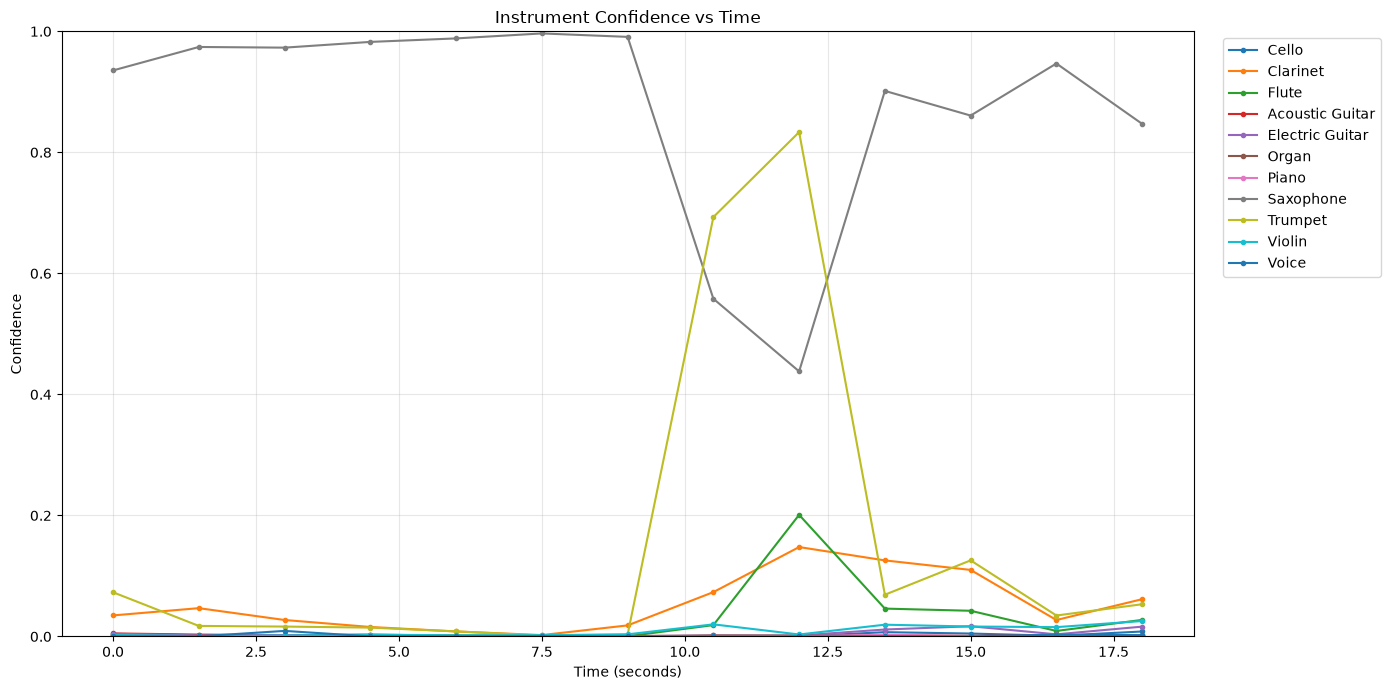

In [111]:
import matplotlib.pyplot as plt

instrument_names = {
    "cel": "Cello",
    "cla": "Clarinet",
    "flu": "Flute",
    "gac": "Acoustic Guitar",
    "gel": "Electric Guitar",
    "org": "Organ",
    "pia": "Piano",
    "sax": "Saxophone",
    "tru": "Trumpet",
    "vio": "Violin",
    "voi": "Voice"
}

file_path = r"E:\Musical Instrument Recognition\IRMAS-TestingData\01 - So What-15.wav"

result = predict_long_audio_final(file_path)

times = result["window_times"]
probabilities = result["window_probabilities"]

plt.figure(figsize=(14, 7))

for i, label in enumerate(class_names):
    plt.plot(
        [start for start, end in times],
        probabilities[:, i],
        marker="o",
        markersize=3,
        label=instrument_names[label]
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Confidence")
plt.title("Instrument Confidence vs Time")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [112]:
for i, layer in enumerate(final_model.layers):
    print(i, layer.name, layer.__class__.__name__, layer.output.shape)

0 conv2d_12 Conv2D (None, 128, 130, 32)
1 batch_normalization_12 BatchNormalization (None, 128, 130, 32)
2 conv2d_13 Conv2D (None, 128, 130, 32)
3 batch_normalization_13 BatchNormalization (None, 128, 130, 32)
4 max_pooling2d_6 MaxPooling2D (None, 64, 65, 32)
5 dropout_8 Dropout (None, 64, 65, 32)
6 conv2d_14 Conv2D (None, 64, 65, 64)
7 batch_normalization_14 BatchNormalization (None, 64, 65, 64)
8 conv2d_15 Conv2D (None, 64, 65, 64)
9 batch_normalization_15 BatchNormalization (None, 64, 65, 64)
10 max_pooling2d_7 MaxPooling2D (None, 32, 32, 64)
11 dropout_9 Dropout (None, 32, 32, 64)
12 conv2d_16 Conv2D (None, 32, 32, 128)
13 batch_normalization_16 BatchNormalization (None, 32, 32, 128)
14 conv2d_17 Conv2D (None, 32, 32, 128)
15 batch_normalization_17 BatchNormalization (None, 32, 32, 128)
16 max_pooling2d_8 MaxPooling2D (None, 16, 16, 128)
17 dropout_10 Dropout (None, 16, 16, 128)
18 global_average_pooling2d_2 GlobalAveragePooling2D (None, 128)
19 dense_4 Dense (None, 128)
20 dropout

In [114]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

grad_input = tf.keras.Input(shape=(128, 130, 1))

x = grad_input

for layer in final_model.layers:
    x = layer(x)
    
    if layer.name == "conv2d_17":
        grad_conv_output = x

grad_model = tf.keras.models.Model(
    inputs=grad_input,
    outputs=[grad_conv_output, x]
)

print("Grad-CAM model created successfully.")
print("Convolutional output shape:", grad_conv_output.shape)
print("Model output shape:", x.shape)

Grad-CAM model created successfully.
Convolutional output shape: (None, 32, 32, 128)
Model output shape: (None, 11)


In [115]:
def make_gradcam(input_image, class_index):

    input_tensor = tf.convert_to_tensor(
        input_image[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(input_tensor)
        class_output = predictions[:, class_index]

    gradients = tape.gradient(class_output, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_gradients = pooled_gradients[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    return heatmap.numpy()

print("Grad-CAM function ready.")

Grad-CAM function ready.


In [116]:
file_path = r"E:\Musical Instrument Recognition\IRMAS-TestingData\01 - So What-15.wav"

y, sr = librosa.load(file_path, sr=22050, mono=True)

window_samples = int(3 * sr)
segment = y[:window_samples]

mel = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_fft=2048,
    hop_length=512,
    n_mels=128,
    window="hann"
)

mel_db = librosa.power_to_db(mel, ref=np.max)
mel_normalized = (mel_db + 80.0) / 80.0

input_image = mel_normalized.astype(np.float32)

sax_index = label_to_index["sax"]

sax_probability = final_model.predict(
    input_image[np.newaxis, ..., np.newaxis],
    verbose=0
)[0][sax_index]

heatmap = make_gradcam(
    input_image,
    sax_index
)

print(f"Saxophone confidence: {sax_probability:.2%}")
print("Input shape:", input_image.shape)
print("Grad-CAM shape:", heatmap.shape)

Saxophone confidence: 93.54%
Input shape: (128, 130)
Grad-CAM shape: (32, 32)


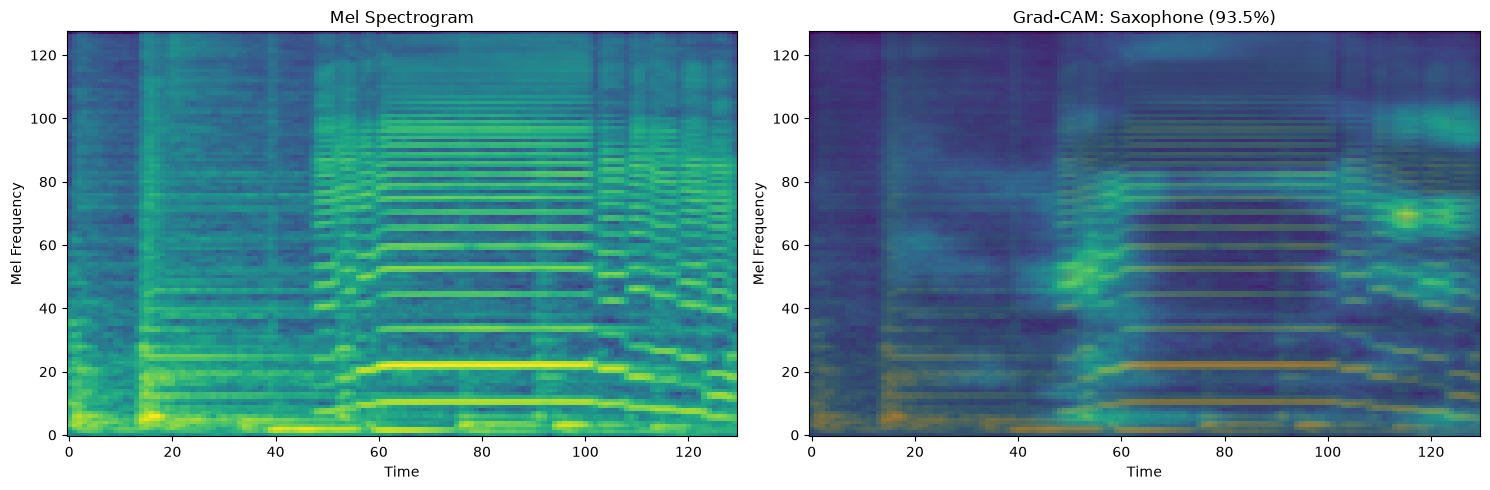

In [118]:
import matplotlib.pyplot as plt

heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (input_image.shape[0], input_image.shape[1])
).numpy().squeeze()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].imshow(
    input_image,
    aspect="auto",
    origin="lower"
)
axes[0].set_title("Mel Spectrogram")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Mel Frequency")

axes[1].imshow(
    input_image,
    aspect="auto",
    origin="lower"
)
axes[1].imshow(
    heatmap_resized,
    aspect="auto",
    origin="lower",
    alpha=0.5
)
axes[1].set_title(
    f"Grad-CAM: Saxophone ({sax_probability:.1%})"
)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Mel Frequency")

plt.tight_layout()
plt.show()

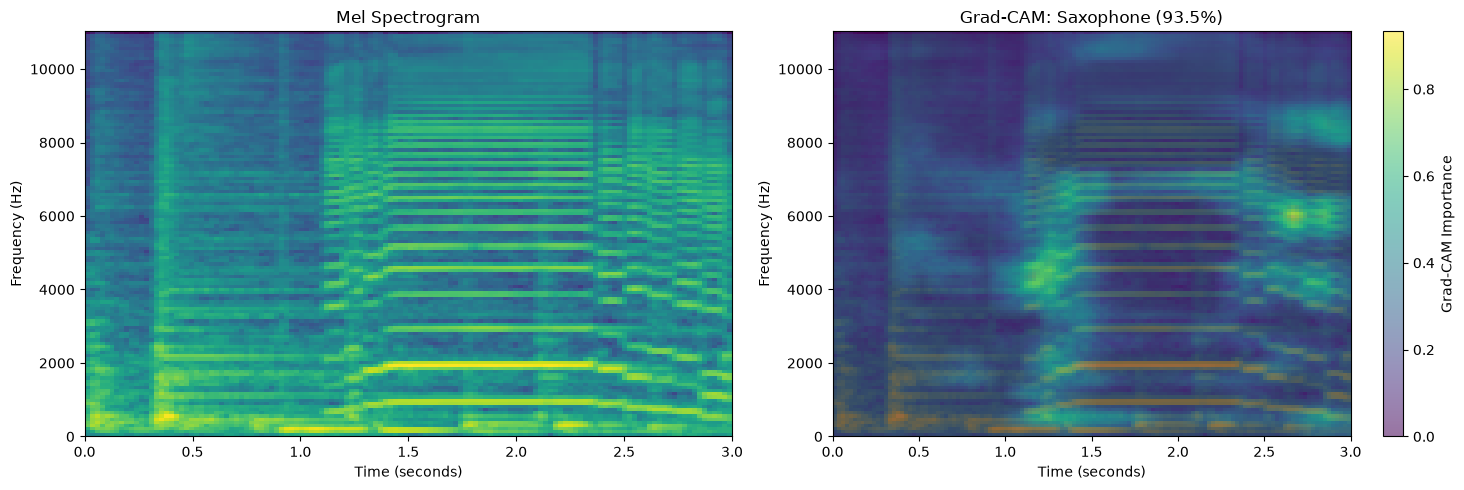

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

duration = 3.0
max_frequency = sr / 2

extent = [
    0,
    duration,
    0,
    max_frequency
]

im1 = axes[0].imshow(
    input_image,
    aspect="auto",
    origin="lower",
    extent=extent
)

axes[0].set_title("Mel Spectrogram")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Frequency (Hz)")

im2 = axes[1].imshow(
    input_image,
    aspect="auto",
    origin="lower",
    extent=extent
)

heatmap_plot = axes[1].imshow(
    heatmap_resized,
    aspect="auto",
    origin="lower",
    extent=extent,
    alpha=0.55
)

axes[1].set_title(
    f"Grad-CAM: Saxophone ({sax_probability:.1%})"
)
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")

cbar = fig.colorbar(
    heatmap_plot,
    ax=axes[1]
)
cbar.set_label("Grad-CAM Importance")

plt.tight_layout()
plt.show()